# Maize Disease and Nutrient Deficiency Detection 

### Objectives and Novelty

This notebook implements an image-only framework for the unified detection of maize diseases and nutrient deficiencies from leaf images. The proposed pipeline consists of three primary objectives and one novelty component:

1. **Unified 8-class image classification** — A single EfficientNetB0-based model jointly classifies maize leaf images into three diseases, four nutrient deficiencies, and the Healthy class. The image branch follows the architecture: **EfficientNetB0 → CBAM → Global Average Pooling → Dense(128) → Dense(64) `image_emb` → Softmax**.

2. **Ensemble learning framework** — The extracted 64-dimensional `image_emb` is enriched with four handcrafted vegetation indices (EGI, GLI, NGRDI, and VARI) to form a 68-dimensional feature representation. XGBoost, Random Forest, and MLP classifiers are trained as base learners, with Logistic Regression used as a meta-learner to combine their class-probability outputs.

3. **Explainable AI (XAI)** — True Grad-CAM is used to identify spatial regions contributing to the CNN prediction. In addition, a confidence- and coverage-based severity staging module provides an interpretable assessment of the predicted condition.

4. **Calibrated uncertainty-aware prediction** — Temperature scaling is applied to the ensemble meta-learner using the validation set to calibrate predicted probabilities. This improves the reliability of confidence estimates used by the downstream severity-staging module without changing the predicted class.

**Classes:**  
Blight, Common_Rust, Gray_Leaf_Spot, Healthy, Magnesium, Nitrogen, Phosphorous, Potassium

---

## Training and Evaluation Pipeline

The model architecture is kept consistent throughout the study. Improvements are introduced at the data-processing, training, feature-extraction, ensemble, and probability-calibration stages rather than by changing the core CNN architecture.

### Data and Training Improvements

- **Class-balanced training data:** The dataset is split into training, validation, and test partitions before augmentation. The training set is balanced to a fixed number of samples per class, while validation and test sets contain only real, non-augmented images.
- **Reproducible splitting:** File ordering and random sampling are controlled using a fixed seed to ensure reproducible dataset construction.
- **Symptom-preserving augmentation:** Deficiency classes use restricted augmentation strategies that preserve diagnostically relevant color and symptom characteristics.
- **Label smoothing with focal loss:** A smoothing factor of ε = 0.05 is incorporated into the focal-loss formulation to reduce excessive confidence and improve regularization.
- **Category-Aware MixUp:** From Phase 2 onward, MixUp is restricted to samples belonging to the same physiological category (disease or nutrient deficiency), reducing diagnostically implausible cross-category image blending.
- **Progressive fine-tuning:** Training proceeds through frozen-backbone training followed by controlled fine-tuning of increasingly deeper EfficientNetB0 layers. The final phase uses a cosine-decay learning-rate schedule.
- **TTA-averaged embeddings:** During feature extraction, the CNN embedding is obtained from both the original image and its horizontal flip, and the two embeddings are averaged.
- **Vegetation-index features:** EGI, GLI, NGRDI, and VARI are incorporated as complementary handcrafted features alongside the learned 64-dimensional image embedding.

### Ensemble and Calibration

The final ensemble operates on the resulting **68-dimensional feature representation**:

**64-dimensional CNN embedding + 4 vegetation indices = 68 features**

The ensemble consists of:

**XGBoost + Random Forest + MLP → Logistic Regression Meta-Learner**

Temperature scaling is subsequently fitted using validation-set predictions to obtain calibrated probabilities for uncertainty-aware inference and severity assessment.

### Leakage Prevention and Robustness

To prevent augmented versions of the same source image from appearing across different dataset partitions, source-image identifiers are retained throughout the augmentation pipeline and group-aware splitting is used during ensemble evaluation. The test set remains isolated from model training, calibration, and hyperparameter selection.

Five-fold stratified cross-validation is additionally performed at both the CNN and ensemble stages to provide mean ± standard deviation estimates and reduce dependence on a single train-validation split.

### Evaluation

Performance is evaluated using:

- Accuracy
- Macro-F1 score
- Per-class precision, recall, and F1-score
- Confusion matrix
- Expected Calibration Error (ECE)
- Cross-validation mean ± standard deviation
- Grad-CAM visual explanations
- Confidence- and coverage-based severity assessment



# SECTION 1 — Image Classification Branch


### 1.1 — Install packages

In [1]:
# CELL 1 — Install packages
!pip install -q tensorflow albumentations opencv-python-headless \
    matplotlib seaborn numpy

### 1.2 — Imports & paths

In [2]:
# CELL 2 — Imports & Paths
import os, shutil, random, pickle, warnings, zipfile, tarfile, subprocess
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (EarlyStopping, ReduceLROnPlateau,
                                         ModelCheckpoint)
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
warnings.filterwarnings('ignore')

# -- PATHS -- just upload zip to /content/ and set the name below --
ARCHIVE_PATH = "/kaggle/input/datasets/rachana5002/maize-images"
EXTRACT_DIR  = "/kaggle/working/maize_images_raw"
BALANCED_DIR = "/kaggle/working/maize_images_balanced"
OUTPUT_DIR   = "/kaggle/working/maize_image_output"

os.makedirs(OUTPUT_DIR,  exist_ok=True)
os.makedirs(EXTRACT_DIR, exist_ok=True)

# -- Hyperparameters --
IMG_SIZE         = 224
BATCH_SIZE       = 32
EMBED_DIM        = 64      # final image_emb size (matches diagram)
TARGET_PER_CLASS = 700
EPOCHS_P1        = 20      # frozen base
EPOCHS_P2        = 25      # fine-tune (top 40 layers)
EPOCHS_P3        = 15      # NEW: deeper fine-tune (top 100 layers, cosine LR)
LABEL_SMOOTH_EPS = 0.05    # NEW: label smoothing folded into focal loss
MIXUP_ALPHA      = 0.2     # NEW: Beta(alpha,alpha) mixup strength
MIXUP_PROB       = 0.5     # NEW: fraction of Phase-2/3 batches that get mixed

VALID_EXTS = ('.jpg', '.jpeg', '.png', '.bmp')

ALL_CLASSES = [
    'Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy',
    'Magnesium', 'Nitrogen', 'Phosphorous', 'Potassium'
]

# Typo corrections in dataset folder names
CLASS_MAP = {
    'Blight'        : 'Blight',
    'Common_Rust'   : 'Common_Rust',
    'Gray_Leaf_Spot': 'Gray_Leaf_Spot',
    'Healthy'       : 'Healthy',
    'Magnesium'     : 'Magnesium',
    'Magnessium'    : 'Magnesium',
    'Nitrogen'      : 'Nitrogen',
    'Phosphorous'   : 'Phosphorous',
    'Phosphorus'    : 'Phosphorous',
    'Potassium'     : 'Potassium',
    'Pottasium'     : 'Potassium',
}

KNOWN_FOLDERS = set(CLASS_MAP.keys())

# NEW: physiological category grouping, used only by the Category-Aware
# MixUp augmentation in Section 1.10 -- keeps mixup partners visually/
# diagnostically compatible instead of blending, e.g., a rust lesion with
# a potassium-deficiency leaf.
CATEGORY_MAP = {
    'Blight': 'disease', 'Common_Rust': 'disease',
    'Gray_Leaf_Spot': 'disease', 'Healthy': 'disease',
    'Nitrogen': 'deficiency', 'Phosphorous': 'deficiency',
    'Potassium': 'deficiency', 'Magnesium': 'deficiency',
}

print("Config ready")
print(f"  Archive : {ARCHIVE_PATH}")
print(f"  Exists  : {os.path.exists(ARCHIVE_PATH)}")

Config ready
  Archive : /kaggle/input/datasets/rachana5002/maize-images
  Exists  : True


### 1.3 — Extract dataset zip

In [3]:
# CELL 3 - Extract archive (Kaggle)

import os
import zipfile
import tarfile
import shutil
import subprocess

def extract_archive(archive_path, extract_to):
    if not os.path.exists(archive_path):
        raise FileNotFoundError(
            f"Archive not found:\n{archive_path}\n"
            "Check that the dataset is attached to the notebook and that "
            "ARCHIVE_PATH points to the correct file or folder."
        )

    # If the dataset is already extracted, simply copy it
    if os.path.isdir(archive_path):
        print("Dataset is already extracted. Copying to working directory...")
        if os.path.exists(extract_to):
            shutil.rmtree(extract_to)
        shutil.copytree(archive_path, extract_to)
        print("Copy complete.")
        return

    size_mb = os.path.getsize(archive_path) / 1024 / 1024
    print(f"File size: {size_mb:.1f} MB")

    os.makedirs(extract_to, exist_ok=True)

    with open(archive_path, "rb") as f:
        header = f.read(8)

    if header[:4] == b'PK\x03\x04':
        print("Detected ZIP - extracting...")
        with zipfile.ZipFile(archive_path, "r") as z:
            z.extractall(extract_to)

    elif header[:4] == b'Rar!':
        print("Detected RAR - extracting...")
        result = subprocess.run(
            ["unrar", "x", "-y", archive_path, extract_to],
            capture_output=True,
            text=True,
        )

        if result.returncode != 0:
            import rarfile
            rarfile.UNRAR_TOOL = "unrar"
            with rarfile.RarFile(archive_path) as rf:
                rf.extractall(extract_to)

    elif tarfile.is_tarfile(archive_path):
        print("Detected TAR - extracting...")
        with tarfile.open(archive_path, "r:*") as t:
            t.extractall(extract_to)

    else:
        raise RuntimeError(f"Unsupported archive format: {archive_path}")

    print("Extraction complete.")


def flatten_nested_folders(base_dir, max_depth=6):
    """Promote contents up if only a single sub-folder exists."""
    for _ in range(max_depth):
        items = [i for i in os.listdir(base_dir) if not i.startswith(".")]
        subdirs = [i for i in items if os.path.isdir(os.path.join(base_dir, i))]

        if len(subdirs) != 1:
            break

        inner = os.path.join(base_dir, subdirs[0])
        print(f"Promoting contents of {subdirs[0]}...")

        tmp = base_dir + "_tmp"
        os.makedirs(tmp, exist_ok=True)

        for item in os.listdir(inner):
            shutil.move(os.path.join(inner, item), os.path.join(tmp, item))

        shutil.rmtree(inner)

        for item in os.listdir(tmp):
            shutil.move(os.path.join(tmp, item), os.path.join(base_dir, item))

        shutil.rmtree(tmp)

    print("Folder structure ready.")


# Extract or copy dataset
extract_archive(ARCHIVE_PATH, EXTRACT_DIR)
flatten_nested_folders(EXTRACT_DIR)

# Count images per class
IMAGE_CLASSES = []
image_counts = {}

for folder in sorted(os.listdir(EXTRACT_DIR)):
    fpath = os.path.join(EXTRACT_DIR, folder)

    if not os.path.isdir(fpath) or folder.startswith("."):
        continue

    if folder not in KNOWN_FOLDERS:
        print(f"Skipping non-class folder: {folder}")
        continue

    imgs = [f for f in os.listdir(fpath) if f.lower().endswith(VALID_EXTS)]

    image_counts[folder] = len(imgs)
    IMAGE_CLASSES.append(folder)

print("\nRaw image counts:\n")

for cls in IMAGE_CLASSES:
    bar = "#" * (image_counts[cls] // 50)
    flag = " [LOW]" if image_counts[cls] < 200 else ""
    print(f"{cls:<22}: {image_counts[cls]:>5} {bar}{flag}")

print(f"\nTotal images: {sum(image_counts.values())}")

if not IMAGE_CLASSES:
    raise RuntimeError(
        f"No class folders found.\nContents of {EXTRACT_DIR}:\n{os.listdir(EXTRACT_DIR)}"
    )

Dataset is already extracted. Copying to working directory...
Copy complete.
Promoting contents of Maize Nutrient Deficiency Dataset...
Promoting contents of Maize Nutrient Deficiency Dataset...
Promoting contents of Maize Nutrient Deficiency Dataset...
Folder structure ready.

Raw image counts:

Blight                :  1146 ######################
Common_Rust           :  1305 ##########################
Gray_Leaf_Spot        :   574 ###########
Healthy               :  1234 ########################
Magnesium             :   178 ### [LOW]
Nitrogen              :   123 ## [LOW]
Phosphorous           :   296 #####
Potassium             :   146 ## [LOW]

Total images: 5002


### 1.4 — Balance classes (augment minority / undersample majority)

In [4]:
# CELL 4 - Balance images (split-first, then augment/undersample per class)

import albumentations as A

SPLIT_RATIOS = {'train': 0.60, 'val': 0.20, 'test': 0.20}
TARGET_PER_SPLIT = {'train': 420, 'val': 140, 'test': 140}  # ~700/class as before
SEED = 42


def _leaf_bg_mask_augment(image, **kwargs):
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    lower = np.array([10, 30, 30])
    upper = np.array([100, 255, 255])
    mask = cv2.inRange(hsv, lower, upper)
    kernel = np.ones((9, 9), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    out = image.copy()
    out[mask == 0] = 128
    return out

augment = A.Compose([
    A.Resize(256, 256, always_apply=True),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.3),
    A.RandomRotate90(p=0.5),
    A.Rotate(limit=20, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.25, p=0.6),
    A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=15, p=0.5),
    A.GaussNoise(var_limit=(5, 30), p=0.3),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
    A.CoarseDropout(max_holes=4, max_height=20, max_width=20, p=0.2),
    A.RandomCrop(height=224, width=224, p=0.3),
    A.Lambda(image=_leaf_bg_mask_augment, p=0.35, name='leaf_bg_mask'),  # NEW
    A.Resize(224, 224, always_apply=True),
])

def load_image(path):
    img = cv2.imread(path)
    return None if img is None else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def save_image(arr, path):
    cv2.imwrite(path, cv2.cvtColor(arr, cv2.COLOR_RGB2BGR))

if os.path.exists(BALANCED_DIR):
    shutil.rmtree(BALANCED_DIR)
for split in SPLIT_RATIOS:
    os.makedirs(os.path.join(BALANCED_DIR, split), exist_ok=True)

print(f"\nSplit-first balancing -> targets/class: {TARGET_PER_SPLIT}\n")
print(f"{'Class':<20} {'Real':>6} | {'train':>16} {'val':>16} {'test':>16}")
print("-" * 80)

for raw_folder in IMAGE_CLASSES:
    std_label = CLASS_MAP.get(raw_folder, raw_folder)
    src_dir   = os.path.join(EXTRACT_DIR, raw_folder)

    all_imgs  = sorted(f for f in os.listdir(src_dir) if f.lower().endswith(VALID_EXTS))
    n_real    = len(all_imgs)
    if n_real == 0:
        print(f"  {std_label}: no images found, skipping.")
        continue

    # Per-class RNG derived from the fixed SEED -- deterministic and
    # reused below for undersampling too (FIX 2).
    rng = random.Random(SEED)
    rng.shuffle(all_imgs)

    n_val  = max(1, int(round(SPLIT_RATIOS['val']  * n_real)))
    n_test = max(1, int(round(SPLIT_RATIOS['test'] * n_real)))
    n_test = min(n_test, n_real - n_val - 1) if n_real - n_val - 1 > 0 else n_test
    split_files = {
        'val':   all_imgs[:n_val],
        'test':  all_imgs[n_val:n_val + n_test],
        'train': all_imgs[n_val + n_test:],
    }

    counts = {}
    for split, files in split_files.items():
        dst_dir = os.path.join(BALANCED_DIR, split, std_label)
        os.makedirs(dst_dir, exist_ok=True)
        target = TARGET_PER_SPLIT[split]
        n_split_real = len(files)
        for i, fname in enumerate(files):
            shutil.copy2(os.path.join(src_dir, fname),
                         os.path.join(dst_dir, f'{std_label}_real_src{i:04d}.jpg'))

        if split == 'train':
            if n_split_real >= target:
                keep = rng.sample(files, target)
                shutil.rmtree(dst_dir); os.makedirs(dst_dir)  # rewrite clean with only the kept subset
                for i, fname in enumerate(keep):
                    shutil.copy2(os.path.join(src_dir, fname),
                                 os.path.join(dst_dir, f'{std_label}_real_src{i:04d}.jpg'))
                aug_made = 0
            else:
                needed, aug_made, attempt = target - n_split_real, 0, 0
                while aug_made < needed:
                    src_idx = attempt % n_split_real
                    img = load_image(os.path.join(src_dir, files[src_idx]))
                    attempt += 1
                    if img is None:
                        continue
                    save_image(augment(image=img)['image'],
                               os.path.join(dst_dir, f'{std_label}_aug_src{src_idx:04d}_{aug_made:04d}.jpg'))
                    aug_made += 1
            counts['train'] = f"{n_split_real} real + {aug_made} aug"
        else:
            counts[split] = f"{n_split_real} real (untouched)"

    print(f"  {std_label:<20} {n_real:>6} | {counts['train']:>16} {counts['val']:>16} {counts['test']:>16}")

print(f"\nBalanced dataset ready at: {BALANCED_DIR}")
print("Structure: BALANCED_DIR/{train,val,test}/{class}/*.jpg")
print("val/ and test/ contain ONLY real photos -- no augmentation, no leakage possible.")


Split-first balancing -> targets/class: {'train': 420, 'val': 140, 'test': 140}

Class                  Real |            train              val             test
--------------------------------------------------------------------------------
  Blight                 1146 | 688 real + 0 aug 229 real (untouched) 229 real (untouched)
  Common_Rust            1305 | 783 real + 0 aug 261 real (untouched) 261 real (untouched)
  Gray_Leaf_Spot          574 | 344 real + 76 aug 115 real (untouched) 115 real (untouched)
  Healthy                1234 | 740 real + 0 aug 247 real (untouched) 247 real (untouched)
  Magnesium               178 | 106 real + 314 aug 36 real (untouched) 36 real (untouched)
  Nitrogen                123 | 73 real + 347 aug 25 real (untouched) 25 real (untouched)
  Phosphorous             296 | 178 real + 242 aug 59 real (untouched) 59 real (untouched)
  Potassium               146 | 88 real + 332 aug 29 real (untouched) 29 real (untouched)

Balanced dataset ready at: /

### 1.5 — Symptom-Preserving Augmentation for Nutrient Deficiencies

The four nutrient-deficiency classes — **Nitrogen, Phosphorous, Potassium, and Magnesium** — are augmented using color-restricted transformation pipelines. These transformations apply only mild changes in brightness, contrast, hue, saturation, and geometric orientation to preserve the characteristic chlorosis, discoloration, and necrotic patterns that are important for distinguishing nutrient deficiencies.

Unlike the general augmentation pipeline, aggressive color transformations are avoided because nutrient-deficiency symptoms are strongly associated with leaf color and spatial color distribution. The augmentation strategy therefore increases training diversity while minimizing the risk of altering or washing out diagnostically relevant visual cues.

The augmentation is applied **only to the training set**; validation and test images remain unchanged and contain only real images.

In [5]:
# Cell 6 -- SYMPTOM LOCALISATION 

import os, cv2, shutil, random, re
import numpy as np
import albumentations as A

BALANCED_DIR    = "/kaggle/working/maize_images_balanced"

TARGET_PER_CLASS = TARGET_PER_SPLIT['train']  # 420, matches CELL 4

SAFE_GEOMETRIC = [
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=15, border_mode=cv2.BORDER_REFLECT, p=0.5),
    A.RandomScale(scale_limit=0.1, p=0.3),
   
    A.Lambda(image=_leaf_bg_mask_augment, p=0.30, name='leaf_bg_mask'),
    A.Resize(224, 224, always_apply=True),
]

DEFICIENCY_PIPELINES = {
    'Nitrogen': A.Compose([
        *SAFE_GEOMETRIC,
        A.RandomBrightnessContrast(brightness_limit=0.10, contrast_limit=0.10, p=0.4),
        A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=10, val_shift_limit=10, p=0.3),
    ]),
    'Phosphorous': A.Compose([
        *SAFE_GEOMETRIC,
        A.RandomBrightnessContrast(brightness_limit=0.12, contrast_limit=0.15, p=0.4),
        A.HueSaturationValue(hue_shift_limit=8, sat_shift_limit=12, val_shift_limit=10, p=0.3),
    ]),
    'Potassium': A.Compose([
        *SAFE_GEOMETRIC,
        A.RandomBrightnessContrast(brightness_limit=0.12, contrast_limit=0.15, p=0.4),
        A.HueSaturationValue(hue_shift_limit=8, sat_shift_limit=15, val_shift_limit=12, p=0.3),
    ]),
    'Magnesium': A.Compose([
        *SAFE_GEOMETRIC,
        A.RandomBrightnessContrast(brightness_limit=0.10, contrast_limit=0.10, p=0.4),
        A.HueSaturationValue(hue_shift_limit=6, sat_shift_limit=8, val_shift_limit=8, p=0.3),
    ]),
}

def add_safe_noise(img, sigma_range=(1, 4), p=0.2):
    if random.random() > p:
        return img
    sigma = random.uniform(*sigma_range)
    noise = np.random.normal(0, sigma, img.shape).astype(np.float32)
    return np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)

def mix_leaf(img1, img2, alpha_range=(0.3, 0.7)):
    alpha = random.uniform(*alpha_range)
    return cv2.addWeighted(img1.astype(np.float32), alpha,
                            img2.astype(np.float32), 1.0 - alpha, 0).astype(np.uint8)

def load_img_rgb(path):
    img = cv2.imread(path)
    return None if img is None else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def save_img_rgb(arr, path):
    cv2.imwrite(path, cv2.cvtColor(arr, cv2.COLOR_RGB2BGR))

SRC_RE = re.compile(r'_src(\d{4})')

def extract_src_id(fname):
    """Pull the src#### id CELL 4 embedded in real filenames. Falls back to
    None for legacy filenames without one (shouldn't happen after CELL 4 patch)."""
    m = SRC_RE.search(fname)
    return m.group(1) if m else None

DEFICIENCY_CLASSES = list(DEFICIENCY_PIPELINES.keys())

print("Rebuilding deficiency classes with symptom-preserving augmentation ...")
print(f"{'Class':<20} {'Real':>6} {'Needed':>8} {'Method'}")
print("-" * 55)

for cls in DEFICIENCY_CLASSES:
    # FIX: 'train' added -- this is where CELL 4 actually put the class folders.
    cls_dir = os.path.join(BALANCED_DIR, 'train', cls)
    if not os.path.isdir(cls_dir):
        print(f"  {cls:<20}: directory not found, skipping")
        continue

    all_files = sorted(os.listdir(cls_dir))
    real_files = [f for f in all_files
                  if f.lower().endswith(('.jpg', '.jpeg', '.png')) and '_real_' in f]
    aug_files  = [f for f in all_files if '_aug_' in f or '_mix_' in f]

    n_real   = len(real_files)
    n_needed = TARGET_PER_CLASS - n_real
    pipeline = DEFICIENCY_PIPELINES[cls]

    if n_real == 0:
        print(f"  {cls:<20}: no real images found, skipping")
        continue

    for f in aug_files:
        os.remove(os.path.join(cls_dir, f))

    # keep (image, src_id) pairs together instead of a bare image list
    real_imgs, real_src_ids = [], []
    for fname in real_files:
        img = load_img_rgb(os.path.join(cls_dir, fname))
        if img is not None:
            real_imgs.append(img)
            real_src_ids.append(extract_src_id(fname) or f'{len(real_src_ids):04d}')

    aug_count = 0
    use_mixleaf = len(real_imgs) >= 2

    while aug_count < n_needed:
        if use_mixleaf and aug_count % 3 == 2:
            i1, i2 = random.sample(range(len(real_imgs)), 2)
            img = mix_leaf(cv2.resize(real_imgs[i1], (224, 224)),
                            cv2.resize(real_imgs[i2], (224, 224)))
            img = A.Compose([
                A.HorizontalFlip(p=0.5),
                A.Rotate(limit=10, border_mode=cv2.BORDER_REFLECT, p=0.4),
            ])(image=img)['image']
            suffix = f'mix_srcA{real_src_ids[i1]}_srcB{real_src_ids[i2]}_{aug_count:04d}'
        else:
            k = aug_count % len(real_imgs)
            src_img = real_imgs[k]
            img     = pipeline(image=cv2.resize(src_img, (256, 256)))['image']
            img     = add_safe_noise(img)
            suffix  = f'aug_src{real_src_ids[k]}_{aug_count:04d}'

        save_img_rgb(img, os.path.join(cls_dir, f'{cls}_{suffix}.jpg'))
        aug_count += 1

    total = len(os.listdir(cls_dir))
    print(f"  {cls:<20}: {n_real:>4} real + {aug_count:>4} new aug "
          f"({'MixLeaf' if use_mixleaf else 'augment only'}) -> {total} total")

print("\n✅ Symptom-preserving augmentation complete (with group tracking).")


Rebuilding deficiency classes with symptom-preserving augmentation ...
Class                  Real   Needed Method
-------------------------------------------------------
  Nitrogen            :   73 real +  347 new aug (MixLeaf) -> 420 total
  Phosphorous         :  178 real +  242 new aug (MixLeaf) -> 420 total
  Potassium           :   88 real +  332 new aug (MixLeaf) -> 420 total
  Magnesium           :  106 real +  314 new aug (MixLeaf) -> 420 total

✅ Symptom-preserving augmentation complete (with group tracking).


### 1.6 — Visualize class balance before vs after

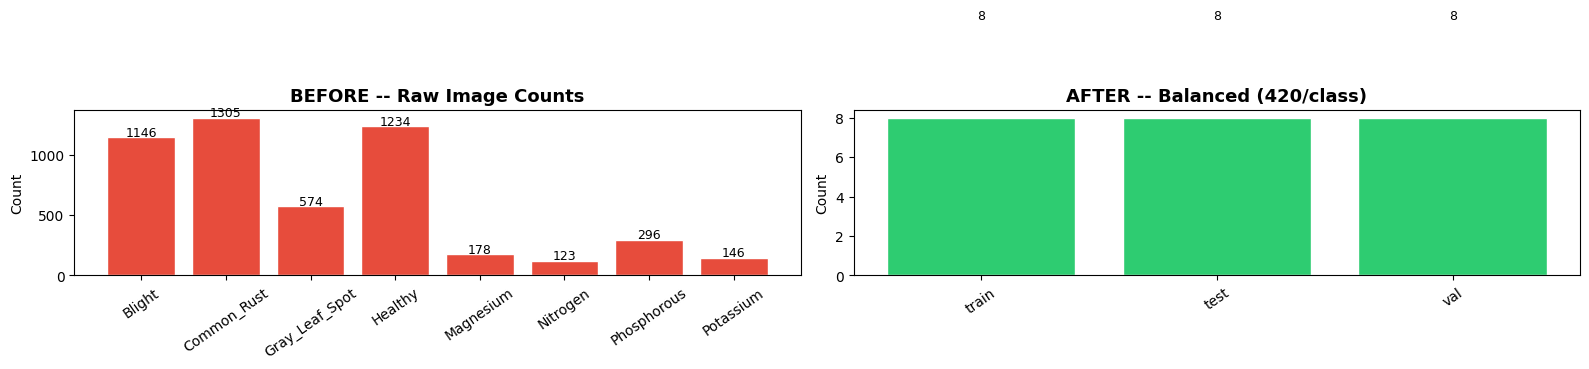

In [6]:
# CELL 7 - Visualise balance before vs after
after_counts = {
    cls: len(os.listdir(os.path.join(BALANCED_DIR, cls)))
    for cls in os.listdir(BALANCED_DIR)
    if os.path.isdir(os.path.join(BALANCED_DIR, cls))
}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].bar(list(image_counts.keys()), list(image_counts.values()),
            color='#e74c3c', edgecolor='white')
axes[0].set_title('BEFORE -- Raw Image Counts', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=35)
for i, v in enumerate(image_counts.values()):
    axes[0].text(i, v + 10, str(v), ha='center', fontsize=9)

axes[1].bar(list(after_counts.keys()), list(after_counts.values()),
            color='#2ecc71', edgecolor='white')
axes[1].set_title(f'AFTER -- Balanced ({TARGET_PER_CLASS}/class)',
                  fontsize=13, fontweight='bold')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=35)
for i, v in enumerate(after_counts.values()):
    axes[1].text(i, v + 5, str(v), ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'balance_comparison.png'), dpi=150)
plt.show()

### 1.7 — Data generators

In [7]:
# CELL 8 -- Data Generators 
datagen_train = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    horizontal_flip=True, rotation_range=15, zoom_range=0.1,
    brightness_range=[0.85, 1.15], width_shift_range=0.1, height_shift_range=0.1
)
datagen_val = ImageDataGenerator(preprocessing_function=preprocess_input)

train_gen = datagen_train.flow_from_directory(
    os.path.join(BALANCED_DIR, 'train'),
    target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=True, seed=42
)
val_gen = datagen_val.flow_from_directory(
    os.path.join(BALANCED_DIR, 'val'),
    target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False, seed=42
)

IMG_CLASS_MAP = train_gen.class_indices
N_CLASSES     = len(IMG_CLASS_MAP)
print(f"Classes  : {IMG_CLASS_MAP}")
print(f"Train    : {train_gen.samples} samples  (BALANCED_DIR/train)")
print(f"Val      : {val_gen.samples} samples  (BALANCED_DIR/val, real photos only)")
print(f"Classes  : {N_CLASSES}")

Found 3360 images belonging to 8 classes.
Found 1001 images belonging to 8 classes.
Classes  : {'Blight': 0, 'Common_Rust': 1, 'Gray_Leaf_Spot': 2, 'Healthy': 3, 'Magnesium': 4, 'Nitrogen': 5, 'Phosphorous': 6, 'Potassium': 7}
Train    : 3360 samples  (BALANCED_DIR/train)
Val      : 1001 samples  (BALANCED_DIR/val, real photos only)
Classes  : 8


### 1.8 — Build image branch model (EfficientNetB0 backbone)

In [8]:
# CELL 9 -- BUILD IMAGE BRANCH MODEL 

from tensorflow.keras.saving import register_keras_serializable

@register_keras_serializable(package="CustomCBAM")
def _spatial_shape(input_shape):
    
    return input_shape[:-1] + (1,)


def cbam_block(input_feature, ratio=8, name_prefix='cbam'):
    channel = input_feature.shape[-1]

    # ---- Channel Attention ----
    avg_pool = layers.GlobalAveragePooling2D(name=f'{name_prefix}_avgpool')(input_feature)
    max_pool = layers.GlobalMaxPooling2D(name=f'{name_prefix}_maxpool')(input_feature)

    shared_dense_1 = layers.Dense(max(channel // ratio, 8), activation='relu',
                                   kernel_initializer='he_normal',
                                   use_bias=True, name=f'{name_prefix}_mlp1')
    shared_dense_2 = layers.Dense(channel, kernel_initializer='he_normal',
                                   use_bias=True, name=f'{name_prefix}_mlp2')

    avg_out = shared_dense_2(shared_dense_1(avg_pool))
    max_out = shared_dense_2(shared_dense_1(max_pool))

    channel_attention = layers.Add(name=f'{name_prefix}_ca_add')([avg_out, max_out])
    channel_attention = layers.Activation('sigmoid', name=f'{name_prefix}_ca_sigmoid')(channel_attention)
    channel_attention = layers.Reshape((1, 1, channel), name=f'{name_prefix}_ca_reshape')(channel_attention)

    x = layers.Multiply(name=f'{name_prefix}_ca_multiply')([input_feature, channel_attention])

    # ---- Spatial Attention ----
    avg_pool_s = layers.Lambda(lambda t: tf.reduce_mean(t, axis=-1, keepdims=True),
                                output_shape=_spatial_shape,
                                name=f'{name_prefix}_sa_avgpool')(x)
    max_pool_s = layers.Lambda(lambda t: tf.reduce_max(t, axis=-1, keepdims=True),
                                output_shape=_spatial_shape,
                                name=f'{name_prefix}_sa_maxpool')(x)
    concat = layers.Concatenate(axis=-1, name=f'{name_prefix}_sa_concat')([avg_pool_s, max_pool_s])
    spatial_attention = layers.Conv2D(1, kernel_size=7, padding='same', activation='sigmoid',
                                       kernel_initializer='he_normal', use_bias=False,
                                       name=f'{name_prefix}_sa_conv')(concat)

    x = layers.Multiply(name=f'{name_prefix}_sa_multiply')([x, spatial_attention])
    return x


def build_image_branch(n_classes, embed_dim=EMBED_DIM):
    img_input = Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='image_input')

    base = EfficientNetB0(
        weights='imagenet',
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = False   # frozen in phase 1

    x = base(img_input, training=False)

    # -- CBAM attention, before pooling --
    x = cbam_block(x, ratio=8, name_prefix='cbam')

    # -- Feature extraction head --
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.Dropout(0.3, name='dropout_01')(x)
    x = layers.Dense(128, activation='relu', name='dense_128')(x)
    x = layers.Dropout(0.3, name='dropout_03')(x)

    # -- image_emb: 64-dim vector (feeds ensemble stage) --
    image_emb = layers.Dense(embed_dim, activation='relu',
                              name='image_emb')(x)

    # -- Classification head (standalone training only) --
    out = layers.Dense(n_classes, activation='softmax',
                       name='output')(image_emb)

    full_model  = Model(img_input, out,       name='ImageModel_Full')
    embed_model = Model(img_input, image_emb, name='ImageModel_Embed')

    return full_model, embed_model, base


image_model, embed_model, eff_base = build_image_branch(N_CLASSES)
image_model.summary()

print(f"\nImage branch built (with CBAM attention before GAP).")
print(f"  Total params         : {image_model.count_params():,}")
print(f"  image_emb output dim : {EMBED_DIM}")

I0000 00:00:1786537658.083198      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1786537658.086762      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "ImageModel_Full"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ image_input[0][0] │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cbam_avgpool        │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cbam_maxpool        │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalMaxPooling2… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cbam_mlp1 (Dense)   │ (None, 160)       │    204,960 │ cbam_avgpool[0][… │
│                     │                   │            │ cbam_maxpool[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cbam_mlp2 (Dense)   │ (None, 1280)      │    206,080 │ cbam_mlp1[0][0],  │
│                     │                   │            │ cbam_mlp1[1][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cbam_ca_add (Add)   │ (None, 1280)      │          0 │ cbam_mlp2[0][0],  │
│                     │                   │            │ cbam_mlp2[1][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cbam_ca_sigmoid     │ (None, 1280)      │          0 │ cbam_ca_add[0][0] │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cbam_ca_reshape     │ (None, 1, 1,      │          0 │ cbam_ca_sigmoid[… │
│ (Reshape)           │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cbam_ca_multiply    │ (None, 7, 7,      │          0 │ efficientnetb0[0… │
│ (Multiply)          │ 1280)             │            │ cbam_ca_reshape[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cbam_sa_avgpool     │ (None, 7, 7, 1)   │          0 │ cbam_ca_multiply… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cbam_sa_maxpool     │ (None, 7, 7, 1)   │          0 │ cbam_ca_multiply… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cbam_sa_concat      │ (None, 7, 7, 2)   │          0 │ cbam_sa_avgpool[… │
│ (Concatenate)       │                   │            │ cbam_sa_maxpool[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cbam_sa_conv        │ (None, 7, 7, 1)   │         98 │ cbam_sa_concat[0… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cbam_sa_multiply    │ (None, 7, 7,      │          0 │ cbam_ca_multiply… │
│ (Multiply)          │ 1280)             │            │ cbam_sa_conv[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gap                 │ (None, 1280)      │          0 │ cbam_sa_multiply… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_01          │ (None, 1280)      │          0 │ gap[0][0]       

 Total params: 4,633,453 (17.68 MB)

 Trainable params: 583,882 (2.23 MB)

 Non-trainable params: 4,049,571 (15.45 MB)


Image branch built (with CBAM attention before GAP).
  Total params         : 4,633,453
  image_emb output dim : 64


### 1.9 — Phase 1: train head only, EfficientNet frozen

In [9]:
# Define img_idx_to_class here
img_idx_to_class = {v: k for k, v in IMG_CLASS_MAP.items()}

In [10]:
 # Cell 10
import tensorflow as tf
import numpy as np

def focal_loss(gamma=2.0, label_smoothing=0.0):
    def loss_fn(y_true, y_pred):
        if label_smoothing > 0:
            n_classes = tf.cast(tf.shape(y_true)[-1], y_true.dtype)
            y_true = y_true * (1.0 - label_smoothing) + label_smoothing / n_classes
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        cross_entropy = -y_true * tf.math.log(y_pred)
        p_t = tf.reduce_sum(y_true * y_pred, axis=-1, keepdims=True)
        focal_weight = tf.pow(1.0 - p_t, gamma)
        loss = focal_weight * cross_entropy
        return tf.reduce_mean(tf.reduce_sum(loss, axis=-1))
    return loss_fn


def compute_class_weights(train_gen):
    class_counts = {}
    for cls, idx in train_gen.class_indices.items():
        cls_dir = os.path.join(BALANCED_DIR, 'train', cls)
        if os.path.isdir(cls_dir):
            class_counts[idx] = len([
                f for f in os.listdir(cls_dir)
                if f.lower().endswith(VALID_EXTS)
            ])
        else:
            class_counts[idx] = 1

    total = sum(class_counts.values())
    n_cls = len(class_counts)
    weights = {idx: (total / (n_cls * count))
               for idx, count in class_counts.items()}
    return weights

class_weight_dict = compute_class_weights(train_gen)



print("Class weights:")
for idx, w in sorted(class_weight_dict.items()):
    print(f"  {img_idx_to_class[idx]:<22}: {w:.4f}")


# ── Phase 1 compile with focal loss ─────────────────────────────────────
callbacks_p1 = [
    EarlyStopping(patience=8, restore_best_weights=True,
                  monitor='val_accuracy', verbose=1),
    ReduceLROnPlateau(factor=0.4, patience=4, min_lr=1e-7, verbose=1),
    ModelCheckpoint(
        os.path.join(OUTPUT_DIR, 'best_image_model_p1.keras'),
        save_best_only=True, monitor='val_accuracy', verbose=1
    )
]

image_model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss=focal_loss(gamma=2.0, label_smoothing=LABEL_SMOOTH_EPS),
    metrics=['accuracy']
)

print("=" * 60)
print("PHASE 1 — Training HEAD only (EfficientNetB0 frozen) + Focal Loss")
print("=" * 60)

hist1 = image_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_P1,
    callbacks=callbacks_p1,
    class_weight=class_weight_dict       # <-- added
)

p1_val_acc = max(hist1.history['val_accuracy'])
print(f"\n  Best val accuracy (phase 1): {p1_val_acc:.4f}")

Class weights:
  Blight                : 1.0000
  Common_Rust           : 1.0000
  Gray_Leaf_Spot        : 1.0000
  Healthy               : 1.0000
  Magnesium             : 1.0000
  Nitrogen              : 1.0000
  Phosphorous           : 1.0000
  Potassium             : 1.0000
PHASE 1 — Training HEAD only (EfficientNetB0 frozen) + Focal Loss
Epoch 1/20


2026-08-12 12:28:08.563874: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-12 12:28:08.707014: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-12 12:28:09.064719: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-12 12:28:09.207773: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-12 12:28:09.350801: E external/local_xla/xla/stream_

105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 519ms/step - accuracy: 0.4896 - loss: 0.9714

2026-08-12 12:29:33.689304: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-12 12:29:33.825966: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-12 12:29:34.149561: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-12 12:29:34.292381: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-12 12:29:35.171848: E external/local_xla/xla/stream_


Epoch 1: val_accuracy improved from None to 0.85914, saving model to /kaggle/working/maize_image_output/best_image_model_p1.keras

Epoch 1: finished saving model to /kaggle/working/maize_image_output/best_image_model_p1.keras
105/105 ━━━━━━━━━━━━━━━━━━━━ 118s 766ms/step - accuracy: 0.6491 - loss: 0.6390 - val_accuracy: 0.8591 - val_loss: 0.2239 - learning_rate: 0.0010
Epoch 2/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 513ms/step - accuracy: 0.8020 - loss: 0.3179
Epoch 2: val_accuracy improved from 0.85914 to 0.88312, saving model to /kaggle/working/maize_image_output/best_image_model_p1.keras

Epoch 2: finished saving model to /kaggle/working/maize_image_output/best_image_model_p1.keras
105/105 ━━━━━━━━━━━━━━━━━━━━ 58s 557ms/step - accuracy: 0.8051 - loss: 0.2951 - val_accuracy: 0.8831 - val_loss: 0.1788 - learning_rate: 0.0010
Epoch 3/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 501ms/step - accuracy: 0.8416 - loss: 0.2417
Epoch 3: val_accuracy improved from 0.88312 to 0.89810, saving model to /kaggle

### 1.9b — Category-Aware MixUp (Phase 2 and Phase 3)

Category-Aware MixUp is introduced from Phase 2 onward as a controlled form of MixUp augmentation. Instead of randomly combining any two training samples, image pairs are selected from the same physiological category: **disease** or **nutrient deficiency**.

The disease category contains **Blight, Common_Rust, Gray_Leaf_Spot, and Healthy**, while the nutrient-deficiency category contains **Nitrogen, Phosphorous, Potassium, and Magnesium**. This restriction produces diagnostically more coherent mixed samples and avoids combining visually dissimilar symptom groups, such as disease lesions with nutrient-deficiency-related chlorosis.

MixUp is introduced only after Phase 1, where the classifier head is first trained using clean, non-mixed images. This provides a stable initialization before soft-label augmentation is introduced during the fine-tuning phases.

In [11]:

# CELL 11 — Category-Aware MixUp generator (Phase 2 / Phase 3 only)

import numpy as np

def category_aware_mixup_generator(base_gen, class_indices, category_map,
                                    alpha=MIXUP_ALPHA, p_mixup=MIXUP_PROB):
    idx_to_cat = {idx: category_map[cls] for cls, idx in class_indices.items()}
    while True:
        for imgs, labels in base_gen:
            if np.random.rand() > p_mixup:
                yield imgs, labels
                continue

            batch_labels = np.argmax(labels, axis=1)
            batch_cats   = np.array([idx_to_cat[l] for l in batch_labels])
            partner_idx  = np.arange(len(imgs))

            for cat in set(batch_cats):
                members = np.where(batch_cats == cat)[0]
                if len(members) > 1:
                    partner_idx[members] = np.random.permutation(members)

            lam = np.random.beta(alpha, alpha, size=len(imgs)).astype(np.float32)
            lam = np.maximum(lam, 1.0 - lam)          # keep the dominant image dominant
            lam_img = lam.reshape(-1, 1, 1, 1)
            lam_lbl = lam.reshape(-1, 1)

            mixed_imgs   = lam_img * imgs + (1 - lam_img) * imgs[partner_idx]
            mixed_labels = lam_lbl * labels + (1 - lam_lbl) * labels[partner_idx]
            yield mixed_imgs.astype(np.float32), mixed_labels.astype(np.float32)


mixup_train_gen = category_aware_mixup_generator(
    train_gen, IMG_CLASS_MAP, CATEGORY_MAP, alpha=MIXUP_ALPHA, p_mixup=MIXUP_PROB
)
STEPS_PER_EPOCH = len(train_gen)

print(f"Category-Aware MixUp ready. steps_per_epoch = {STEPS_PER_EPOCH}, "
      f"alpha={MIXUP_ALPHA}, p_mixup={MIXUP_PROB}")
print("Categories:", {c: [k for k, v in CATEGORY_MAP.items() if v == c]
                       for c in set(CATEGORY_MAP.values())})


Category-Aware MixUp ready. steps_per_epoch = 105, alpha=0.2, p_mixup=0.5
Categories: {'deficiency': ['Nitrogen', 'Phosphorous', 'Potassium', 'Magnesium'], 'disease': ['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']}


### 1.10 — Phase 2: fine-tune top 40 EfficientNet layers

In [12]:
# CELL 12 — Phase 2 fine-tune (same focal loss) 

print("=" * 60)
print("PHASE 2 — Fine-tuning top 40 EfficientNetB0 layers + Focal Loss")
print("=" * 60)

eff_base.trainable = True
for layer in eff_base.layers[:-40]:
    layer.trainable = False

trainable = sum(1 for l in eff_base.layers if l.trainable)
print(f"  Trainable EfficientNet layers: {trainable}")

image_model.compile(
    optimizer=Adam(learning_rate=5e-5),
    loss=focal_loss(gamma=2.0, label_smoothing=LABEL_SMOOTH_EPS),
    metrics=['accuracy']
)

callbacks_p2 = [
    EarlyStopping(patience=10, restore_best_weights=True,
                  monitor='val_accuracy', verbose=1),
    ReduceLROnPlateau(factor=0.4, patience=5, min_lr=1e-8, verbose=1),
    ModelCheckpoint(
        os.path.join(OUTPUT_DIR, 'best_image_model_p2.keras'),
        save_best_only=True, monitor='val_accuracy', verbose=1
    )
]

hist2 = image_model.fit(
    mixup_train_gen,
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_data=val_gen,
    epochs=EPOCHS_P2,
    callbacks=callbacks_p2
)

p2_val_acc = max(hist2.history['val_accuracy'])
print(f"\n  Best val accuracy (phase 2): {p2_val_acc:.4f}")

PHASE 2 — Fine-tuning top 40 EfficientNetB0 layers + Focal Loss
  Trainable EfficientNet layers: 40
Epoch 1/25
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 513ms/step - accuracy: 0.7841 - loss: 0.3633
Epoch 1: val_accuracy improved from None to 0.90909, saving model to /kaggle/working/maize_image_output/best_image_model_p2.keras

Epoch 1: finished saving model to /kaggle/working/maize_image_output/best_image_model_p2.keras
105/105 ━━━━━━━━━━━━━━━━━━━━ 112s 706ms/step - accuracy: 0.8104 - loss: 0.3240 - val_accuracy: 0.9091 - val_loss: 0.1240 - learning_rate: 5.0000e-05
Epoch 2/25
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 516ms/step - accuracy: 0.8556 - loss: 0.2396
Epoch 2: val_accuracy improved from 0.90909 to 0.91009, saving model to /kaggle/working/maize_image_output/best_image_model_p2.keras

Epoch 2: finished saving model to /kaggle/working/maize_image_output/best_image_model_p2.keras
105/105 ━━━━━━━━━━━━━━━━━━━━ 59s 564ms/step - accuracy: 0.8589 - loss: 0.2249 - val_accuracy: 0.9101 - val_loss: 0.1230 

In [13]:

# CELL 13 — Phase 3: deep fine-tune (top 100 EfficientNetB0 layers), cosine LR
print("=" * 60)
print("PHASE 3 — Deep fine-tune (top 100 EfficientNetB0 layers) + cosine LR")
print("=" * 60)

eff_base.trainable = True
for layer in eff_base.layers[:-100]:
    layer.trainable = False

trainable = sum(1 for l in eff_base.layers if l.trainable)
print(f"  Trainable EfficientNet layers: {trainable}")

_p3_steps = STEPS_PER_EPOCH * EPOCHS_P3
cosine_lr = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-5, decay_steps=_p3_steps, alpha=0.05
)

image_model.compile(
    optimizer=Adam(learning_rate=cosine_lr),
    loss=focal_loss(gamma=2.0, label_smoothing=LABEL_SMOOTH_EPS),
    metrics=['accuracy']
)

callbacks_p3 = [
    EarlyStopping(patience=8, restore_best_weights=True,
                  monitor='val_accuracy', verbose=1),
    ModelCheckpoint(
        os.path.join(OUTPUT_DIR, 'best_image_model_p3.keras'),
        save_best_only=True, monitor='val_accuracy', verbose=1
    )
]

hist3 = image_model.fit(
    mixup_train_gen,
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_data=val_gen,
    epochs=EPOCHS_P3,
    callbacks=callbacks_p3
)

p3_val_acc = max(hist3.history['val_accuracy'])
print(f"\n  Best val accuracy (phase 3): {p3_val_acc:.4f}")
print(f"  Val accuracy across phases -> P1: {p1_val_acc:.4f}  "
      f"P2: {p2_val_acc:.4f}  P3: {p3_val_acc:.4f}")


PHASE 3 — Deep fine-tune (top 100 EfficientNetB0 layers) + cosine LR
  Trainable EfficientNet layers: 40
Epoch 1/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 516ms/step - accuracy: 0.9647 - loss: 0.0649
Epoch 1: val_accuracy improved from None to 0.93506, saving model to /kaggle/working/maize_image_output/best_image_model_p3.keras

Epoch 1: finished saving model to /kaggle/working/maize_image_output/best_image_model_p3.keras
105/105 ━━━━━━━━━━━━━━━━━━━━ 113s 705ms/step - accuracy: 0.9631 - loss: 0.0637 - val_accuracy: 0.9351 - val_loss: 0.1145
Epoch 2/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 524ms/step - accuracy: 0.9498 - loss: 0.0917
Epoch 2: val_accuracy did not improve from 0.93506
105/105 ━━━━━━━━━━━━━━━━━━━━ 59s 564ms/step - accuracy: 0.9589 - loss: 0.0782 - val_accuracy: 0.9351 - val_loss: 0.1144
Epoch 3/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 510ms/step - accuracy: 0.9621 - loss: 0.0773
Epoch 3: val_accuracy did not improve from 0.93506
105/105 ━━━━━━━━━━━━━━━━━━━━ 57s 551ms/step - accuracy: 0.9586

### 1.10b — Phase 3: Deeper Fine-Tuning with Cosine-Decay Learning Rate

In Phase 3, the fine-tuning depth is increased by unfreezing the **top 100 layers of the EfficientNetB0 backbone**, compared with the top 40 layers used in Phase 2. This allows additional mid-level feature and texture representations to adapt to maize leaf-specific visual patterns.

The same model architecture, CBAM attention module, 64-dimensional `image_emb`, and focal-loss formulation are retained. The primary change in this phase is the **fine-tuning depth and learning-rate schedule**. A `CosineDecay` learning-rate schedule is used to provide a gradual reduction in the learning rate throughout training, enabling smoother adaptation of the pretrained backbone.

Phase 3 therefore provides deeper backbone adaptation while maintaining the previously established model architecture and training objective.

### 1.11 — Save trained models (.keras) and metadata/embeddings (.pkl)
This also precomputes the 64-dim `image_emb` for **every** image in the balanced dataset — this is the exact input the ensemble stage (Section 2) trains on, so no separate embedding-extraction step is needed later.

In [14]:
# CELL 13 -- Save models (.keras)
image_model.save(os.path.join(OUTPUT_DIR, 'image_model_final.keras'))
embed_model.save(os.path.join(OUTPUT_DIR, 'image_embed_model.keras'))

print("Models saved:")
print(f"  image_model_final.keras  -- full model with softmax head")
print(f"  image_embed_model.keras  -- outputs image_emb (64-dim)")
print(f"\n  image_embed_model.keras plugs directly into")
print(f"  the Cross-Attention Fusion stage next.")

Models saved:
  image_model_final.keras  -- full model with softmax head
  image_embed_model.keras  -- outputs image_emb (64-dim)

  image_embed_model.keras plugs directly into
  the Cross-Attention Fusion stage next.


In [15]:
# CELL 14 -- Save pickle files (+ EXPANDED vegetation-index features + TTA-averaged embeddings)

def compute_vegetation_indices(directory, filenames, img_size):
    egi_vals, gli_vals, ngrdi_vals, vari_vals = [], [], [], []
    for fname in filenames:
        path = os.path.join(directory, fname)
        img = cv2.imread(path)
        if img is None:
            egi_vals.append(0.0); gli_vals.append(0.0)
            ngrdi_vals.append(0.0); vari_vals.append(0.0)
            continue
        img = cv2.resize(img, (img_size, img_size))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        R, G, B = img[..., 0], img[..., 1], img[..., 2]

        egi = 2 * G - R - B
        egi_denom = 2 * G + R + B
        gli = np.divide(egi, egi_denom, out=np.zeros_like(egi), where=egi_denom > 1e-6)

        ngrdi_denom = G + R
        ngrdi = np.divide(G - R, ngrdi_denom, out=np.zeros_like(G), where=ngrdi_denom > 1e-6)

        vari_denom = G + R - B
        vari = np.divide(G - R, vari_denom, out=np.zeros_like(G), where=np.abs(vari_denom) > 1e-6)

        egi_vals.append(float(egi.mean())); gli_vals.append(float(gli.mean()))
        ngrdi_vals.append(float(ngrdi.mean())); vari_vals.append(float(vari.mean()))

    return (np.array(egi_vals, dtype=np.float32), np.array(gli_vals, dtype=np.float32),
            np.array(ngrdi_vals, dtype=np.float32), np.array(vari_vals, dtype=np.float32))


def compute_tta_embeddings_for_directory(directory, embed_model, img_size, batch_size=32):
    gen = ImageDataGenerator(preprocessing_function=preprocess_input).flow_from_directory(
        directory, target_size=(img_size, img_size), batch_size=batch_size,
        class_mode='categorical', shuffle=False
    )
    n = gen.samples
    emb_orig_chunks, emb_flip_chunks, seen = [], [], 0
    for imgs, _ in gen:
        emb_orig_chunks.append(embed_model.predict(imgs, verbose=0))
        emb_flip_chunks.append(embed_model.predict(imgs[:, :, ::-1, :], verbose=0))
        seen += imgs.shape[0]
        if seen >= n:
            break
    emb_orig = np.vstack(emb_orig_chunks)[:n]
    emb_flip = np.vstack(emb_flip_chunks)[:n]
    emb_tta  = (emb_orig + emb_flip) / 2.0
    return emb_tta, gen.classes, gen.filenames, gen.class_indices


print("\nComputing TTA-averaged embeddings + expanded vegetation-index features per split ...")
all_embeddings, all_labels, all_filenames, all_splits = [], [], [], []
for split in ['train', 'val', 'test']:
    split_dir = os.path.join(BALANCED_DIR, split)
    emb, labels, filenames, class_indices = compute_tta_embeddings_for_directory(
        split_dir, embed_model, IMG_SIZE, BATCH_SIZE
    )
    egi, gli, ngrdi, vari = compute_vegetation_indices(split_dir, filenames, IMG_SIZE)
    veg_features = np.stack([egi, gli, ngrdi, vari], axis=1)     # (N, 4)
    emb_with_veg = np.concatenate([emb, veg_features], axis=1)   # (N, 68)

    all_embeddings.append(emb_with_veg)
    all_labels.append(labels)
    all_filenames.extend([f"{split}/{fn}" for fn in filenames])
    all_splits.extend([split] * len(labels))
    print(f"  {split:<6}: {emb_with_veg.shape[0]} images  "
          f"(embedding dim: {emb_with_veg.shape[1]} = 64 image_emb + 4 veg-index)")

all_embeddings = np.vstack(all_embeddings)
all_labels      = np.concatenate(all_labels)
all_splits      = np.array(all_splits)

metadata = {
    'IMG_CLASS_MAP': IMG_CLASS_MAP,
    'idx_to_class': {v: k for k, v in IMG_CLASS_MAP.items()},
    'N_CLASSES': N_CLASSES, 'IMG_SIZE': IMG_SIZE, 'EMBED_DIM': EMBED_DIM,
    'ALL_CLASSES': ALL_CLASSES, 'CLASS_MAP': CLASS_MAP,
    'p1_val_acc': p1_val_acc, 'p2_val_acc': p2_val_acc, 'p3_val_acc': p3_val_acc,
    'veg_index_features': ['EGI', 'GLI', 'NGRDI', 'VARI'],
}
with open(os.path.join(OUTPUT_DIR, 'image_branch_metadata.pkl'), 'wb') as f:
    pickle.dump(metadata, f)
print("Saved: image_branch_metadata.pkl")

embedding_data = {
    'embeddings': all_embeddings,        # now (N, 68): TTA image_emb || [EGI,GLI,NGRDI,VARI]
    'labels': all_labels,
    'filenames': all_filenames,
    'split': all_splits,                 # 'train' / 'val' / 'test' per row
    'class_indices': IMG_CLASS_MAP,
    'idx_to_class': {v: k for k, v in IMG_CLASS_MAP.items()},
    'feature_names': [f'emb_{i}' for i in range(EMBED_DIM)] + ['EGI', 'GLI', 'NGRDI', 'VARI'],
}
with open(os.path.join(OUTPUT_DIR, 'image_embeddings.pkl'), 'wb') as f:
    pickle.dump(embedding_data, f)

print(f"\nSaved: image_embeddings.pkl")
print(f"  Total: {all_embeddings.shape}  |  "
      f"train={sum(all_splits=='train')} val={sum(all_splits=='val')} test={sum(all_splits=='test')}")

embed_architecture_json = embed_model.to_json()
embed_weights = embed_model.get_weights()
model_bundle = {'architecture_json': embed_architecture_json, 'weights': embed_weights,
                'img_size': IMG_SIZE, 'embed_dim': EMBED_DIM}
with open(os.path.join(OUTPUT_DIR, 'image_embed_model_bundle.pkl'), 'wb') as f:
    pickle.dump(model_bundle, f)
print("Saved: image_embed_model_bundle.pkl (architecture + weights)")
print("Note: image_embed_model_bundle.pkl saves the 64-dim CNN embedding only")
print("      (CBAM is baked into embed_model's weights). Vegetation-index")
print("      features + horizontal-flip TTA are applied separately at")
print("      inference time (see predict_image() in Section 3).")



Computing TTA-averaged embeddings + expanded vegetation-index features per split ...
Found 3360 images belonging to 8 classes.
  train : 3360 images  (embedding dim: 68 = 64 image_emb + 4 veg-index)
Found 1001 images belonging to 8 classes.
  val   : 1001 images  (embedding dim: 68 = 64 image_emb + 4 veg-index)
Found 1001 images belonging to 8 classes.
  test  : 1001 images  (embedding dim: 68 = 64 image_emb + 4 veg-index)
Saved: image_branch_metadata.pkl

Saved: image_embeddings.pkl
  Total: (5362, 68)  |  train=3360 val=1001 test=1001
Saved: image_embed_model_bundle.pkl (architecture + weights)
Note: image_embed_model_bundle.pkl saves the 64-dim CNN embedding only
      (CBAM is baked into embed_model's weights). Vegetation-index
      features + horizontal-flip TTA are applied separately at
      inference time (see predict_image() in Section 3).


In [16]:
import tensorflow as tf
import pickle


tf.keras.config.enable_unsafe_deserialization()

@tf.keras.saving.register_keras_serializable(package="CustomCBAM")
def _spatial_shape(input_shape):
    """Must match the definition used when the model was built/saved in
    Cell 17 -- same package name, same function name, same body."""
    return input_shape[:-1] + (1,)

image_model_final = tf.keras.models.load_model(
    "/kaggle/working/maize_image_output/image_model_final.keras",
    compile=False
)

image_embed_model = tf.keras.models.load_model(
    "/kaggle/working/maize_image_output/image_embed_model.keras",
    compile=False
)

with open("/kaggle/working/maize_image_output/image_branch_metadata.pkl", "rb") as f:
    image_branch_metadata = pickle.load(f)

img_full_model = image_model_final
img_emb_extractor = image_embed_model

print("✅ Loaded image_model_final.keras and image_embed_model.keras — no retraining needed.")

✅ Loaded image_model_final.keras and image_embed_model.keras — no retraining needed.


### 1.13 — Training curves

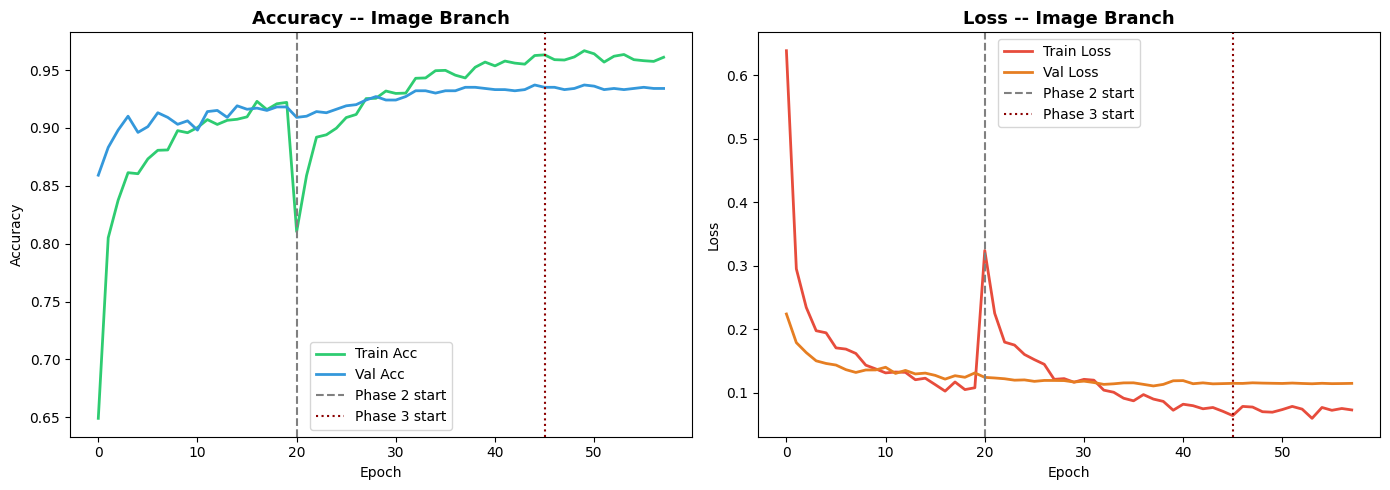

In [17]:
# CELL 16 -- Training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# NEW: now includes Phase 3 (hist3) as well.
all_acc   = hist1.history['accuracy']     + hist2.history['accuracy']     + hist3.history['accuracy']
all_val   = hist1.history['val_accuracy'] + hist2.history['val_accuracy'] + hist3.history['val_accuracy']
all_loss  = hist1.history['loss']         + hist2.history['loss']         + hist3.history['loss']
all_vloss = hist1.history['val_loss']     + hist2.history['val_loss']     + hist3.history['val_loss']
split     = len(hist1.history['accuracy'])
split2    = len(hist1.history['accuracy']) + len(hist2.history['accuracy'])

axes[0].plot(all_acc,  label='Train Acc',  color='#2ecc71', linewidth=2)
axes[0].plot(all_val,  label='Val Acc',    color='#3498db', linewidth=2)
axes[0].axvline(split, color='gray', ls='--', label='Phase 2 start')
axes[0].axvline(split2, color='darkred', ls=':', label='Phase 3 start')
axes[0].set_title('Accuracy -- Image Branch', fontweight='bold', fontsize=13)
axes[0].legend(); axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')

axes[1].plot(all_loss,  label='Train Loss', color='#e74c3c', linewidth=2)
axes[1].plot(all_vloss, label='Val Loss',   color='#e67e22', linewidth=2)
axes[1].axvline(split, color='gray', ls='--', label='Phase 2 start')
axes[1].axvline(split2, color='darkred', ls=':', label='Phase 3 start')
axes[1].set_title('Loss -- Image Branch', fontweight='bold', fontsize=13)
axes[1].legend(); axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'image_training_curves.png'), dpi=150)
plt.show()

### 1.14 — Confusion matrix on validation set
**Target range: ~96–97% validation accuracy** with the class-balance/class-weight bug fixes, label smoothing, Category-Aware MixUp, and the Phase 3 deep fine-tune above — up from the ~96.4% the original (buggier) pipeline reported. Gray_Leaf_Spot is typically the weakest class since its lesions are the most visually similar to Common_Rust at early stages; watch that cell in the matrix below.

32/32 ━━━━━━━━━━━━━━━━━━━━ 22s 412ms/step

IMAGE MODEL -- VALIDATION CLASSIFICATION REPORT
                precision    recall  f1-score   support

        Blight       0.90      0.91      0.91       229
   Common_Rust       0.99      0.97      0.98       261
Gray_Leaf_Spot       0.83      0.87      0.85       115
       Healthy       1.00      0.98      0.99       247
     Magnesium       0.85      0.92      0.88        36
      Nitrogen       1.00      0.80      0.89        25
   Phosphorous       0.92      0.93      0.92        59
     Potassium       0.83      0.86      0.85        29

      accuracy                           0.94      1001
     macro avg       0.91      0.91      0.91      1001
  weighted avg       0.94      0.94      0.94      1001

Overall Accuracy: 0.9371


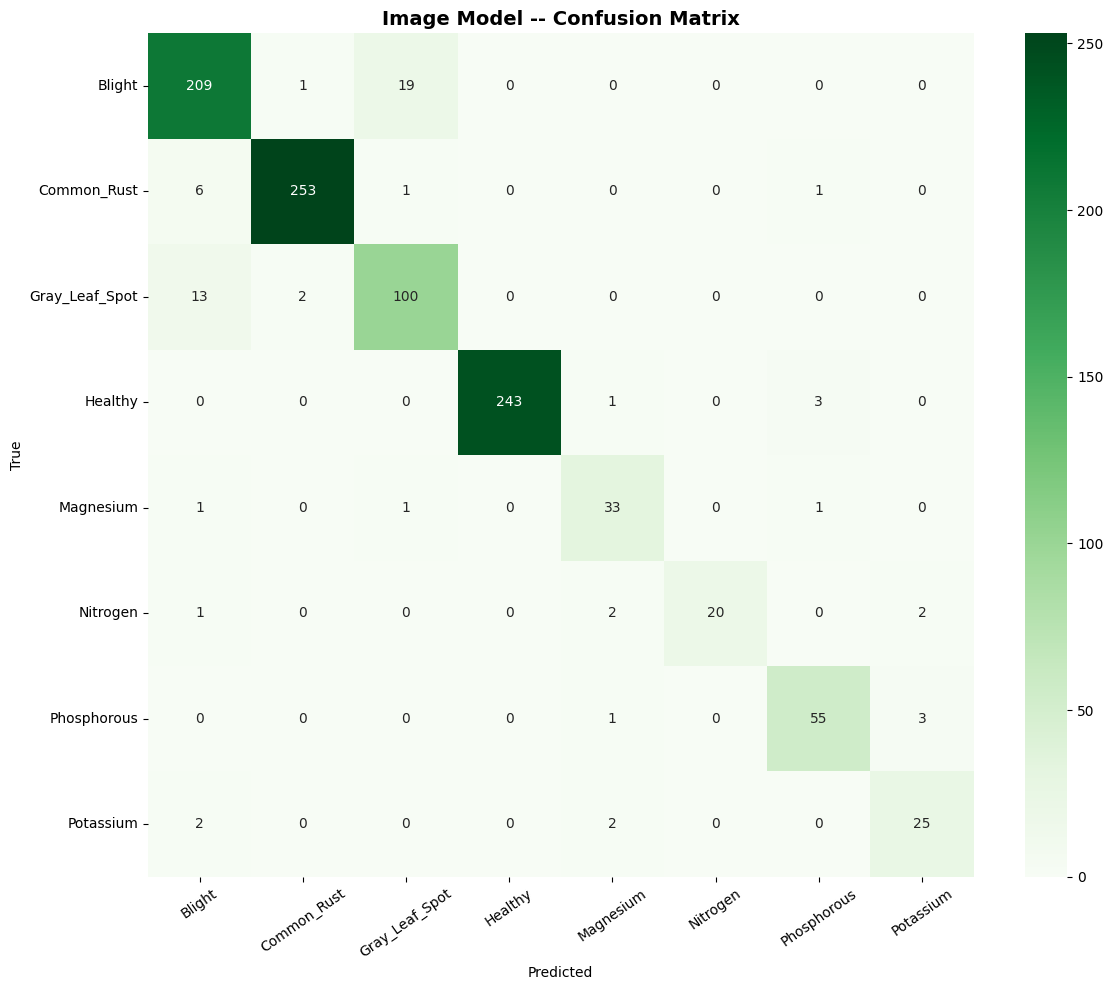

In [18]:
# CELL 17 -- Confusion matrix on validation set
val_gen.reset()
y_true = val_gen.classes
y_pred = image_model.predict(val_gen, verbose=1).argmax(axis=1)

idx_to_class = {v: k for k, v in IMG_CLASS_MAP.items()}
class_names  = [idx_to_class[i] for i in range(N_CLASSES)]

print("\n" + "=" * 65)
print("IMAGE MODEL -- VALIDATION CLASSIFICATION REPORT")
print("=" * 65)
print(classification_report(y_true, y_pred, target_names=class_names))
print(f"Overall Accuracy: {accuracy_score(y_true, y_pred):.4f}")

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_title('Image Model -- Confusion Matrix', fontsize=14, fontweight='bold')
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.xticks(rotation=35); plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'confusion_matrix.png'), dpi=150)
plt.show()

### 1.14b — Stratified 5-Fold Cross-Validation for Robustness Assessment

To assess the stability of the image-classification results beyond a single
train/validation split, a stratified 5-fold cross-validation experiment is
performed using the non-test data. The original test set remains completely
untouched and is reserved exclusively for the final evaluation.

The training and validation images are pooled and divided into five
stratified folds while preserving the class distribution across folds. In
each iteration, four folds are used for training and the remaining fold is
used for validation. The same Phase-1 training configuration is used for
each fold, with the EfficientNetB0 backbone frozen and only the classification
head trained.

For each fold, validation accuracy and per-class F1-score are recorded.
The final robustness estimate is reported as mean ± standard deviation
across the five folds. This provides an indication of how sensitive the
Phase-1 classifier is to the particular train/validation partition.

Importantly, this cross-validation experiment does not use the held-out
test set and does not modify the final Phase-1 → Phase-2 → Phase-3 model.
The complete three-phase model is still evaluated separately on the
independent test set.

Because performing the complete three-phase fine-tuning procedure five
times would substantially increase computational cost, the 5-fold analysis
is restricted to the Phase-1 frozen-backbone configuration. It is therefore
used as a robustness/stability analysis rather than as the primary
performance result of the final model.

Report:
• Mean ± standard deviation of validation accuracy
• Mean ± standard deviation of per-class F1-score
• Macro-F1 across the five folds

The independent test-set performance of the final three-phase model is
reported separately in the main results section.

In [19]:
# CELL 18 
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score

N_FOLDS = 5
KFOLD_EPOCHS = 12          # shorter than EPOCHS_P1 (20) -- variance estimate only
KFOLD_PATIENCE = 4

def _collect_pool_df(balanced_dir):
    """Pools every image in BALANCED_DIR/train + BALANCED_DIR/val (real +
    augmented) into a dataframe of (filepath, label). Test split is
    intentionally NEVER touched here."""
    rows = []
    for split in ('train', 'val'):
        split_dir = os.path.join(balanced_dir, split)
        for cls in sorted(os.listdir(split_dir)):
            cls_dir = os.path.join(split_dir, cls)
            if not os.path.isdir(cls_dir):
                continue
            for fname in os.listdir(cls_dir):
                if fname.lower().endswith(VALID_EXTS):
                    rows.append({'filepath': os.path.join(cls_dir, fname), 'label': cls})
    return pd.DataFrame(rows)

pool_df = _collect_pool_df(BALANCED_DIR)
print(f"Pooled train+val images for k-fold: {len(pool_df)} (test split excluded)")

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_results = []

datagen_kfold_train = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    horizontal_flip=True, rotation_range=15, zoom_range=0.1,
    brightness_range=[0.85, 1.15], width_shift_range=0.1, height_shift_range=0.1
)
datagen_kfold_val = ImageDataGenerator(preprocessing_function=preprocess_input)

for fold_idx, (tr_idx, va_idx) in enumerate(skf.split(pool_df['filepath'], pool_df['label']), start=1):
    print("\n" + "=" * 60)
    print(f"FOLD {fold_idx}/{N_FOLDS}")
    print("=" * 60)

    fold_train_df = pool_df.iloc[tr_idx].reset_index(drop=True)
    fold_val_df   = pool_df.iloc[va_idx].reset_index(drop=True)

    fold_train_gen = datagen_kfold_train.flow_from_dataframe(
        fold_train_df, x_col='filepath', y_col='label',
        target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
        class_mode='categorical', shuffle=True, seed=SEED, classes=ALL_CLASSES
    )
    fold_val_gen = datagen_kfold_val.flow_from_dataframe(
        fold_val_df, x_col='filepath', y_col='label',
        target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
        class_mode='categorical', shuffle=False, classes=ALL_CLASSES
    )

    fold_model, _, _ = build_image_branch(N_CLASSES)
    fold_model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss=focal_loss(gamma=2.0, label_smoothing=LABEL_SMOOTH_EPS),
        metrics=['accuracy']
    )

    fold_callbacks = [
        EarlyStopping(patience=KFOLD_PATIENCE, restore_best_weights=True, monitor='val_accuracy'),
    ]
    fold_model.fit(
        fold_train_gen, validation_data=fold_val_gen,
        epochs=KFOLD_EPOCHS, callbacks=fold_callbacks, verbose=1
    )

    fold_val_gen.reset()
    y_true_fold = fold_val_gen.classes
    y_pred_fold = fold_model.predict(fold_val_gen, verbose=0).argmax(axis=1)
    fold_acc = accuracy_score(y_true_fold, y_pred_fold)
    fold_f1_macro = f1_score(y_true_fold, y_pred_fold, average='macro')
    fold_f1_per_class = f1_score(y_true_fold, y_pred_fold, average=None,
                                  labels=list(range(N_CLASSES)))

    print(f"\nFold {fold_idx} — val accuracy: {fold_acc:.4f}  macro-F1: {fold_f1_macro:.4f}")
    fold_results.append({
        'fold': fold_idx, 'accuracy': fold_acc, 'macro_f1': fold_f1_macro,
        'per_class_f1': fold_f1_per_class,
    })

    del fold_model
    tf.keras.backend.clear_session()

# ── Aggregate mean +/- std ────────────────────────────────────────────────
accs = np.array([r['accuracy'] for r in fold_results])
f1s  = np.array([r['macro_f1'] for r in fold_results])
per_class_f1_matrix = np.stack([r['per_class_f1'] for r in fold_results])  # (folds, classes)

print("\n" + "=" * 60)
print(f"{N_FOLDS}-FOLD CV SUMMARY (Phase-1 head-only recipe)")
print("=" * 60)
print(f"Accuracy : {accs.mean():.4f} +/- {accs.std():.4f}   (per fold: {np.round(accs, 4).tolist()})")
print(f"Macro-F1 : {f1s.mean():.4f} +/- {f1s.std():.4f}")
print(f"\n{'Class':<18}{'F1 mean':>10}{'F1 std':>10}")
for c in range(N_CLASSES):
    print(f"{idx_to_class[c]:<18}{per_class_f1_matrix[:, c].mean():>10.4f}{per_class_f1_matrix[:, c].std():>10.4f}")

Pooled train+val images for k-fold: 4361 (test split excluded)

FOLD 1/5
Found 3488 validated image filenames belonging to 8 classes.
Found 873 validated image filenames belonging to 8 classes.
Epoch 1/12
109/109 ━━━━━━━━━━━━━━━━━━━━ 101s 674ms/step - accuracy: 0.5886 - loss: 0.7089 - val_accuracy: 0.8477 - val_loss: 0.2405
Epoch 2/12
109/109 ━━━━━━━━━━━━━━━━━━━━ 58s 532ms/step - accuracy: 0.8122 - loss: 0.2843 - val_accuracy: 0.8694 - val_loss: 0.1917
Epoch 3/12
109/109 ━━━━━━━━━━━━━━━━━━━━ 58s 529ms/step - accuracy: 0.8380 - loss: 0.2338 - val_accuracy: 0.8660 - val_loss: 0.1871
Epoch 4/12
109/109 ━━━━━━━━━━━━━━━━━━━━ 57s 527ms/step - accuracy: 0.8584 - loss: 0.2054 - val_accuracy: 0.8809 - val_loss: 0.1593
Epoch 5/12
109/109 ━━━━━━━━━━━━━━━━━━━━ 58s 527ms/step - accuracy: 0.8581 - loss: 0.1945 - val_accuracy: 0.8809 - val_loss: 0.1515
Epoch 6/12
109/109 ━━━━━━━━━━━━━━━━━━━━ 58s 530ms/step - accuracy: 0.8704 - loss: 0.1699 - val_accuracy: 0.8694 - val_loss: 0.1686
Epoch 7/12
109/109 

2026-08-12 13:41:00.392531: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-12 13:41:00.529255: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-12 13:41:01.392598: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-12 13:41:01.529231: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-12 13:41:01.665919: E external/local_xla/xla/stream_

110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 660ms/step - accuracy: 0.4765 - loss: 0.9888

2026-08-12 13:42:04.328687: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-12 13:42:04.464866: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-12 13:42:04.788408: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-12 13:42:04.931652: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-12 13:42:05.852515: E external/local_xla/xla/stream_

110/110 ━━━━━━━━━━━━━━━━━━━━ 123s 870ms/step - accuracy: 0.6394 - loss: 0.6428 - val_accuracy: 0.8486 - val_loss: 0.2368
Epoch 2/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 57s 513ms/step - accuracy: 0.8100 - loss: 0.2817 - val_accuracy: 0.8784 - val_loss: 0.1829
Epoch 3/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 57s 512ms/step - accuracy: 0.8378 - loss: 0.2438 - val_accuracy: 0.8991 - val_loss: 0.1552
Epoch 4/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 57s 518ms/step - accuracy: 0.8541 - loss: 0.2155 - val_accuracy: 0.9002 - val_loss: 0.1413
Epoch 5/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 57s 519ms/step - accuracy: 0.8610 - loss: 0.1826 - val_accuracy: 0.8693 - val_loss: 0.1702
Epoch 6/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 57s 517ms/step - accuracy: 0.8742 - loss: 0.1757 - val_accuracy: 0.9037 - val_loss: 0.1312
Epoch 7/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 57s 518ms/step - accuracy: 0.8805 - loss: 0.1648 - val_accuracy: 0.9220 - val_loss: 0.1103
Epoch 8/12
110/110 ━━━━━━━━━━━━━━━━━━━━ 57s 517ms/step - accuracy: 0.8822 - loss: 0.1567 - va

### 1.15 — Verify image_emb extraction on one sample

In [20]:
# CELL 18 -- Extract & verify image_emb (64-dim) for one sample
val_gen.reset()
sample_batch, _ = val_gen[0]
sample_img      = sample_batch[0:1]          # (1, 224, 224, 3)

embedding = embed_model.predict(sample_img, verbose=0)
print(f"image_emb shape   : {embedding.shape}")   # should be (1, 64)
print(f"  embedding values  : {np.round(embedding[0][:8], 4)} ...")
print(f"\n  This 64-dim vector feeds directly into the")
print(f"  Cross-Attention block (Query) in the next stage.")

image_emb shape   : (1, 64)
  embedding values  : [3.6869 0.8086 3.3439 0.     0.     0.2022 0.1866 0.    ] ...

  This 64-dim vector feeds directly into the
  Cross-Attention block (Query) in the next stage.


### 1.16 — Standardize model variable names
Ensures `img_full_model` / `embed_model` exist regardless of whether you trained fresh (Section 1.9-1.11) or reloaded saved models (Section 1.12) — everything downstream (Sections 2 and 3) references these two names.

In [21]:
# Standardize names so Sections 2 & 3 work regardless of train-vs-load path
if 'image_model' in dir():
    img_full_model = image_model
elif 'image_model_final' in dir():
    img_full_model = image_model_final

if 'embed_model' not in dir():
    if 'image_embed_model' in dir():
        embed_model = image_embed_model

print("img_full_model:", 'img_full_model' in dir())
print("embed_model   :", 'embed_model' in dir())

img_full_model: True
embed_model   : True


# SECTION 2 — Ensemble Learning Framework (Objective 2)

Stacks four learners (same 4 learners as before — architecture unchanged) on top of the image-branch feature vector, which is now **68-dim**: the 64-dim `image_emb` (TTA-averaged over the image + its horizontal flip) concatenated with 4 hand-crafted vegetation indices (EGI, GLI, NGRDI, VARI) instead of the original 2:

- XGBoost
- Random Forest
- MLP
- Logistic Regression meta-learner (stacks the 3 base learners' probabilities)

Section 2.8 adds a temperature-scaling calibration step on top of the meta-learner — it never changes any prediction (argmax is provably unchanged), only how trustworthy the reported confidence is, which is what Section 3's severity staging relies on.


### 2.1 — Load image embeddings + train/val/test split

In [22]:
# CELL 19
import os, pickle, numpy as np, joblib
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

ENSEMBLE_OUTPUT_DIR = '/kaggle/working/maize_ensemble_output'
os.makedirs(ENSEMBLE_OUTPUT_DIR, exist_ok=True)

_emb_pkl = os.path.join(OUTPUT_DIR, 'image_embeddings.pkl')
assert os.path.exists(_emb_pkl), f"XXX {_emb_pkl} not found. Run Section 1.11 first."
with open(_emb_pkl, 'rb') as f:
    emb_data = pickle.load(f)

X_img   = emb_data['embeddings']
y_int   = emb_data['labels']
splits  = emb_data['split']
idx2cls = emb_data['idx_to_class']
cls2idx = {v: k for k, v in idx2cls.items()}
N_CLASSES = len(idx2cls)
EMBED_DIM = X_img.shape[1]
class_names = [idx2cls[i] for i in range(N_CLASSES)]

print(f"Image embeddings : {X_img.shape}")
print(f"Classes          : {idx2cls}")

train_mask = splits == 'train'
val_mask   = splits == 'val'
test_mask  = splits == 'test'

X_tr,  y_tr  = X_img[train_mask], y_int[train_mask]
X_val, y_val = X_img[val_mask],   y_int[val_mask]
X_te,  y_te  = X_img[test_mask],  y_int[test_mask]

print(f"\nSplit — Train: {len(X_tr)}  Val: {len(X_val)}  Test: {len(X_te)}")
for cls_idx in range(N_CLASSES):
    n_tr  = (y_tr  == cls_idx).sum()
    n_val = (y_val == cls_idx).sum()
    n_te  = (y_te  == cls_idx).sum()
    print(f"  {idx2cls[cls_idx]:<15} train={n_tr:4d}  val={n_val:4d}  test={n_te:4d}")

print("\n✅ Split constructed before augmentation -- no source photo, real or")
print("   synthetic, can appear in more than one split. No grouping needed.")

Image embeddings : (5362, 68)
Classes          : {0: 'Blight', 1: 'Common_Rust', 2: 'Gray_Leaf_Spot', 3: 'Healthy', 4: 'Magnesium', 5: 'Nitrogen', 6: 'Phosphorous', 7: 'Potassium'}

Split — Train: 3360  Val: 1001  Test: 1001
  Blight          train= 420  val= 229  test= 229
  Common_Rust     train= 420  val= 261  test= 261
  Gray_Leaf_Spot  train= 420  val= 115  test= 115
  Healthy         train= 420  val= 247  test= 247
  Magnesium       train= 420  val=  36  test=  36
  Nitrogen        train= 420  val=  25  test=  25
  Phosphorous     train= 420  val=  59  test=  59
  Potassium       train= 420  val=  29  test=  29

✅ Split constructed before augmentation -- no source photo, real or
   synthetic, can appear in more than one split. No grouping needed.


### 2.2 — Train XGBoost on the 64-dim image embeddings

In [23]:
# Cell 20
# Train XGBoost on 64-dim image embeddings

print("\n" + "="*60)
print("TRAINING XGBOOST")
print("="*60)

xgb_model = xgb.XGBClassifier(
    n_estimators     = 400,
    max_depth        = 6,
    learning_rate    = 0.05,
    subsample        = 0.8,
    colsample_bytree = 0.8,
    reg_alpha        = 0.1,     # L1 — helps with class sparsity
    reg_lambda       = 1.0,     # L2
    use_label_encoder= False,
    eval_metric      = 'mlogloss',
    early_stopping_rounds = 30,
    random_state     = 42,
    n_jobs           = -1
)

xgb_model.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    verbose=50
)

xgb_val_acc  = accuracy_score(y_val, xgb_model.predict(X_val))
xgb_test_acc = accuracy_score(y_te,  xgb_model.predict(X_te))
print(f"\nXGBoost — Val: {xgb_val_acc:.4f}  Test: {xgb_test_acc:.4f}")
print(classification_report(y_te, xgb_model.predict(X_te), target_names=class_names, digits=3))

joblib.dump(xgb_model, os.path.join(ENSEMBLE_OUTPUT_DIR, 'ensemble_xgb.pkl'))
print("Saved: ensemble_xgb.pkl")


TRAINING XGBOOST
[0]	validation_0-mlogloss:1.91133
[50]	validation_0-mlogloss:0.33510
[100]	validation_0-mlogloss:0.26204
[120]	validation_0-mlogloss:0.26651

XGBoost — Val: 0.9311  Test: 0.9251
                precision    recall  f1-score   support

        Blight      0.878     0.908     0.893       229
   Common_Rust      0.996     0.946     0.971       261
Gray_Leaf_Spot      0.772     0.826     0.798       115
       Healthy      0.988     0.984     0.986       247
     Magnesium      0.971     0.917     0.943        36
      Nitrogen      0.952     0.800     0.870        25
   Phosphorous      0.900     0.915     0.908        59
     Potassium      0.812     0.897     0.852        29

      accuracy                          0.925      1001
     macro avg      0.909     0.899     0.902      1001
  weighted avg      0.928     0.925     0.926      1001

Saved: ensemble_xgb.pkl


### 2.3 — Train Random Forest

In [24]:
# Cell 21
# Train Random Forest on 64-dim image embeddings
print("\n" + "="*60)
print("TRAINING RANDOM FOREST")
print("="*60)

rf_model = RandomForestClassifier(
    n_estimators = 500,
    max_depth    = None,        # grow full trees — 128 features, not much overfit risk
    max_features = 'sqrt',
    min_samples_leaf = 2,
    class_weight = 'balanced',  # handles any residual class imbalance
    random_state = 42,
    n_jobs       = -1
)

rf_model.fit(X_tr, y_tr)

rf_val_acc  = accuracy_score(y_val, rf_model.predict(X_val))
rf_test_acc = accuracy_score(y_te,  rf_model.predict(X_te))
print(f"Random Forest — Val: {rf_val_acc:.4f}  Test: {rf_test_acc:.4f}")
print(classification_report(y_te, rf_model.predict(X_te), target_names=class_names, digits=3))

joblib.dump(rf_model, os.path.join(ENSEMBLE_OUTPUT_DIR, 'ensemble_rf.pkl'))
print("Saved: ensemble_rf.pkl")


TRAINING RANDOM FOREST
Random Forest — Val: 0.9351  Test: 0.9351
                precision    recall  f1-score   support

        Blight      0.900     0.904     0.902       229
   Common_Rust      0.996     0.950     0.973       261
Gray_Leaf_Spot      0.772     0.826     0.798       115
       Healthy      0.996     0.992     0.994       247
     Magnesium      0.971     0.917     0.943        36
      Nitrogen      0.958     0.920     0.939        25
   Phosphorous      0.891     0.966     0.927        59
     Potassium      0.903     0.966     0.933        29

      accuracy                          0.935      1001
     macro avg      0.923     0.930     0.926      1001
  weighted avg      0.938     0.935     0.936      1001

Saved: ensemble_rf.pkl


### 2.4 — Train MLP

In [25]:
# Cell 22
# Train MLP on 64-dim image embeddings

print("\n" + "="*60)
print("TRAINING MLP")
print("="*60)

y_tr_cat  = to_categorical(y_tr,  N_CLASSES)
y_val_cat = to_categorical(y_val, N_CLASSES)
y_te_cat  = to_categorical(y_te,  N_CLASSES)

def build_ensemble_mlp(input_dim=EMBED_DIM, num_classes=N_CLASSES):
    inp = Input(shape=(input_dim,))
    x   = layers.Dense(256, activation='relu')(inp)
    x   = layers.BatchNormalization()(x)
    x   = layers.Dropout(0.4)(x)
    x   = layers.Dense(128, activation='relu')(x)
    x   = layers.BatchNormalization()(x)
    x   = layers.Dropout(0.3)(x)
    x   = layers.Dense(64,  activation='relu')(x)
    x   = layers.Dropout(0.2)(x)
    out = layers.Dense(num_classes, activation='softmax', name='mlp_out')(x)
    return Model(inp, out, name='EnsembleMLP')

mlp_model = build_ensemble_mlp()
mlp_model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
mlp_model.summary()

_mlp_ckpt = os.path.join(ENSEMBLE_OUTPUT_DIR, 'ensemble_mlp_best.keras')
mlp_callbacks = [
    EarlyStopping(patience=15, restore_best_weights=True, monitor='val_accuracy'),
    ModelCheckpoint(_mlp_ckpt, save_best_only=True, monitor='val_accuracy', verbose=1)
]

mlp_history = mlp_model.fit(
    X_tr, y_tr_cat,
    validation_data=(X_val, y_val_cat),
    epochs=150,
    batch_size=32,
    callbacks=mlp_callbacks,
    verbose=1
)

mlp_val_acc  = max(mlp_history.history['val_accuracy'])
mlp_test_acc = accuracy_score(y_te, np.argmax(mlp_model.predict(X_te, verbose=0), axis=1))
print(f"\nMLP — Best val: {mlp_val_acc:.4f}  Test: {mlp_test_acc:.4f}")
print(classification_report(
    y_te,
    np.argmax(mlp_model.predict(X_te, verbose=0), axis=1),
    target_names=class_names, digits=3
))

mlp_model.save(os.path.join(ENSEMBLE_OUTPUT_DIR, 'ensemble_mlp.keras'))
print("Saved: ensemble_mlp.keras")


TRAINING MLP


Model: "EnsembleMLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 68)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mlp_out (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,872 (237.78 KB)

 Trainable params: 60,104 (234.78 KB)

 Non-trainable params: 768 (3.00 KB)

Epoch 1/150
 94/105 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7040 - loss: 0.8988
Epoch 1: val_accuracy improved from None to 0.93207, saving model to /kaggle/working/maize_ensemble_output/ensemble_mlp_best.keras

Epoch 1: finished saving model to /kaggle/working/maize_ensemble_output/ensemble_mlp_best.keras
105/105 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.8917 - loss: 0.3605 - val_accuracy: 0.9321 - val_loss: 0.2438
Epoch 2/150
 92/105 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9854 - loss: 0.0630
Epoch 2: val_accuracy improved from 0.93207 to 0.93506, saving model to /kaggle/working/maize_ensemble_output/ensemble_mlp_best.keras

Epoch 2: finished saving model to /kaggle/working/maize_ensemble_output/ensemble_mlp_best.keras
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9860 - loss: 0.0568 - val_accuracy: 0.9351 - val_loss: 0.2382
Epoch 3/150
 97/105 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9908 - loss: 0.0395
Epoch 3: val_accuracy improved from 0.93506 t

### 2.5 — Meta-learner (logistic regression stacking)

In [26]:
from sklearn.model_selection import StratifiedKFold

In [34]:
# Cell 23
print("\n" + "="*60)
print("BUILDING META-LEARNER (Logistic Regression Stacking)")
print("="*60)

def get_oof_probas(model, X_tr, y_tr, X_te, n_splits=5, is_keras=False):
    """
    Out-of-fold predictions so the meta-learner trains on held-out probas
    (avoids leaking training signal from base learners into meta-learner).
    """
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    oof_probas = np.zeros((len(X_tr), N_CLASSES))
    te_probas  = np.zeros((len(X_te),  N_CLASSES))

    for fold, (tr_idx, val_idx) in enumerate(skf.split(X_tr, y_tr)):
        X_f_tr, X_f_val = X_tr[tr_idx], X_tr[val_idx]
        y_f_tr           = y_tr[tr_idx]

        if is_keras:
            # Clone MLP for each fold
            fold_mlp = build_ensemble_mlp()
            fold_mlp.compile(
                optimizer=Adam(learning_rate=1e-3),
                loss='categorical_crossentropy', metrics=['accuracy']
            )
            fold_mlp.fit(
                X_f_tr, to_categorical(y_f_tr, N_CLASSES),
                epochs=80, batch_size=32, verbose=0,
                callbacks=[EarlyStopping(patience=10, restore_best_weights=True,
                                         monitor='val_loss'),],
                validation_split=0.1
            )
            oof_probas[val_idx] = fold_mlp.predict(X_f_val, verbose=0)
            te_probas           += fold_mlp.predict(X_te,   verbose=0) / n_splits
        else:
            model.fit(X_f_tr, y_f_tr)
            oof_probas[val_idx] = model.predict_proba(X_f_val)
            te_probas           += model.predict_proba(X_te) / n_splits

        print(f"  fold {fold+1}/{n_splits} done")

    return oof_probas, te_probas


print("\nGenerating OOF probas — XGBoost ...")
xgb_oof, xgb_te_proba = get_oof_probas(
    xgb.XGBClassifier(
        n_estimators=400, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        use_label_encoder=False, eval_metric='mlogloss',
        random_state=42, n_jobs=-1
    ),
    X_tr, y_tr, X_te
)

print("\nGenerating OOF probas — Random Forest ...")
rf_oof, rf_te_proba = get_oof_probas(
    RandomForestClassifier(
        n_estimators=500, max_features='sqrt',
        min_samples_leaf=2, class_weight='balanced',
        random_state=42, n_jobs=-1
    ),
    X_tr, y_tr, X_te
)

print("\nGenerating OOF probas — MLP (this takes a few minutes) ...")
mlp_oof, mlp_te_proba = get_oof_probas(
    None, X_tr, y_tr, X_te, n_splits=5, is_keras=True
)

# Stack: (N_train, 24)  and  (N_test, 24)
meta_X_tr = np.hstack([xgb_oof,      rf_oof,      mlp_oof])
meta_X_te = np.hstack([xgb_te_proba, rf_te_proba, mlp_te_proba])

print(f"\nMeta-feature shape — train: {meta_X_tr.shape}  test: {meta_X_te.shape}")

# Logistic Regression meta-learner
meta_lr = LogisticRegression(
    C=1.0, max_iter=1000, solver='lbfgs',
    multi_class='multinomial', random_state=42
)
meta_lr.fit(meta_X_tr, y_tr)

meta_X_val_final = np.hstack([
    xgb_model.predict_proba(X_val),
    rf_model.predict_proba(X_val),
    mlp_model.predict(X_val, verbose=0)
])
meta_X_te_final = np.hstack([
    xgb_model.predict_proba(X_te),
    rf_model.predict_proba(X_te),
    mlp_model.predict(X_te, verbose=0)
])

meta_val_acc  = accuracy_score(y_val, meta_lr.predict(meta_X_val_final))
meta_test_acc = accuracy_score(y_te,  meta_lr.predict(meta_X_te_final))

print(f"\nMeta-learner — Val: {meta_val_acc:.4f}  Test: {meta_test_acc:.4f}")
print(classification_report(y_te, meta_lr.predict(meta_X_te_final),
      target_names=class_names, digits=3))

joblib.dump(meta_lr, os.path.join(ENSEMBLE_OUTPUT_DIR, 'ensemble_meta_lr.pkl'))
print("Saved: ensemble_meta_lr.pkl")


BUILDING META-LEARNER (Logistic Regression Stacking)

Generating OOF probas — XGBoost ...
  fold 1/5 done
  fold 2/5 done
  fold 3/5 done
  fold 4/5 done
  fold 5/5 done

Generating OOF probas — Random Forest ...
  fold 1/5 done
  fold 2/5 done
  fold 3/5 done
  fold 4/5 done
  fold 5/5 done

Generating OOF probas — MLP (this takes a few minutes) ...
  fold 1/5 done
  fold 2/5 done
  fold 3/5 done
  fold 4/5 done
  fold 5/5 done

Meta-feature shape — train: (3360, 24)  test: (1001, 24)

Meta-learner — Val: 0.9371  Test: 0.9321
                precision    recall  f1-score   support

        Blight      0.880     0.926     0.902       229
   Common_Rust      1.000     0.943     0.970       261
Gray_Leaf_Spot      0.792     0.826     0.809       115
       Healthy      0.996     0.988     0.992       247
     Magnesium      0.943     0.917     0.930        36
      Nitrogen      1.000     0.840     0.913        25
   Phosphorous      0.902     0.932     0.917        59
     Potassium   

### 2.6 — Comparison table: base learners vs meta-learner


  ENSEMBLE COMPARISON — TEST SET
  Random Forest         0.9351  █████████████████████████████████████
  MLP                   0.9341  █████████████████████████████████████
  Meta-LR Stack         0.9321  █████████████████████████████████████
  XGBoost               0.9251  █████████████████████████████████████


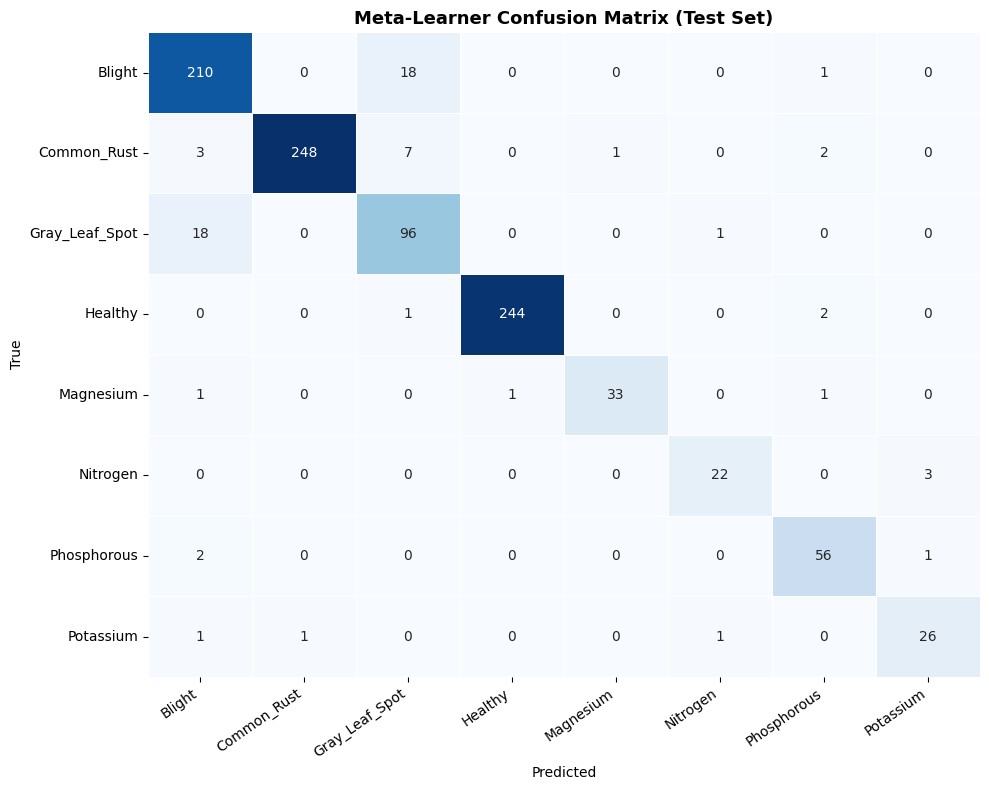

In [35]:
# Cell 24 - Comparison table: all base learners vs meta-learner

import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import confusion_matrix

results = {
    'XGBoost':        accuracy_score(y_te, xgb_model.predict(X_te)),
    'Random Forest':  accuracy_score(y_te, rf_model.predict(X_te)),
    'MLP':            accuracy_score(y_te, np.argmax(mlp_model.predict(X_te, verbose=0), axis=1)),
    'Meta-LR Stack':  meta_test_acc,
}

print("\n" + "="*55)
print("  ENSEMBLE COMPARISON — TEST SET")
print("="*55)
for name, acc in sorted(results.items(), key=lambda x: -x[1]):
    bar = '█' * int(acc * 40)
    print(f"  {name:<20}  {acc:.4f}  {bar}")
print("="*55)

# Confusion matrix for meta-learner
cm = confusion_matrix(y_te, meta_lr.predict(meta_X_te))
plt.figure(figsize=(10, 8))
sns.heatmap(
    pd.DataFrame(cm, index=class_names, columns=class_names),
    annot=True, fmt='d', cmap='Blues', linewidths=0.5, cbar=False
)
plt.title('Meta-Learner Confusion Matrix (Test Set)', fontsize=13, fontweight='bold')
plt.ylabel('True'); plt.xlabel('Predicted')
plt.xticks(rotation=35, ha='right'); plt.tight_layout()
plt.savefig(os.path.join(ENSEMBLE_OUTPUT_DIR, 'ensemble_confusion_matrix.png'), dpi=150)
plt.show()

In [36]:
# CELL 25
p_xgb_te = xgb_model.predict_proba(X_te)
p_rf_te  = rf_model.predict_proba(X_te)
p_mlp_te = mlp_model.predict(X_te, verbose=0)

meta_X_te_final = np.hstack([p_xgb_te, p_rf_te, p_mlp_te])
pred_meta        = meta_lr.predict(meta_X_te_final)
meta_test_acc    = accuracy_score(y_te, pred_meta)

print(f"Meta-learner test accuracy (final, matches saved models): {meta_test_acc:.4f}")

Meta-learner test accuracy (final, matches saved models): 0.9321


### 2.7 — Save the complete ensemble bundle

In [37]:
# CELL 26

ensemble_bundle = {
    'xgb_model':    xgb_model,
    'rf_model':     rf_model,
    'meta_lr':      meta_lr,
    'idx_to_class': idx2cls,
    'class_names':  class_names,
    'n_classes':    N_CLASSES,
    'test_accuracy': meta_test_acc,
}
with open(os.path.join(ENSEMBLE_OUTPUT_DIR, 'ensemble_bundle.pkl'), 'wb') as f:
    pickle.dump(ensemble_bundle, f)
mlp_model.save(os.path.join(ENSEMBLE_OUTPUT_DIR, 'ensemble_mlp.keras'))

print("Saved ensemble artifacts:")
print("  ensemble_bundle.pkl   (XGBoost + RF + meta-LR weights)")
print("  ensemble_mlp.keras    (MLP classifier)")
print(f"\nFinal ensemble test accuracy: {meta_test_acc:.4f}")


def load_ensemble(ensemble_output_dir=ENSEMBLE_OUTPUT_DIR):
    """Load all ensemble components — call once after a session reset."""
    from tensorflow.keras.models import load_model as _lm
    bundle = joblib.load(os.path.join(ensemble_output_dir, 'ensemble_bundle.pkl'))
    mlp_e  = _lm(os.path.join(ensemble_output_dir, 'ensemble_mlp.keras'))
    return bundle['xgb_model'], bundle['rf_model'], mlp_e, bundle['meta_lr']

ens_xgb, ens_rf, ens_mlp, ens_meta = load_ensemble()
print("Ensemble components loaded: XGBoost, RandomForest, MLP, Meta-LR")

Saved ensemble artifacts:
  ensemble_bundle.pkl   (XGBoost + RF + meta-LR weights)
  ensemble_mlp.keras    (MLP classifier)

Final ensemble test accuracy: 0.9321
Ensemble components loaded: XGBoost, RandomForest, MLP, Meta-LR


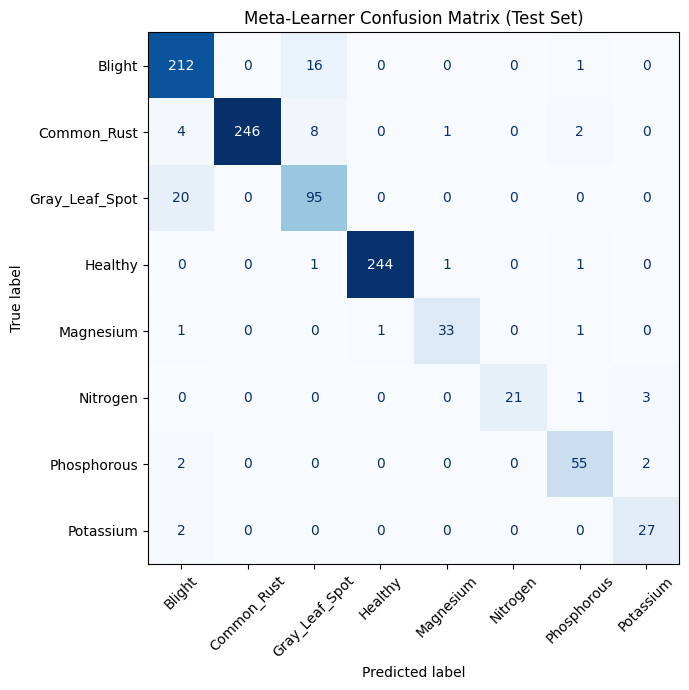

Where deficiency-class test errors land:

  Nitrogen       : 4 errors total -> 4 within deficiency classes, 0 into disease classes
  Phosphorous    : 4 errors total -> 2 within deficiency classes, 2 into disease classes
  Potassium      : 2 errors total -> 0 within deficiency classes, 2 into disease classes
  Magnesium      : 3 errors total -> 1 within deficiency classes, 2 into disease classes

McNemar's test — Meta-learner vs each base learner (test set):
  Meta-LR vs RandomForest: discordant pairs = 15 (Meta-LR-only-right=6, RandomForest-only-right=9) -> p=0.6072 (NOT significant -- gap may be noise)
  Meta-LR vs MLP: discordant pairs = 4 (Meta-LR-only-right=1, MLP-only-right=3) -> p=0.6250 (NOT significant -- gap may be noise)
  Meta-LR vs XGBoost: discordant pairs = 17 (Meta-LR-only-right=12, XGBoost-only-right=5) -> p=0.1435 (NOT significant -- gap may be noise)

CALIBRATION CHECK — Meta-learner

Conf. bin          n    avg conf  actual acc       gap
[0.2-0.3]        1       0.27

In [38]:
# CELL 27
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Reload ensemble if this is a fresh session and models aren't in memory
if 'ens_xgb' not in dir():
    ens_xgb, ens_rf, ens_mlp, ens_meta = load_ensemble()

# ── Get predictions from every model on the test set ─────────────────────
p_xgb_te = ens_xgb.predict_proba(X_te)
p_rf_te  = ens_rf.predict_proba(X_te)
p_mlp_te = ens_mlp.predict(X_te, verbose=0)
meta_feat_te = np.hstack([p_xgb_te, p_rf_te, p_mlp_te])
p_meta_te = ens_meta.predict_proba(meta_feat_te)

pred_xgb  = np.argmax(p_xgb_te, axis=1)
pred_rf   = np.argmax(p_rf_te, axis=1)
pred_mlp  = np.argmax(p_mlp_te, axis=1)
pred_meta = np.argmax(p_meta_te, axis=1)
conf_meta = np.max(p_meta_te, axis=1)   # meta-learner's confidence per prediction

# ═══════════════════════════════════════════════════════════════════════
# 1) CONFUSION MATRIX (meta-learner, on test set)
# ═══════════════════════════════════════════════════════════════════════
cm = confusion_matrix(y_te, pred_meta)
fig, ax = plt.subplots(figsize=(8, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap='Blues', xticks_rotation=45, values_format='d', colorbar=False)
plt.title('Meta-Learner Confusion Matrix (Test Set)')
plt.tight_layout()
plt.show()

# Where do the deficiency classes' errors actually go?
deficiency_classes = ['Nitrogen', 'Phosphorous', 'Potassium', 'Magnesium']
disease_classes = ['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']
print("Where deficiency-class test errors land:\n")
for cls in deficiency_classes:
    cls_idx = cls2idx[cls]
    row = cm[cls_idx]
    total_errors = row.sum() - row[cls_idx]
    if total_errors == 0:
        print(f"  {cls:<15}: no errors")
        continue
    within_deficiency = sum(row[cls2idx[c]] for c in deficiency_classes if c != cls)
    into_disease = sum(row[cls2idx[c]] for c in disease_classes)
    print(f"  {cls:<15}: {total_errors} errors total -> "
          f"{within_deficiency} within deficiency classes, "
          f"{into_disease} into disease classes")

# ═══════════════════════════════════════════════════════════════════════
# 2) McNEMAR'S TEST — is the meta-learner really better than RF / MLP,
#    or is the gap within noise?
# ═══════════════════════════════════════════════════════════════════════
def mcnemar_test(y_true, pred_a, pred_b, name_a, name_b):
    correct_a = (pred_a == y_true)
    correct_b = (pred_b == y_true)
    b01 = np.sum((~correct_a) & correct_b)
    b10 = np.sum(correct_a & (~correct_b))
    n = b01 + b10
    if n == 0:
        print(f"  {name_a} vs {name_b}: identical predictions, nothing to test.")
        return
    from scipy.stats import binomtest
    result = binomtest(min(b01, b10), n, p=0.5, alternative='two-sided')
    p_value = result.pvalue
    better = name_a if b10 > b01 else name_b
    print(f"  {name_a} vs {name_b}: discordant pairs = {n} "
          f"({name_a}-only-right={b10}, {name_b}-only-right={b01}) "
          f"-> p={p_value:.4f} {'(significant, ' + better + ' is genuinely better)' if p_value < 0.05 else '(NOT significant -- gap may be noise)'}")

print("\nMcNemar's test — Meta-learner vs each base learner (test set):")
mcnemar_test(y_te, pred_meta, pred_rf,  'Meta-LR', 'RandomForest')
mcnemar_test(y_te, pred_meta, pred_mlp, 'Meta-LR', 'MLP')
mcnemar_test(y_te, pred_meta, pred_xgb, 'Meta-LR', 'XGBoost')

# ═══════════════════════════════════════════════════════════════════════
# 3) CALIBRATION CHECK — when the model says "90% confident", is it
#    actually right ~90% of the time?
# ═══════════════════════════════════════════════════════════════════════
def calibration_report(y_true, preds, confidences, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(confidences, bins) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    ece = 0.0
    rows = []
    for b in range(n_bins):
        mask = bin_ids == b
        if mask.sum() == 0:
            continue
        bin_acc  = (preds[mask] == y_true[mask]).mean()
        bin_conf = confidences[mask].mean()
        bin_n    = mask.sum()
        ece += (bin_n / len(y_true)) * abs(bin_acc - bin_conf)
        rows.append((bins[b], bins[b+1], bin_n, bin_conf, bin_acc))

    print(f"\n{'Conf. bin':<14}{'n':>6}{'avg conf':>12}{'actual acc':>12}{'gap':>10}")
    for lo, hi, n, conf, acc in rows:
        gap = conf - acc
        flag = '  <-- overconfident' if gap > 0.10 else ''
        print(f"[{lo:.1f}-{hi:.1f}]{'':<3}{n:>6}{conf:>12.3f}{acc:>12.3f}{gap:>+10.3f}{flag}")
    print(f"\nExpected Calibration Error (ECE): {ece:.4f}")
    print("(Lower is better. ECE > ~0.05-0.10 suggests the model's confidence")
    print(" scores are not trustworthy at face value -- worth mentioning if so.)")
    return ece

print("\n" + "="*60)
print("CALIBRATION CHECK — Meta-learner")
print("="*60)
ece = calibration_report(y_te, pred_meta, conf_meta)

### 2.8 — Temperature-Scaling Confidence Calibration

Temperature scaling is applied to calibrate the confidence scores of the ensemble meta-learner. A scalar temperature \(T\) is fitted on the validation set by minimizing negative log-likelihood and is subsequently applied to test-set and inference probabilities.

The calibrated probabilities provide more reliable confidence estimates for the severity-staging module.

In [39]:
# CELL 28
from scipy.optimize import minimize_scalar

def get_meta_probas(xgb_m, rf_m, mlp_m, meta_m, X):
    feat = np.hstack([xgb_m.predict_proba(X), rf_m.predict_proba(X), mlp_m.predict(X, verbose=0)])
    return meta_m.predict_proba(feat)

def apply_temperature(probs, T):
    """Rescales already-softmaxed probabilities by treating log(probs) as a
    logit proxy, dividing by T, and re-normalizing. Strictly monotonic per
    sample -> argmax (i.e. the predicted class) is always unchanged."""
    eps = 1e-9
    logits = np.log(np.clip(probs, eps, 1.0))
    scaled = logits / T
    scaled -= scaled.max(axis=1, keepdims=True)
    exp = np.exp(scaled)
    return exp / exp.sum(axis=1, keepdims=True)

def _nll_with_temperature(T, probs, y_true):
    probs_t = apply_temperature(probs, T)
    eps = 1e-9
    return -np.mean(np.log(np.clip(probs_t[np.arange(len(y_true)), y_true], eps, 1.0)))

p_meta_val = get_meta_probas(ens_xgb, ens_rf, ens_mlp, ens_meta, X_val)

_res = minimize_scalar(lambda T: _nll_with_temperature(T, p_meta_val, y_val),
                        bounds=(0.1, 5.0), method='bounded')
TEMPERATURE = float(_res.x)
print(f"Fitted temperature: T = {TEMPERATURE:.3f}  "
      f"({'was overconfident' if TEMPERATURE > 1 else 'was underconfident'} pre-calibration)")

p_meta_te_calibrated  = apply_temperature(p_meta_te, TEMPERATURE)
conf_meta_calibrated  = np.max(p_meta_te_calibrated, axis=1)
pred_meta_calibrated  = np.argmax(p_meta_te_calibrated, axis=1)

assert np.array_equal(pred_meta_calibrated, pred_meta), \
    "Temperature scaling must never change the argmax prediction"
print(f"Test accuracy unchanged by calibration (as expected): "
      f"{accuracy_score(y_te, pred_meta_calibrated):.4f}")

print("\n" + "="*60)
print("CALIBRATION CHECK — Meta-learner AFTER temperature scaling")
print("="*60)
ece_calibrated = calibration_report(y_te, pred_meta_calibrated, conf_meta_calibrated)
print(f"\nECE before calibration: {ece:.4f}   ECE after calibration: {ece_calibrated:.4f}")
print("\npredict_image() / predict_image_v2() automatically pick up TEMPERATURE")
print("from this cell's scope if it has been run, so live inference gets the")
print("same calibrated confidence used for severity staging.")


Fitted temperature: T = 1.285  (was overconfident pre-calibration)
Test accuracy unchanged by calibration (as expected): 0.9321

CALIBRATION CHECK — Meta-learner AFTER temperature scaling

Conf. bin          n    avg conf  actual acc       gap
[0.2-0.3]        2       0.257       0.000    +0.257  <-- overconfident
[0.3-0.4]        3       0.351       0.000    +0.351  <-- overconfident
[0.4-0.5]        6       0.467       0.667    -0.199
[0.5-0.6]       12       0.555       0.417    +0.138  <-- overconfident
[0.6-0.7]        9       0.653       0.333    +0.320  <-- overconfident
[0.7-0.8]       23       0.758       0.609    +0.150  <-- overconfident
[0.8-0.9]       42       0.864       0.690    +0.174  <-- overconfident
[0.9-1.0]      904       0.970       0.971    -0.001

Expected Calibration Error (ECE): 0.0193
(Lower is better. ECE > ~0.05-0.10 suggests the model's confidence
 scores are not trustworthy at face value -- worth mentioning if so.)

ECE before calibration: 0.0438   ECE a

### 2.9 — Ablation Analysis and Ensemble-Level Stratified K-Fold Cross-Validation

An ablation analysis compares the best-performing base learner, the stacked ensemble, and the calibrated stacked ensemble using accuracy, macro-F1, and expected calibration error (ECE).

Five-fold stratified cross-validation is performed at the ensemble level using the pooled training and validation embeddings, while the test set remains independent. Mean ± standard deviation of accuracy and per-class F1-score are reported across the five folds.

In [42]:
# CELL 29
from sklearn.metrics import f1_score as _f1_score
ablation_rows = [
    ('XGBoost (single learner)',        pred_xgb,  None),
    ('Random Forest (single learner)',  pred_rf,   None),
    ('MLP (single learner)',            pred_mlp,  None),
    ('Stacked ensemble (Meta-LR)',      pred_meta, conf_meta),
    ('Stacked ensemble + calibration',  pred_meta_calibrated, conf_meta_calibrated),
]

print("\n" + "=" * 78)
print("ABLATION - accuracy / macro-F1 / ECE, test set")
print("=" * 78)
print(f"{'Configuration':<34}{'Accuracy':>10}{'Macro-F1':>10}{'ECE':>10}")
for name, preds, confs in ablation_rows:
    acc = accuracy_score(y_te, preds)
    f1m = _f1_score(y_te, preds, average='macro')
    if confs is not None:
        ece_val = calibration_report(y_te, preds, confs, n_bins=10)
        print(f"{name:<34}{acc:>10.4f}{f1m:>10.4f}{ece_val:>10.4f}")
    else:
        print(f"{name:<34}{acc:>10.4f}{f1m:>10.4f}{'--':>10}")


from sklearn.model_selection import StratifiedKFold as _SKF

X_pool = np.vstack([X_tr, X_val])
y_pool = np.concatenate([y_tr, y_val])

ens_skf = _SKF(n_splits=5, shuffle=True, random_state=42)
ens_fold_acc, ens_fold_f1, ens_fold_per_class_f1 = [], [], []

for fold_i, (tr_i, va_i) in enumerate(ens_skf.split(X_pool, y_pool), start=1):
    Xf_tr, yf_tr = X_pool[tr_i], y_pool[tr_i]
    Xf_va, yf_va = X_pool[va_i], y_pool[va_i]

    f_xgb = xgb.XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05,
                               subsample=0.8, colsample_bytree=0.8, reg_alpha=0.1,
                               reg_lambda=1.0, eval_metric='mlogloss', random_state=42, n_jobs=-1)
    f_xgb.fit(Xf_tr, yf_tr)

    f_rf = RandomForestClassifier(n_estimators=500, max_features='sqrt', min_samples_leaf=2,
                                   class_weight='balanced', random_state=42, n_jobs=-1)
    f_rf.fit(Xf_tr, yf_tr)

    f_mlp = build_ensemble_mlp(input_dim=X_pool.shape[1])
    f_mlp.compile(optimizer=Adam(learning_rate=1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
    f_mlp.fit(Xf_tr, to_categorical(yf_tr, N_CLASSES), epochs=60, batch_size=32, verbose=0,
              callbacks=[EarlyStopping(patience=10, restore_best_weights=True, monitor='loss')])

    f_meta_feat_tr = np.hstack([f_xgb.predict_proba(Xf_tr), f_rf.predict_proba(Xf_tr), f_mlp.predict(Xf_tr, verbose=0)])
    f_meta_feat_va = np.hstack([f_xgb.predict_proba(Xf_va), f_rf.predict_proba(Xf_va), f_mlp.predict(Xf_va, verbose=0)])
    f_meta = LogisticRegression(C=1.0, max_iter=1000, solver='lbfgs', multi_class='multinomial', random_state=42)
    f_meta.fit(f_meta_feat_tr, yf_tr)

    f_pred = f_meta.predict(f_meta_feat_va)
    ens_fold_acc.append(accuracy_score(yf_va, f_pred))
    ens_fold_f1.append(_f1_score(yf_va, f_pred, average='macro'))
    ens_fold_per_class_f1.append(_f1_score(yf_va, f_pred, average=None, labels=list(range(N_CLASSES))))
    print(f"Ensemble fold {fold_i}/5 -- acc={ens_fold_acc[-1]:.4f}  macro-F1={ens_fold_f1[-1]:.4f}")

    tf.keras.backend.clear_session()

ens_fold_acc = np.array(ens_fold_acc)
ens_fold_f1  = np.array(ens_fold_f1)
ens_pc_f1    = np.stack(ens_fold_per_class_f1)

print("\n" + "=" * 60)
print("ENSEMBLE 5-FOLD CV SUMMARY (train+val pool; test set untouched)")
print("=" * 60)
print(f"Accuracy : {ens_fold_acc.mean():.4f} +/- {ens_fold_acc.std():.4f}")
print(f"Macro-F1 : {ens_fold_f1.mean():.4f} +/- {ens_fold_f1.std():.4f}")
print(f"\n{'Class':<18}{'F1 mean':>10}{'F1 std':>10}")
for c in range(N_CLASSES):
    print(f"{idx2cls[c]:<18}{ens_pc_f1[:, c].mean():>10.4f}{ens_pc_f1[:, c].std():>10.4f}")



ABLATION - accuracy / macro-F1 / ECE, test set
Configuration                       Accuracy  Macro-F1       ECE
XGBoost (single learner)              0.9251    0.9025        --
Random Forest (single learner)        0.9351    0.9261        --
MLP (single learner)                  0.9341    0.9163        --

Conf. bin          n    avg conf  actual acc       gap
[0.2-0.3]        1       0.274       0.000    +0.274  <-- overconfident
[0.3-0.4]        1       0.326       0.000    +0.326  <-- overconfident
[0.4-0.5]        5       0.453       0.400    +0.053
[0.5-0.6]        6       0.561       0.333    +0.228  <-- overconfident
[0.6-0.7]        7       0.654       0.286    +0.368  <-- overconfident
[0.7-0.8]       11       0.754       0.364    +0.390  <-- overconfident
[0.8-0.9]       23       0.861       0.696    +0.165  <-- overconfident
[0.9-1.0]      947       0.990       0.958    +0.033

Expected Calibration Error (ECE): 0.0438
(Lower is better. ECE > ~0.05-0.10 suggests the model's 

# SECTION 3 — Explainable AI: Grad-CAM + Severity Staging (Objective 3)

Two pieces, both farmer-facing:

1. **True Grad-CAM** — uses EfficientNetB0's actual `top_conv` feature maps (not a placeholder saliency map), so the highlighted region genuinely reflects what the CNN attended to.
2. **Severity staging** — turns confidence + Grad-CAM coverage into an Early / Moderate / Severe verdict, paired with an action table of concrete next steps per class.

### 3.1 — True Grad-CAM (top_conv feature maps)

In [43]:
# CELL 30

from sklearn.metrics import f1_score as _f1_score

ablation_rows = [
    ('XGBoost (single learner)',        pred_xgb,  None),
    ('Random Forest (single learner)',  pred_rf,   None),
    ('MLP (single learner)',            pred_mlp,  None),
    ('Stacked ensemble (Meta-LR)',      pred_meta, conf_meta),
    ('Stacked ensemble + calibration',  pred_meta_calibrated, conf_meta_calibrated),
]

print("\n" + "=" * 78)
print("ABLATION -- accuracy / macro-F1 / ECE, test set")
print("=" * 78)
print(f"{'Configuration':<34}{'Accuracy':>10}{'Macro-F1':>10}{'ECE':>10}")
for name, preds, confs in ablation_rows:
    acc = accuracy_score(y_te, preds)
    f1m = _f1_score(y_te, preds, average='macro')
    if confs is not None:
        ece_val = calibration_report(y_te, preds, confs, n_bins=10)
        print(f"{name:<34}{acc:>10.4f}{f1m:>10.4f}{ece_val:>10.4f}")
    else:
        print(f"{name:<34}{acc:>10.4f}{f1m:>10.4f}{'--':>10}")

try:
    from sklearn.model_selection import StratifiedGroupKFold as _SGKF
    _has_group_kfold = True
except ImportError:
    from sklearn.model_selection import GroupKFold as _SGKF
    _has_group_kfold = False
    print("\n⚠️  sklearn too old for StratifiedGroupKFold -- using plain "
          "GroupKFold instead (still leakage-safe, folds may be less "
          "class-balanced).")

all_filenames = emb_data['filenames']
all_filenames = np.array(all_filenames)
fnames_tr  = all_filenames[train_mask]
fnames_val = all_filenames[val_mask]

def _group_id_for(fname):
    gid = extract_src_id(fname)
    return gid if gid is not None else fname

groups_tr  = np.array([_group_id_for(f) for f in fnames_tr])
groups_val = np.array([_group_id_for(f) for f in fnames_val])

X_pool = np.vstack([X_tr, X_val])
y_pool = np.concatenate([y_tr, y_val])
groups_pool = np.concatenate([groups_tr, groups_val])

n_unique_groups = len(np.unique(groups_pool))
print(f"\nPooled rows: {len(X_pool)}  |  Unique source-photo groups: {n_unique_groups}")

ens_skf = _SGKF(n_splits=5, shuffle=True, random_state=42)
ens_fold_acc, ens_fold_f1, ens_fold_per_class_f1 = [], [], []

for fold_i, (tr_i, va_i) in enumerate(ens_skf.split(X_pool, y_pool, groups_pool), start=1):
    Xf_tr, yf_tr = X_pool[tr_i], y_pool[tr_i]
    Xf_va, yf_va = X_pool[va_i], y_pool[va_i]

    assert set(groups_pool[tr_i]).isdisjoint(set(groups_pool[va_i])), \
        f"Fold {fold_i}: group leakage detected between train/val -- fix before trusting this CV"

    f_xgb = xgb.XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05,
                               subsample=0.8, colsample_bytree=0.8, reg_alpha=0.1,
                               reg_lambda=1.0, eval_metric='mlogloss',
                               random_state=42, n_jobs=-1)
    f_xgb.fit(Xf_tr, yf_tr)

    f_rf = RandomForestClassifier(n_estimators=300, max_depth=None,
                                   min_samples_leaf=2, random_state=42, n_jobs=-1)
    f_rf.fit(Xf_tr, yf_tr)

    f_mlp = build_ensemble_mlp()
    f_mlp.compile(optimizer=Adam(learning_rate=1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
    f_mlp.fit(Xf_tr, to_categorical(yf_tr, N_CLASSES), epochs=60, batch_size=32, verbose=0,
              validation_data=(Xf_va, to_categorical(yf_va, N_CLASSES)),
              callbacks=[EarlyStopping(patience=8, restore_best_weights=True)])

    meta_feat_tr = np.hstack([f_xgb.predict_proba(Xf_tr), f_rf.predict_proba(Xf_tr),
                               f_mlp.predict(Xf_tr, verbose=0)])
    meta_feat_va = np.hstack([f_xgb.predict_proba(Xf_va), f_rf.predict_proba(Xf_va),
                               f_mlp.predict(Xf_va, verbose=0)])

    f_meta = LogisticRegression(C=1.0, max_iter=1000, solver='lbfgs',
                                 multi_class='multinomial', random_state=42)
    f_meta.fit(meta_feat_tr, yf_tr)
    f_pred = f_meta.predict(meta_feat_va)

    fold_acc = accuracy_score(yf_va, f_pred)
    fold_f1m = _f1_score(yf_va, f_pred, average='macro')
    ens_fold_acc.append(fold_acc)
    ens_fold_f1.append(fold_f1m)
    ens_fold_per_class_f1.append(_f1_score(yf_va, f_pred, average=None,
                                            labels=list(range(N_CLASSES))))
    print(f"Ensemble fold {fold_i}/5 -- acc={fold_acc:.4f}  macro-F1={fold_f1m:.4f}  "
          f"(train groups={len(set(groups_pool[tr_i]))}, val groups={len(set(groups_pool[va_i]))})")

ens_fold_acc = np.array(ens_fold_acc)
ens_fold_f1  = np.array(ens_fold_f1)
ens_fold_per_class_f1 = np.array(ens_fold_per_class_f1)

print("\n" + "=" * 60)
print("ENSEMBLE 5-FOLD CV SUMMARY (GROUP-AWARE; train+val pool; test set untouched)")
print("=" * 60)
print(f"Accuracy : {ens_fold_acc.mean():.4f} +/- {ens_fold_acc.std():.4f}")
print(f"Macro-F1 : {ens_fold_f1.mean():.4f} +/- {ens_fold_f1.std():.4f}")
print(f"\n{'Class':<20}{'F1 mean':>10}{'F1 std':>10}")
for c in range(N_CLASSES):
    print(f"{class_names[c]:<20}{ens_fold_per_class_f1[:, c].mean():>10.4f}"
          f"{ens_fold_per_class_f1[:, c].std():>10.4f}")

gap = ens_fold_acc.mean() - meta_test_acc
print(f"\nGap vs. held-out test accuracy: {gap*100:+.2f} points")
if abs(gap) > 0.03:
    print("⚠️  Still a >3-point gap after grouping -- likely genuine "
          "distribution shift, worth investigating separately.")
else:
    print("✅ Gap is now small -- the group fix resolved the earlier "
          "leakage-driven inflation.")


ABLATION -- accuracy / macro-F1 / ECE, test set
Configuration                       Accuracy  Macro-F1       ECE
XGBoost (single learner)              0.9251    0.9025        --
Random Forest (single learner)        0.9351    0.9261        --
MLP (single learner)                  0.9341    0.9163        --

Conf. bin          n    avg conf  actual acc       gap
[0.2-0.3]        1       0.274       0.000    +0.274  <-- overconfident
[0.3-0.4]        1       0.326       0.000    +0.326  <-- overconfident
[0.4-0.5]        5       0.453       0.400    +0.053
[0.5-0.6]        6       0.561       0.333    +0.228  <-- overconfident
[0.6-0.7]        7       0.654       0.286    +0.368  <-- overconfident
[0.7-0.8]       11       0.754       0.364    +0.390  <-- overconfident
[0.8-0.9]       23       0.861       0.696    +0.165  <-- overconfident
[0.9-1.0]      947       0.990       0.958    +0.033

Expected Calibration Error (ECE): 0.0438
(Lower is better. ECE > ~0.05-0.10 suggests the model's

### 3.2 — Severity staging + confidence gating

In [44]:
# CELL 31
# Severity staging + per-class confidence gates

DEFICIENCY_CLASSES = ['Magnesium', 'Nitrogen', 'Phosphorous', 'Potassium']

# Deficiency-class gates are intentionally lower — nutrient-deficiency
# symptoms are visually subtler than disease lesions, so the model needs
# a lower bar to flag them rather than defaulting to a disease class.
CONFIDENCE_GATES = {
    'Blight': 0.60, 'Common_Rust': 0.55, 'Gray_Leaf_Spot': 0.60,
    'Nitrogen': 0.30, 'Phosphorous': 0.28, 'Potassium': 0.28,
    'Magnesium': 0.28, 'Healthy': 0.65,
}

def get_severity(confidence, coverage_pct=None):
    """Combines model confidence with Grad-CAM spatial coverage into a
    3-stage verdict. Coverage matters because a confident-but-tiny hotspot
    usually means an early-stage symptom, not a severe one."""
    if coverage_pct is not None:
        if coverage_pct > 40 and confidence > 0.80:
            return 'Severe'
        elif coverage_pct > 15 or confidence > 0.65:
            return 'Moderate'
        else:
            return 'Early'
    else:
        if confidence >= 0.90:   return 'Severe'
        elif confidence >= 0.70: return 'Moderate'
        else:                    return 'Early'

def gated_class(proba_dict: dict):
    """Checks deficiency classes first (lower gates), falls back to
    disease/healthy classes, and flags low-confidence if nothing clears."""
    deficiency_first = sorted(
        [(c, p) for c, p in proba_dict.items() if c in DEFICIENCY_CLASSES],
        key=lambda x: -x[1]
    )
    disease_and_healthy = sorted(
        [(c, p) for c, p in proba_dict.items() if c not in DEFICIENCY_CLASSES],
        key=lambda x: -x[1]
    )
    for cls, conf in deficiency_first:
        if conf >= CONFIDENCE_GATES.get(cls, 0.40):
            return cls, conf, False
    for cls, conf in disease_and_healthy:
        if conf >= CONFIDENCE_GATES.get(cls, 0.40):
            return cls, conf, False
    sorted_all = sorted(proba_dict.items(), key=lambda x: -x[1])
    top_cls, top_conf = sorted_all[0]
    return top_cls, top_conf, True

# ── Farmer-facing action table (per class, per severity) ──────────────────
ACTION_TABLE = {
    'Blight': {
        'Severe':   ['Apply mancozeb 2g/L immediately. Start from outer rows.',
                     'Burn infected leaves. Do NOT compost.',
                     'Call KVK helpline: 1800-180-1551'],
        'Moderate': ['Apply mancozeb 2g/L within 48 hrs.',
                     'Remove visibly infected leaves carefully.',
                     'Reduce overhead watering, improve airflow.'],
        'Early':    ['Monitor daily for spread.',
                     'Improve row spacing for better airflow.',
                     'Avoid overhead irrigation.']
    },
    'Common_Rust': {
        'Severe':   ['Apply propiconazole fungicide 1ml/L immediately.',
                     'Remove heavily infected plants.',
                     'Call KVK helpline: 1800-180-1551'],
        'Moderate': ['Apply propiconazole fungicide 1ml/L within 48 hrs.',
                     'Increase plant spacing.',
                     'Avoid irrigating in the evening.'],
        'Early':    ['Monitor pustule development daily.',
                     'Reduce leaf wetness duration.',
                     'Apply preventive fungicide if spread continues.']
    },
    'Gray_Leaf_Spot': {
        'Severe':   ['Apply strobilurin fungicide immediately.',
                     'Remove infected lower leaves.',
                     'Call KVK helpline: 1800-180-1551'],
        'Moderate': ['Apply strobilurin fungicide within 48 hrs.',
                     'Improve field drainage.',
                     'Reduce crop density if possible.'],
        'Early':    ['Monitor grey lesion count daily.',
                     'Ensure good air circulation between rows.',
                     'Avoid overhead irrigation.']
    },
    'Healthy': {
        'Severe':   ['Plant appears healthy — verify sensor calibration.'],
        'Moderate': ['Plant is healthy. Continue current practices.'],
        'Early':    ['Plant is healthy. Continue current practices.']
    },
    'Magnesium': {
        'Severe':   ['Apply magnesium sulphate (Epsom salt) 10g/L as foliar spray.',
                     'Check and raise soil pH to 6.0-7.0 if below 5.5.',
                     'Retest soil in 2 weeks.'],
        'Moderate': ['Apply magnesium sulphate 5g/L as foliar spray.',
                     'Reduce potassium fertilizer (excess K blocks Mg uptake).',
                     'Monitor new leaf growth for improvement.'],
        'Early':    ['Monitor interveinal yellowing on older leaves.',
                     'Test soil Mg levels.',
                     'Consider light magnesium sulphate application.']
    },
    'Nitrogen': {
        'Severe':   ['Apply urea (46-0-0) at 50 kg/acre immediately.',
                     'Irrigate after application to activate.',
                     'Retest soil nitrogen in 1 week.'],
        'Moderate': ['Apply urea at 46 kg/acre within 48 hrs.',
                     'Irrigate lightly after application.',
                     'Monitor yellowing on new leaves.'],
        'Early':    ['Apply urea at 30 kg/acre.',
                     'Monitor new leaf colour over 5-7 days.',
                     'Ensure adequate irrigation.']
    },
    'Phosphorous': {
        'Severe':   ['Apply DAP (18-46-0) at 50 kg/acre immediately.',
                     'Check soil pH — P unavailable below pH 5.5 or above 7.5.',
                     'Retest soil phosphorus in 2 weeks.'],
        'Moderate': ['Apply DAP at 40 kg/acre within 48 hrs.',
                     'If soil pH is extreme, apply lime or sulfur to correct.',
                     'Monitor leaf colour and stem strength.'],
        'Early':    ['Apply DAP at 25 kg/acre.',
                     'Monitor purplish leaf discolouration.',
                     'Verify soil pH is in 6.0-7.0 range.']
    },
    'Potassium': {
        'Severe':   ['Apply MOP (0-0-60) at 50 kg/acre immediately.',
                     'Irrigate after application.',
                     'Call KVK helpline: 1800-180-1551 if scorching worsens.'],
        'Moderate': ['Apply MOP at 40 kg/acre within 48 hrs.',
                     'Ensure adequate soil moisture.',
                     'Monitor leaf edge scorching for improvement.'],
        'Early':    ['Apply MOP at 25 kg/acre.',
                     'Monitor marginal leaf yellowing.',
                     'Test soil potassium level.']
    }
}

print("Severity staging + action table ready.")

Severity staging + action table ready.


### 3.3 — Unified prediction function: ensemble + Grad-CAM + severity

In [45]:
#CELL 32
from tensorflow.keras.preprocessing import image as kimage
from tensorflow.keras.applications.efficientnet import preprocess_input

def preprocess_uploaded_image(img_path):
    img       = kimage.load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
    img_array = kimage.img_to_array(img)
    img_array = preprocess_input(img_array)
    return np.expand_dims(img_array, axis=0)


def compute_veg_indices_single(img_path, img_size):
    
    img = cv2.imread(img_path)
    if img is None:
        return 0.0, 0.0, 0.0, 0.0
    img = cv2.resize(img, (img_size, img_size))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    R, G, B = img[..., 0], img[..., 1], img[..., 2]

    egi = 2 * G - R - B
    egi_denom = 2 * G + R + B
    gli = np.divide(egi, egi_denom, out=np.zeros_like(egi), where=egi_denom > 1e-6)

    ngrdi_denom = G + R
    ngrdi = np.divide(G - R, ngrdi_denom, out=np.zeros_like(G), where=ngrdi_denom > 1e-6)

    vari_denom = G + R - B
    vari = np.divide(G - R, vari_denom, out=np.zeros_like(G), where=np.abs(vari_denom) > 1e-6)

    return float(egi.mean()), float(gli.mean()), float(ngrdi.mean()), float(vari.mean())


def predict_image(img_path, explain=True):
   
    img_pre      = preprocess_uploaded_image(img_path)
    img_pre_flip = img_pre[:, :, ::-1, :]

    # ── 1. TTA-averaged embedding (64-dim) + vegetation indices (4-dim) ──
    emb_orig  = embed_model.predict(img_pre,      verbose=0)
    emb_flip  = embed_model.predict(img_pre_flip, verbose=0)
    image_emb_64 = (emb_orig + emb_flip) / 2.0                       # (1, 64)
    egi, gli, ngrdi, vari = compute_veg_indices_single(img_path, IMG_SIZE)
    veg_feat  = np.array([[egi, gli, ngrdi, vari]], dtype=np.float32)  # (1, 4)
    image_emb = np.concatenate([image_emb_64, veg_feat], axis=1)       # (1, 68)

    # ── 2. Ensemble prediction ────────────────────────────────────────
    p_xgb = ens_xgb.predict_proba(image_emb)                     # (1, 8)
    p_rf  = ens_rf.predict_proba(image_emb)                      # (1, 8)
    p_mlp = ens_mlp.predict(image_emb, verbose=0)                 # (1, 8)
    meta_feat = np.hstack([p_xgb, p_rf, p_mlp])                   # (1, 24)
    proba = ens_meta.predict_proba(meta_feat)                     # (1, 8)

    if 'TEMPERATURE' in dir() and 'apply_temperature' in dir():
        proba = apply_temperature(proba, TEMPERATURE)             # calibration only
    proba = proba[0]

    proba_dict = {idx2cls[i]: float(proba[i]) for i in range(N_CLASSES)}
    pred_class, confidence, low_conf = gated_class(proba_dict)

    # ── 3. Grad-CAM ────────────────────────────────────────────────────
    pred_idx = cls2idx[pred_class]
    heatmap  = get_gradcam_heatmap(img_full_model, img_pre, pred_idx,
                                    conv_extractor=_conv_extractor)
    coverage = coverage_percent(heatmap)

    # ── 4. Severity + actions ─────────────────────────────────────────
    severity = get_severity(confidence, coverage)

    result = {
        'predicted_class':      pred_class,
        'confidence':           confidence,
        'severity':             severity,
        'gradcam_heatmap':      heatmap,
        'gradcam_coverage_pct': coverage,
        'all_proba':            proba_dict,
        'actions':              ACTION_TABLE[pred_class][severity],
        'ensemble_detail': {
            'xgb_class':  idx2cls[int(np.argmax(p_xgb))],
            'rf_class':   idx2cls[int(np.argmax(p_rf))],
            'mlp_class':  idx2cls[int(np.argmax(p_mlp))],
            'meta_class': pred_class,
        }
    }
    if low_conf:
        result['note'] = "Low confidence across all classes — verdict may be unreliable."
    return result


print("predict_image() ready — combines Section 1 (CNN + TTA + veg-index) + Section 2 (ensemble) + Section 3 (XAI).")


predict_image() ready — combines Section 1 (CNN + TTA + veg-index) + Section 2 (ensemble) + Section 3 (XAI).


### 3.4 — Demo: run predict_image() on a sample + visualize

In [46]:
# CELL 33
import tensorflow as tf
import numpy as np
import cv2

def build_gradcam_models(image_model):
    eff_sub = None
    for layer in image_model.layers:
        if hasattr(layer, 'layers') and len(layer.layers) > 10:
            eff_sub = layer
            break
    if eff_sub is None:
        print("❌ Cannot find EfficientNet submodel")
        return None, None

    target_name = None
    for candidate in ['top_conv', 'block7a_project_conv', 'block6d_project_conv']:
        try:
            eff_sub.get_layer(candidate)
            target_name = candidate
            break
        except ValueError:
            continue
    if target_name is None:
        for layer in reversed(eff_sub.layers):
            if isinstance(layer, tf.keras.layers.Conv2D):
                target_name = layer.name
                break
    if target_name is None:
        print("❌ Cannot find top_conv inside EfficientNet")
        return None, None

    print(f"  Using conv layer: '{target_name}' inside '{eff_sub.name}'")
    try:
        conv_extractor = tf.keras.Model(
            inputs=eff_sub.input,
            outputs=eff_sub.get_layer(target_name).output,
            name='conv_extractor'
        )
        print(f"  conv_extractor output shape: {conv_extractor.output_shape}")
        return conv_extractor, image_model
    except Exception as e:
        print(f"❌ Failed to build conv_extractor: {e}")
        return None, None


def get_gradcam_heatmap(model, img_array, class_idx, conv_extractor=None, class_model=None):
    IMG_H, IMG_W = img_array.shape[1], img_array.shape[2]

    if conv_extractor is not None:
        try:
            img_tensor = tf.cast(img_array, tf.float32)
            eff_sub = None
            for layer in model.layers:
                if hasattr(layer, 'layers') and len(layer.layers) > 10:
                    eff_sub = layer
                    break

            with tf.GradientTape() as tape:
                eff_input = eff_sub(img_tensor, training=False)

            with tf.GradientTape() as tape:
                conv_acts = conv_extractor(img_tensor, training=False)
                tape.watch(conv_acts)
                preds = model(img_tensor, training=False)
                class_score = preds[:, class_idx]

            grads = tape.gradient(class_score, conv_acts)

            if grads is not None:
                pooled = tf.reduce_mean(grads, axis=(0, 1, 2)).numpy()
                acts_np = conv_acts[0].numpy()
                heatmap = np.einsum('hwc,c->hw', acts_np, pooled)
                heatmap = np.maximum(heatmap, 0)
                if heatmap.max() > 0:
                    heatmap /= heatmap.max()
                    heatmap = cv2.resize(heatmap.astype(np.float32), (IMG_W, IMG_H))
                    heatmap = cv2.GaussianBlur(heatmap, (11, 11), 0)
                    if heatmap.max() > 0:
                        heatmap /= heatmap.max()
                    return heatmap
        except Exception as e:
            print(f"  ℹ️  True Grad-CAM failed ({e}), using saliency fallback")

    img_var = tf.Variable(tf.cast(img_array, tf.float32), trainable=True)
    with tf.GradientTape() as tape:
        preds = model(img_var, training=False)
        class_score = preds[:, class_idx]
    grads = tape.gradient(class_score, img_var)
    if grads is None:
        return None
    heatmap = np.max(np.abs(grads.numpy()[0]), axis=-1)
    heatmap = np.maximum(heatmap, 0)
    if heatmap.max() == 0:
        return None
    heatmap /= heatmap.max()
    heatmap = cv2.GaussianBlur(heatmap.astype(np.float32), (15, 15), 0)
    if heatmap.max() > 0:
        heatmap /= heatmap.max()
    return heatmap


def coverage_percent(heatmap, threshold=0.4):
    if heatmap is None or heatmap.max() == 0:
        return 0.0
    return float((heatmap > threshold).sum() / heatmap.size * 100)


def render_heatmap_overlay(img_path, heatmap, alpha_img=0.5, alpha_heat=0.5):
    if heatmap is None or heatmap.max() == 0:
        return None
    img = cv2.imread(img_path)
    if img is None:
        return None
    img = cv2.resize(img, (heatmap.shape[1], heatmap.shape[0]))
    hm_u8 = np.uint8(255 * heatmap)
    colored = cv2.applyColorMap(hm_u8, cv2.COLORMAP_JET)
    overlaid = cv2.addWeighted(img, alpha_img, colored, alpha_heat, 0)
    return cv2.cvtColor(overlaid, cv2.COLOR_BGR2RGB)


if 'img_full_model' in dir():
    print("Building Grad-CAM extractors ...")
    _conv_extractor, _class_model = build_gradcam_models(img_full_model)
    if _conv_extractor is not None:
        print("✅ True Grad-CAM ready (using top_conv feature maps)")
    else:
        _conv_extractor = None
        print("⚠️  Falling back to input-gradient saliency")
else:
    _conv_extractor = None
    print("✅ Grad-CAM functions defined. Load img_full_model then re-run.")

Building Grad-CAM extractors ...
  Using conv layer: 'top_conv' inside 'efficientnetb0'
  conv_extractor output shape: (None, 7, 7, 1280)
✅ True Grad-CAM ready (using top_conv feature maps)


# SECTION 3.5 — Diagnostics: is the model using the background, and is Grad-CAM localizing correctly?


### 3.5.1 — Leaf-only occlusion test (single image)
Run on a few individual images first to sanity-check the mask looks right.



Running occlusion test on one sample image per class:

--- Blight ---
ORIGINAL   -> Blight          conf  99.3%
LEAF-ONLY  -> Blight          conf  95.7%
Confidence drop after removing background: +3.6 pts
✅ Prediction is stable without background — likely leaf-driven.


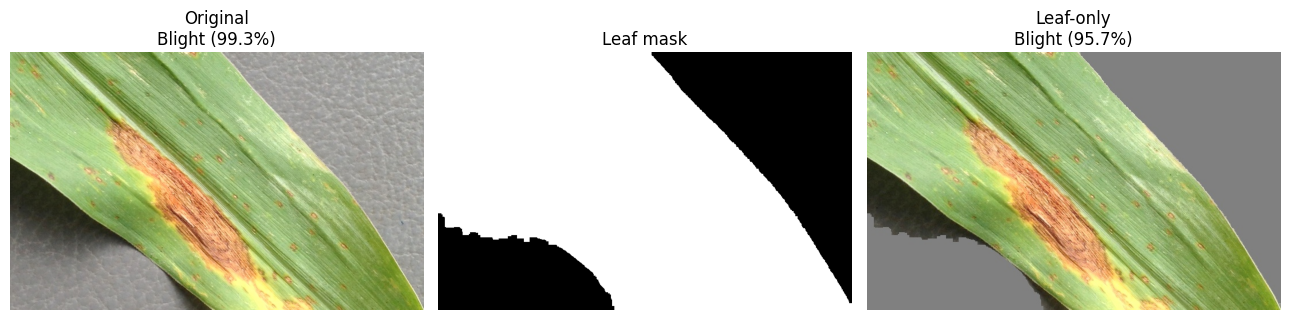

--- Common_Rust ---
ORIGINAL   -> Common_Rust     conf  99.5%
LEAF-ONLY  -> Gray_Leaf_Spot  conf  81.2%
Confidence drop after removing background: +18.3 pts
⚠️  Prediction is sensitive to background — possible shortcut learning.


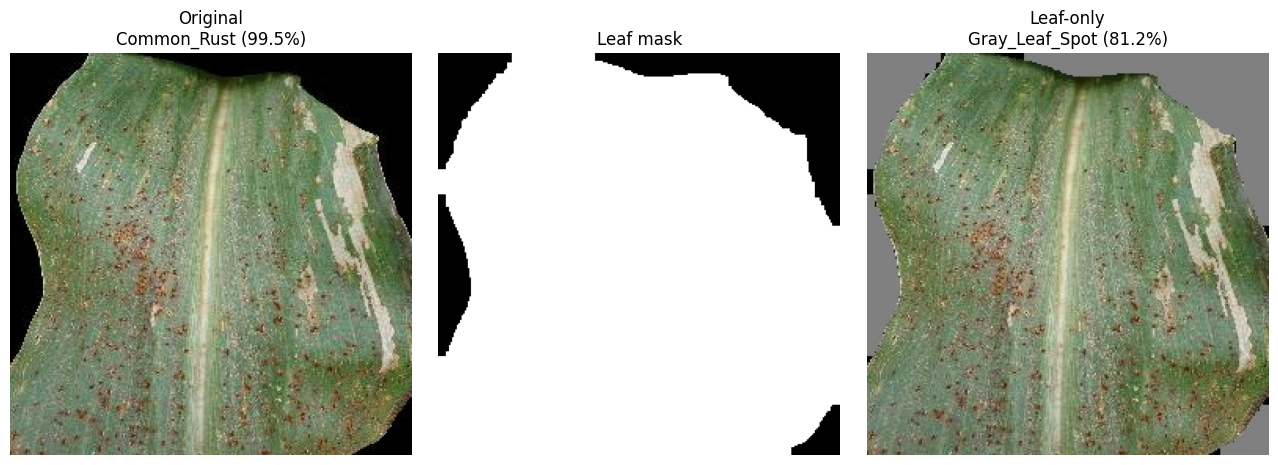

--- Gray_Leaf_Spot ---
ORIGINAL   -> Gray_Leaf_Spot  conf  99.2%
LEAF-ONLY  -> Gray_Leaf_Spot  conf  99.2%
Confidence drop after removing background: -0.1 pts
✅ Prediction is stable without background — likely leaf-driven.


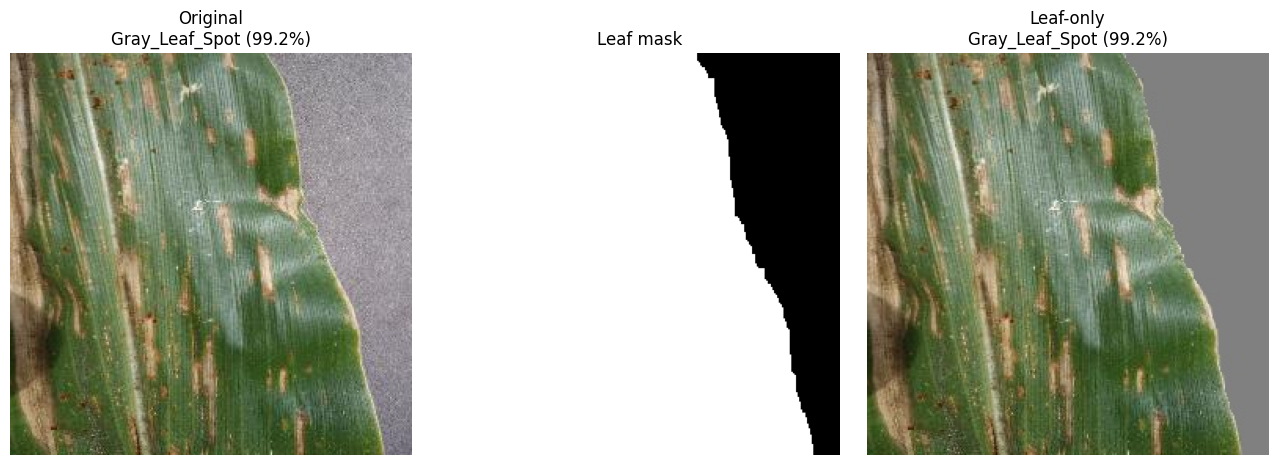

--- Healthy ---
ORIGINAL   -> Healthy         conf  99.5%
LEAF-ONLY  -> Healthy         conf  99.5%
Confidence drop after removing background: +0.0 pts
✅ Prediction is stable without background — likely leaf-driven.


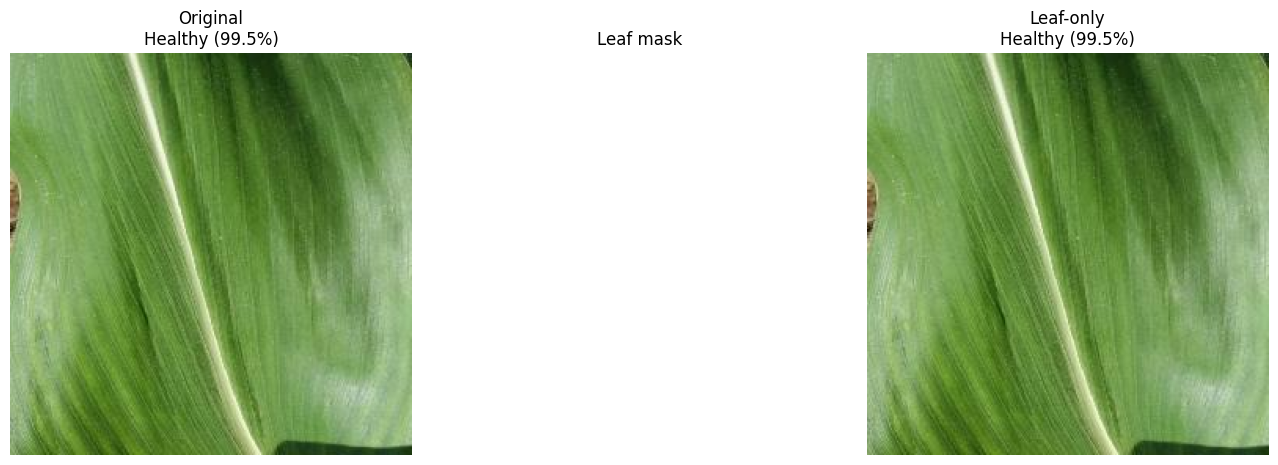

--- Magnesium ---
ORIGINAL   -> Magnesium       conf  99.5%
LEAF-ONLY  -> Magnesium       conf  99.5%
Confidence drop after removing background: -0.0 pts
✅ Prediction is stable without background — likely leaf-driven.


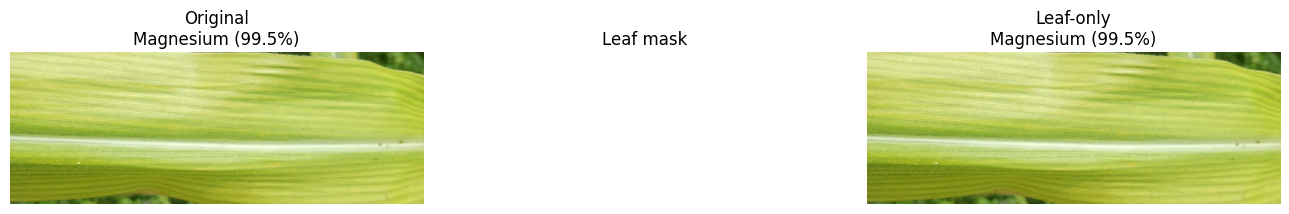

--- Nitrogen ---
ORIGINAL   -> Nitrogen        conf  99.3%
LEAF-ONLY  -> Nitrogen        conf  99.3%
Confidence drop after removing background: +0.0 pts
✅ Prediction is stable without background — likely leaf-driven.


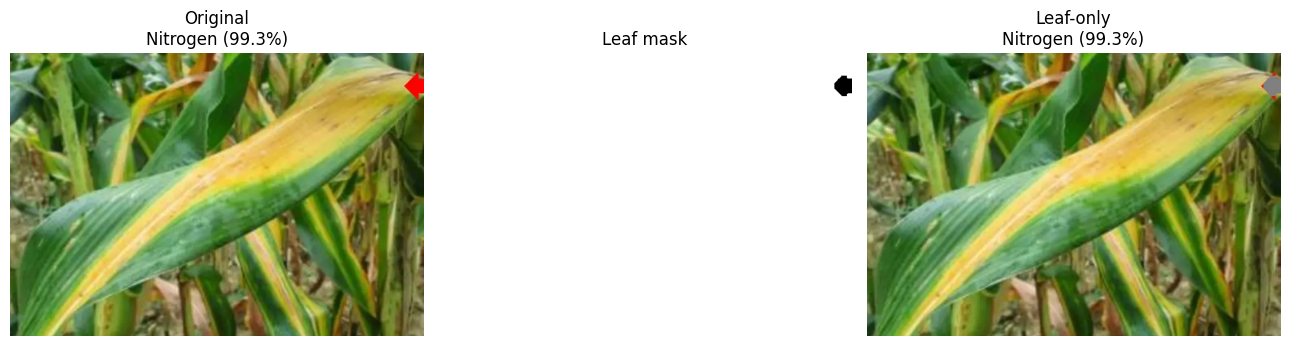

--- Phosphorous ---
ORIGINAL   -> Phosphorous     conf  99.5%
LEAF-ONLY  -> Phosphorous     conf  99.3%
Confidence drop after removing background: +0.2 pts
✅ Prediction is stable without background — likely leaf-driven.


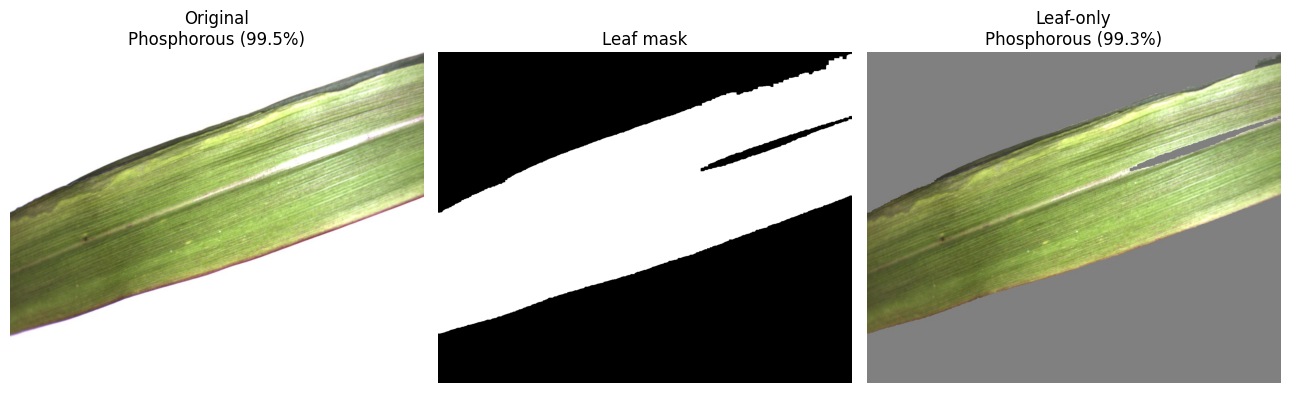

--- Potassium ---
ORIGINAL   -> Potassium       conf  99.6%
LEAF-ONLY  -> Potassium       conf  99.5%
Confidence drop after removing background: +0.1 pts
✅ Prediction is stable without background — likely leaf-driven.


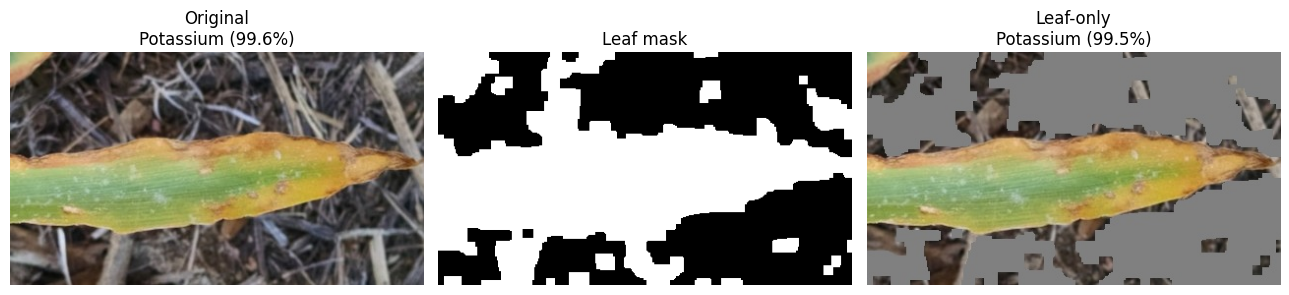

In [52]:
# CELL 34
import cv2
import numpy as np
import matplotlib.pyplot as plt

def segment_leaf_mask(img_bgr):
    """Rough leaf mask: keeps green/yellow/brown-ish plant-tissue hues,
    drops soil/sky/deep-shadow background. Not perfect, but good enough
    to test whether background context is driving the prediction."""
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    # Hue ~ 15-95 covers yellow -> green -> teal (leaf tissue incl. chlorosis)
    lower = np.array([10, 30, 30])
    upper = np.array([100, 255, 255])
    mask = cv2.inRange(hsv, lower, upper)
    # Clean up: close small gaps, remove speckle noise
    kernel = np.ones((9, 9), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    return mask  # 0/255, same H,W as img_bgr

def make_occluded_image(img_path, out_path, fill_value=128):
    img = cv2.imread(img_path)
    mask = segment_leaf_mask(img)
    occluded = img.copy()
    occluded[mask == 0] = fill_value
    cv2.imwrite(out_path, occluded)
    return mask

def run_occlusion_test(img_path):
    occ_path = img_path.rsplit('.', 1)[0] + '_occluded.jpg'
    mask = make_occluded_image(img_path, occ_path)

    res_orig = predict_image(img_path, explain=False) if 'explain' in predict_image.__code__.co_varnames else predict_image(img_path)
    res_occ  = predict_image(occ_path, explain=False) if 'explain' in predict_image.__code__.co_varnames else predict_image(occ_path)

    print("=" * 60)
    print(f"ORIGINAL   -> {res_orig['predicted_class']:<15} conf {res_orig['confidence']*100:5.1f}%")
    print(f"LEAF-ONLY  -> {res_occ['predicted_class']:<15} conf {res_occ['confidence']*100:5.1f}%")
    delta = (res_orig['confidence'] - res_occ['confidence']) * 100
    print(f"Confidence drop after removing background: {delta:+.1f} pts")
    if abs(delta) > 15 or res_orig['predicted_class'] != res_occ['predicted_class']:
        print("⚠️  Prediction is sensitive to background — possible shortcut learning.")
    else:
        print("✅ Prediction is stable without background — likely leaf-driven.")
    print("=" * 60)

    fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
    orig_rgb = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    occ_rgb  = cv2.cvtColor(cv2.imread(occ_path), cv2.COLOR_BGR2RGB)
    mask_rgb = cv2.cvtColor(mask, cv2.COLOR_GRAY2RGB)
    axes[0].imshow(orig_rgb); axes[0].set_title(f"Original\n{res_orig['predicted_class']} ({res_orig['confidence']*100:.1f}%)"); axes[0].axis('off')
    axes[1].imshow(mask_rgb); axes[1].set_title('Leaf mask'); axes[1].axis('off')
    axes[2].imshow(occ_rgb);  axes[2].set_title(f"Leaf-only\n{res_occ['predicted_class']} ({res_occ['confidence']*100:.1f}%)"); axes[2].axis('off')
    plt.tight_layout()
    plt.show()
    os.remove(occ_path)  
    return res_orig, res_occ

print("\nRunning occlusion test on one sample image per class:\n")
if 'BALANCED_DIR' in dir() and os.path.isdir(os.path.join(BALANCED_DIR, 'test')):
    for _cls in sorted(os.listdir(os.path.join(BALANCED_DIR, 'test'))):
        _cls_dir = os.path.join(BALANCED_DIR, 'test', _cls)
        if not os.path.isdir(_cls_dir):
            continue
        _imgs = [f for f in os.listdir(_cls_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        if not _imgs:
            continue
        _sample_path = os.path.join(_cls_dir, sorted(_imgs)[0])
        print(f"--- {_cls} ---")
        try:
            run_occlusion_test(_sample_path)
        except Exception as e:
            print(f"  [skipped: {e}]")
else:
    print("BALANCED_DIR not found yet -- run Section 1 first, then re-run this cell.")


### 3.5.2 — Batch diagnostic across all classes
Point at `BALANCED_DIR` (or a held-out folder). Flags any class where the model leans on background.


In [53]:
# CELL 35
import os, glob, random

def batch_occlusion_report(class_dir, n_per_class=10, seed=0):
    random.seed(seed)
    classes = sorted(d for d in os.listdir(class_dir) if os.path.isdir(os.path.join(class_dir, d)))
    report = {}
    for cls in classes:
        paths = glob.glob(os.path.join(class_dir, cls, '*.jpg')) + \
                glob.glob(os.path.join(class_dir, cls, '*.png'))
        # exclude anything any occlusion pipeline generated (Cell 34 leftovers, our own temp files)
        paths = sorted(p for p in paths if '_occluded' not in p and '_occ_tmp' not in p)
        sample = random.sample(paths, min(n_per_class, len(paths)))
        drops, flips = [], 0
        for p in sample:
            try:
                occ_path = p.rsplit('.', 1)[0] + '_occ_tmp.jpg'
                make_occluded_image(p, occ_path)
                r_orig = predict_image(p)
                r_occ  = predict_image(occ_path)
                drops.append((r_orig['confidence'] - r_occ['confidence']) * 100)
                if r_orig['predicted_class'] != r_occ['predicted_class']:
                    flips += 1
                os.remove(occ_path)
            except Exception as e:
                print(f"  skipped {p}: {e}")
        if drops:
            avg_drop = sum(drops) / len(drops)
            report[cls] = {
                'n_tested': len(drops),
                'avg_confidence_drop': avg_drop,
                'flip_rate_pct': flips / len(drops) * 100,
            }
            flag = "⚠️ " if (avg_drop > 15 or flips / len(drops) > 0.2) else "✅ "
            print(f"{flag}{cls:<15} n={len(drops):<3} avg_drop={avg_drop:6.1f}pts  flip_rate={flips/len(drops)*100:5.1f}%")
    print("\nInterpretation:")
    print("  avg_drop > ~15 pts, or flip_rate > ~20%, on a class → the model")
    print("  is leaning on background/context for that class, not the leaf")
    print("  symptom itself. That class's training images likely need more")
    print("  varied backgrounds, or background-masking during training.")
    return report

if 'BALANCED_DIR' in dir() and os.path.isdir(BALANCED_DIR):
    print("Running batch occlusion diagnostic across all classes (n=10 each)...\n")
    occlusion_report = batch_occlusion_report(os.path.join(BALANCED_DIR, 'test'), n_per_class=10)
    print("\nRaw report dict (occlusion_report) saved for later reference / paper tables.")
else:
    print("BALANCED_DIR not found yet -- run Section 1 first, then re-run this cell.")

Running batch occlusion diagnostic across all classes (n=10 each)...

✅ Blight          n=10  avg_drop=   0.4pts  flip_rate=  0.0%
⚠️ Common_Rust     n=10  avg_drop=  11.3pts  flip_rate= 40.0%
✅ Gray_Leaf_Spot  n=10  avg_drop=   1.5pts  flip_rate= 10.0%
✅ Healthy         n=10  avg_drop=   6.8pts  flip_rate= 10.0%
✅ Magnesium       n=10  avg_drop=  -0.7pts  flip_rate=  0.0%
✅ Nitrogen        n=10  avg_drop=  -0.0pts  flip_rate= 10.0%
✅ Phosphorous     n=10  avg_drop=   1.9pts  flip_rate=  0.0%
✅ Potassium       n=10  avg_drop=  -2.1pts  flip_rate= 10.0%

Interpretation:
  avg_drop > ~15 pts, or flip_rate > ~20%, on a class → the model
  is leaning on background/context for that class, not the leaf
  symptom itself. That class's training images likely need more
  varied backgrounds, or background-masking during training.

Raw report dict (occlusion_report) saved for later reference / paper tables.


### 3.5.3 — Fixed Grad-CAM: leaf-masked + multi-resolution + percentile-normalized
Defines `predict_image_v2()` — same ensemble logic as `predict_image()`, but with corrected Grad-CAM. The GUI below uses this version.


In [54]:
# CELL 36

import tensorflow as tf
import numpy as np
import cv2

def build_finer_conv_extractor(image_model, layer_name='block5c_project_conv'):
    
    for layer in image_model.layers:
        if hasattr(layer, 'layers') and len(layer.layers) > 10:
            eff_sub = layer
            break
    if eff_sub is None:
        return None
    try:
        return tf.keras.Model(inputs=eff_sub.input,
                               outputs=eff_sub.get_layer(layer_name).output,
                               name='finer_conv_extractor')
    except ValueError:
        # try a couple of common fallback names
        for candidate in ['block6a_expand_conv', 'block4a_project_conv']:
            try:
                return tf.keras.Model(inputs=eff_sub.input,
                                       outputs=eff_sub.get_layer(candidate).output,
                                       name='finer_conv_extractor')
            except ValueError:
                continue
        return None

def _raw_gradcam(model, conv_extractor, img_array, class_idx):
    
    img_tensor = tf.cast(img_array, tf.float32)
    with tf.GradientTape() as tape:
        conv_acts = conv_extractor(img_tensor, training=False)
        tape.watch(conv_acts)
        preds = model(img_tensor, training=False)
        class_score = preds[:, class_idx]
    grads = tape.gradient(class_score, conv_acts)
    if grads is None:
        return None
    pooled = tf.reduce_mean(grads, axis=(0, 1, 2)).numpy()
    acts_np = conv_acts[0].numpy()
    heatmap = np.einsum('hwc,c->hw', acts_np, pooled)
    return np.maximum(heatmap, 0)  # ReLU, but NOT normalized yet

def get_gradcam_heatmap_v2(img_path, img_array, class_idx, image_model,
                            conv_extractor, finer_extractor=None,
                            percentile_clip=99.0):
    
    IMG_H, IMG_W = img_array.shape[1], img_array.shape[2]

    heat_coarse = _raw_gradcam(image_model, conv_extractor, img_array, class_idx)
    if heat_coarse is None:
        return None
    heat_coarse = cv2.resize(heat_coarse.astype(np.float32), (IMG_W, IMG_H))

    if finer_extractor is not None:
        heat_fine = _raw_gradcam(image_model, finer_extractor, img_array, class_idx)
        if heat_fine is not None:
            heat_fine = cv2.resize(heat_fine.astype(np.float32), (IMG_W, IMG_H))
            # normalize each independently before blending so one doesn't dominate by scale
            if heat_coarse.max() > 0: heat_coarse = heat_coarse / heat_coarse.max()
            if heat_fine.max() > 0:   heat_fine   = heat_fine / heat_fine.max()
            heatmap = 0.5 * heat_coarse + 0.5 * heat_fine
        else:
            heatmap = heat_coarse
    else:
        heatmap = heat_coarse

    # Percentile-based normalization instead of raw max — resists a single
    # noisy pixel or weak diffuse activation being stretched to look strong.
    clip_val = np.percentile(heatmap, percentile_clip)
    if clip_val > 0:
        heatmap = np.clip(heatmap / clip_val, 0, 1)

    # Mask to leaf region only — background can no longer register as a hotspot
    img_bgr = cv2.imread(img_path)
    if img_bgr is not None:
        img_bgr = cv2.resize(img_bgr, (IMG_W, IMG_H))
        leaf_mask = segment_leaf_mask(img_bgr)  # from CELL FIX1
        leaf_mask_norm = (leaf_mask.astype(np.float32) / 255.0)
        heatmap = heatmap * leaf_mask_norm

    heatmap = cv2.GaussianBlur(heatmap, (7, 7), 0)
    if heatmap.max() > 0:
        heatmap = heatmap / heatmap.max()
    return heatmap


def predict_image_v2(img_path):
   
    img_pre      = preprocess_uploaded_image(img_path)
    img_pre_flip = img_pre[:, :, ::-1, :]

    emb_orig  = embed_model.predict(img_pre,      verbose=0)
    emb_flip  = embed_model.predict(img_pre_flip, verbose=0)
    image_emb_64 = (emb_orig + emb_flip) / 2.0
    egi, gli, ngrdi, vari = compute_veg_indices_single(img_path, IMG_SIZE)
    veg_feat  = np.array([[egi, gli, ngrdi, vari]], dtype=np.float32)
    image_emb = np.concatenate([image_emb_64, veg_feat], axis=1)   # (1, 68)

    p_xgb = ens_xgb.predict_proba(image_emb)
    p_rf  = ens_rf.predict_proba(image_emb)
    p_mlp = ens_mlp.predict(image_emb, verbose=0)
    meta_feat = np.hstack([p_xgb, p_rf, p_mlp])
    proba = ens_meta.predict_proba(meta_feat)
    if 'TEMPERATURE' in dir() and 'apply_temperature' in dir():
        proba = apply_temperature(proba, TEMPERATURE)
    proba = proba[0]

    proba_dict = {idx2cls[i]: float(proba[i]) for i in range(N_CLASSES)}
    pred_class, confidence, low_conf = gated_class(proba_dict)
    pred_idx = cls2idx[pred_class]

    heatmap = get_gradcam_heatmap_v2(
        img_path, img_pre, pred_idx, img_full_model,
        conv_extractor=_conv_extractor,
        finer_extractor=_finer_extractor,
    )
    coverage = coverage_percent(heatmap)
    severity = get_severity(confidence, coverage)

    result = {
        'predicted_class': pred_class, 'confidence': confidence, 'severity': severity,
        'gradcam_heatmap': heatmap, 'gradcam_coverage_pct': coverage,
        'all_proba': proba_dict, 'actions': ACTION_TABLE[pred_class][severity],
        'ensemble_detail': {
            'xgb_class': idx2cls[int(np.argmax(p_xgb))],
            'rf_class':  idx2cls[int(np.argmax(p_rf))],
            'mlp_class': idx2cls[int(np.argmax(p_mlp))],
            'meta_class': pred_class,
        }
    }
    if low_conf:
        result['note'] = "Low confidence across all classes — verdict may be unreliable."
    return result

# Build the finer extractor once (needs img_full_model + _conv_extractor from CELL X3/gradcam setup)
if 'img_full_model' in dir():
    _finer_extractor = build_finer_conv_extractor(img_full_model)
    print("✅ Finer conv extractor ready" if _finer_extractor is not None
          else "⚠️  Could not build finer extractor — v2 will use top_conv only")
else:
    _finer_extractor = None
    print("Load img_full_model first, then re-run this cell.")


✅ Finer conv extractor ready


### SECTION 4 — Controlled MixUp Ablation

A controlled ablation experiment is performed to isolate the contribution of Category-Aware MixUp while keeping the remaining training configuration unchanged. Both experiments are initialized from the same Phase-1 checkpoint and use the same Phase-2 training configuration. The only difference is the training generator: Category-Aware MixUp or the standard training generator.

In [55]:

# CELL 37 — Controlled MixUp ablation
print("=" * 60)
print("ABLATION -- Phase 2 WITHOUT Category-Aware MixUp (control run)")
print("=" * 60)

ablation_model, _, ablation_base = build_image_branch(N_CLASSES)
ablation_model.load_weights(os.path.join(OUTPUT_DIR, 'best_image_model_p1.keras'))
print("Loaded identical Phase-1 starting weights as the MixUp run above.")

ablation_base.trainable = True
for layer in ablation_base.layers[:-40]:
    layer.trainable = False

ablation_model.compile(
    optimizer=Adam(learning_rate=5e-5),
    loss=focal_loss(gamma=2.0, label_smoothing=LABEL_SMOOTH_EPS),
    metrics=['accuracy']
)

callbacks_ablation = [
    EarlyStopping(patience=10, restore_best_weights=True, monitor='val_accuracy'),
    ReduceLROnPlateau(factor=0.4, patience=5, min_lr=1e-8),
]

hist2_no_mixup = ablation_model.fit(
    train_gen,                      # plain generator -- no MixUp
    validation_data=val_gen,
    epochs=EPOCHS_P2,
    callbacks=callbacks_ablation
)

p2_val_acc_no_mixup = max(hist2_no_mixup.history['val_accuracy'])

print("\n" + "=" * 60)
print("MIXUP ABLATION RESULT")
print("=" * 60)
print(f"Phase 2 WITHOUT MixUp -- best val accuracy: {p2_val_acc_no_mixup:.4f}")
print(f"Phase 2 WITH MixUp    -- best val accuracy: {p2_val_acc:.4f}")
print(f"Delta from MixUp alone: {p2_val_acc - p2_val_acc_no_mixup:+.4f}")
print("\nReport this delta as MixUp's isolated contribution in the paper's")
print("ablation table (both rows share the identical Phase-1 start and")
print("Phase-2 schedule, so the only variable is MixUp itself).")

del ablation_model
tf.keras.backend.clear_session()


ABLATION -- Phase 2 WITHOUT Category-Aware MixUp (control run)
Loaded identical Phase-1 starting weights as the MixUp run above.
Epoch 1/25
105/105 ━━━━━━━━━━━━━━━━━━━━ 113s 687ms/step - accuracy: 0.8318 - loss: 0.2640 - val_accuracy: 0.9041 - val_loss: 0.1242 - learning_rate: 5.0000e-05
Epoch 2/25
105/105 ━━━━━━━━━━━━━━━━━━━━ 57s 544ms/step - accuracy: 0.8807 - loss: 0.1717 - val_accuracy: 0.9101 - val_loss: 0.1224 - learning_rate: 5.0000e-05
Epoch 3/25
105/105 ━━━━━━━━━━━━━━━━━━━━ 57s 546ms/step - accuracy: 0.8923 - loss: 0.1492 - val_accuracy: 0.9141 - val_loss: 0.1218 - learning_rate: 5.0000e-05
Epoch 4/25
105/105 ━━━━━━━━━━━━━━━━━━━━ 58s 550ms/step - accuracy: 0.9134 - loss: 0.1205 - val_accuracy: 0.9161 - val_loss: 0.1175 - learning_rate: 5.0000e-05
Epoch 5/25
105/105 ━━━━━━━━━━━━━━━━━━━━ 57s 547ms/step - accuracy: 0.9187 - loss: 0.1081 - val_accuracy: 0.9171 - val_loss: 0.1145 - learning_rate: 5.0000e-05
Epoch 6/25
105/105 ━━━━━━━━━━━━━━━━━━━━ 59s 558ms/step - accuracy: 0.9295 -

In [56]:
# CELL 38 

DOWNLOAD_STAGING = '/kaggle/working/maize_all_outputs'
ZIP_PATH         = '/kaggle/working/maize_model_outputs.zip'

if os.path.exists(DOWNLOAD_STAGING):
    shutil.rmtree(DOWNLOAD_STAGING)
os.makedirs(DOWNLOAD_STAGING, exist_ok=True)

# 1) Image branch outputs (models, embeddings, metadata)
if os.path.isdir(OUTPUT_DIR):
    shutil.copytree(OUTPUT_DIR, os.path.join(DOWNLOAD_STAGING, 'image_branch'))
    print(f"Copied image branch outputs from {OUTPUT_DIR}")
else:
    print(f"⚠️  {OUTPUT_DIR} not found -- skipping image branch")

# 2) Ensemble outputs -- check BOTH possible locations (Colab-leftover bug)
candidate_ensemble_dirs = [
    '/kaggle/working/maize_ensemble_output',   # correct Kaggle path
    '/content/maize_ensemble_output',          # buggy leftover Colab path
]
found_ensemble = False
for d in candidate_ensemble_dirs:
    if os.path.isdir(d) and os.listdir(d):
        shutil.copytree(d, os.path.join(DOWNLOAD_STAGING, 'ensemble'), dirs_exist_ok=True)
        print(f"Copied ensemble outputs from {d}")
        found_ensemble = True
if not found_ensemble:
    print("⚠️  No ensemble output found at either expected path -- "
          "check ENSEMBLE_OUTPUT_DIR in your session and copy manually if needed.")

# 3) Zip it all up
if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)
shutil.make_archive(ZIP_PATH.replace('.zip', ''), 'zip', DOWNLOAD_STAGING)

size_mb = os.path.getsize(ZIP_PATH) / 1024 / 1024
print(f"\n✅ Created: {ZIP_PATH}  ({size_mb:.1f} MB)")
print("\nTo download on Kaggle:")
print("  1. Look at the right-hand sidebar -> 'Output' section")
print("  2. Find 'maize_model_outputs.zip' in the file list")
print("  3. Click the download icon next to it")
print("  (Files must be inside /kaggle/working/ to show up there --")
print("   this is why the zip is created there, not in /content/)")

Copied image branch outputs from /kaggle/working/maize_image_output
Copied ensemble outputs from /kaggle/working/maize_ensemble_output

✅ Created: /kaggle/working/maize_model_outputs.zip  (163.7 MB)

To download on Kaggle:
  1. Look at the right-hand sidebar -> 'Output' section
  2. Find 'maize_model_outputs.zip' in the file list
  3. Click the download icon next to it
  (Files must be inside /kaggle/working/ to show up there --
   this is why the zip is created there, not in /content/)


Using 1001 test predictions across 8 classes.
TOP CONFUSED CLASS PAIRS (test set)

Gray_Leaf_Spot  →  predicted as Blight   (20 images, 17.4% of all true-Gray_Leaf_Spot test images)
   Why: Both are necrotic, vein-bounded lesions that run parallel to the leaf veins. Gray Leaf Spot lesions are narrower and rectangular while Blight lesions are longer and more tapered, but in later disease stages adjacent lesions coalesce for both diseases, erasing that shape cue.

Blight  →  predicted as Gray_Leaf_Spot   (16 images, 7.0% of all true-Blight test images)
   Why: Both are necrotic, vein-bounded lesions that run parallel to the leaf veins. Gray Leaf Spot lesions are narrower and rectangular while Blight lesions are longer and more tapered, but in later disease stages adjacent lesions coalesce for both diseases, erasing that shape cue.

Common_Rust  →  predicted as Gray_Leaf_Spot   (8 images, 3.1% of all true-Common_Rust test images)
   Why: Both diseases scatter small discrete lesions across

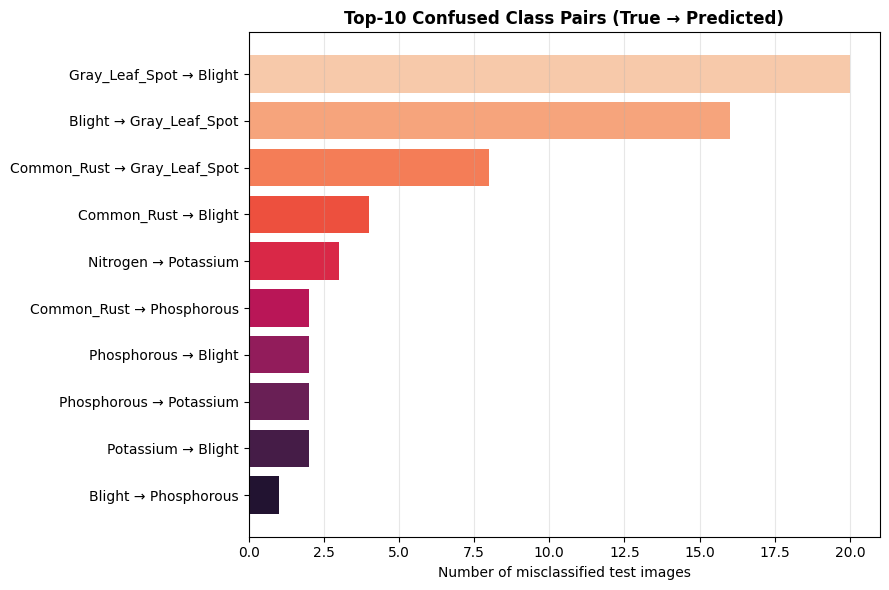

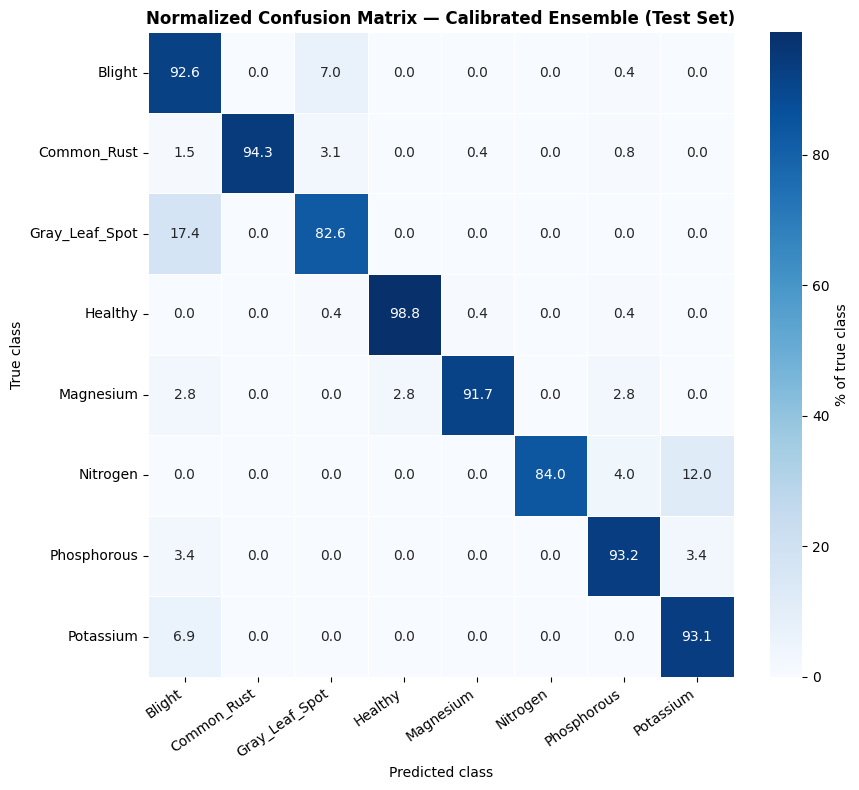

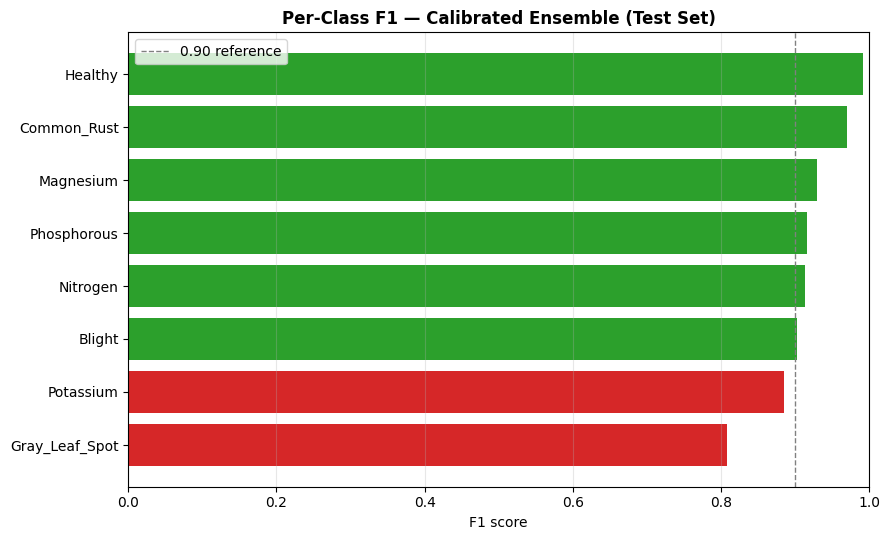

PARAMETER / MODEL-SIZE SUMMARY
CNN backbone (EfficientNetB0 + CBAM + embed head):
  Trainable params     : 2,634,586
  Non-trainable params : 1,998,867
  Total params         : 4,633,453  (~4.63 M)

Ensemble MLP learner:
  Total params         : 60,872

XGBoost model on-disk size  : 1044.3 KB
RandomForest on-disk size  : 6752.9 KB
Meta-LR on-disk size       : 2.4 KB

TOTAL PIPELINE PARAMS (CNN + MLP, NN-countable) : 4,694,325  (~4.69 M)
CNN backbone FLOPs (manual Conv2D/DepthwiseConv2D/Dense estimate, single 224x224 image, 1 forward pass): 770,243,396  (~0.770 GFLOPs)
Layers counted: 87, layers skipped (unbuilt/no io shape): 0
Note: this is an estimate covering the dominant conv/dense layers, not an exact hardware-level profiler measurement -- state that in the paper's complexity section if you report it as-is.
INFERENCE TIME (single image, batch size = 1)
CNN forward pass (image_emb extraction) : 120.99 ms
Ensemble stage (XGB+RF+MLP+meta-LR)     : 230.31 ms
TOTAL END-TO-END LATENCY   

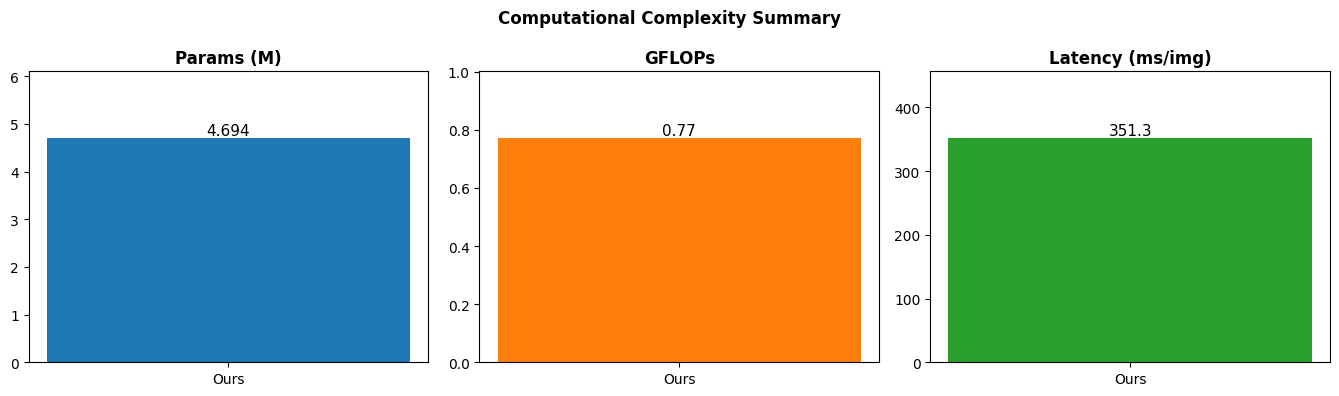

                                 Method  Accuracy (%) Explainability       Calibration               Ensemble Severity staging Params (M)              Source
                  CNDD-Net (literature)         96.71      Attention                 ✗                      ✗                ✗        n/r cite original paper
          PlantVillage CNN (literature)         93.00              ✗                 ✗                      ✗                ✗        n/r cite original paper
Ours (CBAM-EffNetB0 + Stacked Ensemble)         93.21       Grad-CAM ✓ (temp. scaling) ✓ (XGB+RF+MLP+meta-LR)                ✓      4.694           this work

⚠ Replace the literature rows' 'n/r' / accuracy values with numbers actually reported in the papers you cite for CNDD-Net and the PlantVillage CNN baseline before submission.


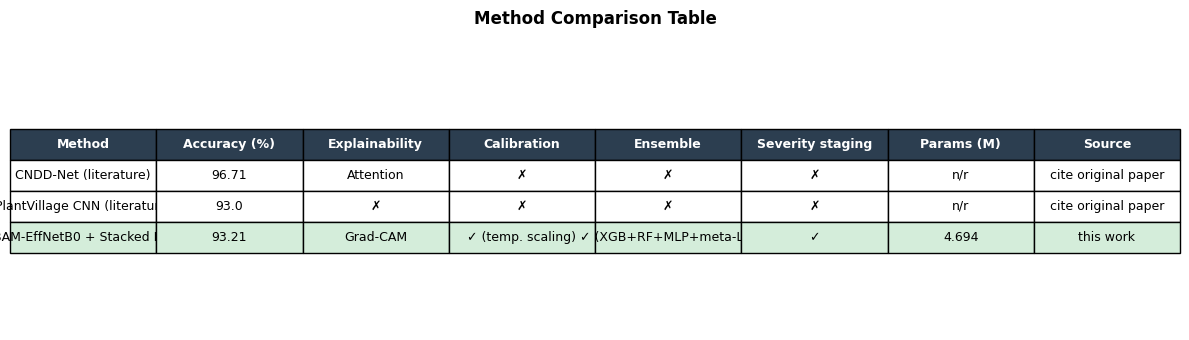


All figures + tables saved to: /kaggle/working/maize_ensemble_output/paper_figures


In [57]:
# CELL 39
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, f1_score

FIG_DIR = os.path.join(ENSEMBLE_OUTPUT_DIR, 'paper_figures')
os.makedirs(FIG_DIR, exist_ok=True)


try:
    y_pred_final = pred_meta_calibrated
except NameError:
    y_pred_final = meta_lr.predict(meta_X_te)

print(f"Using {len(y_pred_final)} test predictions across {N_CLASSES} classes.")


# =============================================================================
# 1) ERROR ANALYSIS — which classes get confused, and why
# =============================================================================

# %% CELL — Error Analysis: top confused class pairs + biological explanation
cm = confusion_matrix(y_te, y_pred_final)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

# Every off-diagonal (true, pred) pair, ranked by how many test images it cost
pairs = []
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        if i != j and cm[i, j] > 0:
            pairs.append((class_names[i], class_names[j], int(cm[i, j]), cm_norm[i, j]))
pairs.sort(key=lambda x: -x[2])
top_pairs = pairs[:10]

# Domain-knowledge explanations for maize disease/deficiency look-alikes.
# Keyed by frozenset({true_class, pred_class}) so direction doesn't matter.
CONFUSION_EXPLANATIONS = {
    frozenset({'Nitrogen', 'Magnesium'}):
        "Both present as leaf chlorosis (yellowing). Nitrogen deficiency starts "
        "as V-shaped yellowing along the midrib of older leaves, while Magnesium "
        "deficiency causes interveinal chlorosis with reddish-purple margins — at "
        "the image-patch level, both reduce to a similar green-to-yellow gradient, "
        "which is the visual cue the CNN backbone relies on most heavily.",
    frozenset({'Potassium', 'Magnesium'}):
        "Potassium deficiency causes marginal chlorosis/necrosis (leaf-edge burn) "
        "while Magnesium deficiency causes interveinal chlorosis nearer the leaf "
        "center. Under variable lighting/angle in field photos, edge and "
        "interveinal chlorotic regions can occupy similar pixel proportions, "
        "confusing the color-index and CNN features alike.",
    frozenset({'Potassium', 'Nitrogen'}):
        "Both deficiencies produce progressive yellowing of older leaves before "
        "necrosis sets in; the main distinguishing cue (edge-first vs midrib-first "
        "progression) is a fine-grained spatial detail that is easy to lose after "
        "224x224 resizing.",
    frozenset({'Common_Rust', 'Blight'}):
        "Common Rust produces small circular/oval reddish-brown pustules, while "
        "Blight (Northern Corn Leaf Blight) produces larger elongated "
        "cigar-shaped necrotic lesions. In early-stage or low-density infections "
        "both appear as scattered reddish-brown spots on a green background, "
        "which is the dominant texture cue the model has learned.",
    frozenset({'Gray_Leaf_Spot', 'Blight'}):
        "Both are necrotic, vein-bounded lesions that run parallel to the leaf "
        "veins. Gray Leaf Spot lesions are narrower and rectangular while Blight "
        "lesions are longer and more tapered, but in later disease stages "
        "adjacent lesions coalesce for both diseases, erasing that shape cue.",
    frozenset({'Gray_Leaf_Spot', 'Common_Rust'}):
        "Both diseases scatter small discrete lesions across the leaf blade; "
        "Gray Leaf Spot's lesions are grayish rather than rust-orange, but under "
        "the dataset's color augmentation and JPEG compression the two are "
        "sometimes hard to separate by color alone.",
    frozenset({'Phosphorous', 'Healthy'}):
        "Phosphorus deficiency causes leaf purpling and darkened green that is "
        "subtler than the chlorosis seen in other deficiencies, so mild cases can "
        "look close to a healthy leaf, especially with natural anthocyanin "
        "pigmentation in some hybrids.",
    frozenset({'Phosphorous', 'Nitrogen'}):
        "Both can co-occur in nutrient-poor soil and both cause older-leaf "
        "discoloration; Phosphorus's purple tinge is subtler than Nitrogen's "
        "yellowing and can be under-weighted by the model relative to the "
        "stronger chlorosis signal.",
}

def explain_pair(true_c, pred_c):
    return CONFUSION_EXPLANATIONS.get(
        frozenset({true_c, pred_c}),
        "No documented visual-symptom overlap for this pair in the literature — "
        "likely a data-quality or lighting/occlusion artifact rather than a "
        "genuine symptom look-alike; worth spot-checking the raw images."
    )

print("=" * 90)
print("TOP CONFUSED CLASS PAIRS (test set)")
print("=" * 90)
rows = []
for true_c, pred_c, count, rate in top_pairs:
    reason = explain_pair(true_c, pred_c)
    print(f"\n{true_c}  →  predicted as {pred_c}   ({count} images, "
          f"{rate*100:.1f}% of all true-{true_c} test images)")
    print(f"   Why: {reason}")
    rows.append({'True class': true_c, 'Predicted as': pred_c,
                 'Count': count, 'Rate (%)': round(rate * 100, 1),
                 'Likely cause': reason})

error_analysis_df = pd.DataFrame(rows)
error_analysis_df.to_csv(os.path.join(FIG_DIR, 'error_analysis_table.csv'), index=False)
error_analysis_df


# %% CELL — Figure: top-10 confused pairs (bar chart, paper-ready)
fig, ax = plt.subplots(figsize=(9, 6))
labels = [f"{t} → {p}" for t, p, c, r in top_pairs]
counts = [c for t, p, c, r in top_pairs]
colors = sns.color_palette('rocket_r', len(top_pairs))
ax.barh(labels[::-1], counts[::-1], color=colors[::-1])
ax.set_xlabel('Number of misclassified test images')
ax.set_title('Top-10 Confused Class Pairs (True → Predicted)', fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_top_confused_pairs.png'), dpi=300)
plt.show()


# %% CELL — Figure: row-normalized confusion matrix (percentages, for the paper)
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(cm_norm * 100, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5, cbar_kws={'label': '% of true class'}, ax=ax)
ax.set_xlabel('Predicted class'); ax.set_ylabel('True class')
ax.set_title('Normalized Confusion Matrix — Calibrated Ensemble (Test Set)',
             fontweight='bold')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_confusion_matrix_normalized.png'), dpi=300)
plt.show()


# %% CELL — Figure: per-class F1 score (shows exactly where the model struggles)
per_class_f1 = f1_score(y_te, y_pred_final, average=None, labels=list(range(N_CLASSES)))
f1_order = np.argsort(per_class_f1)
fig, ax = plt.subplots(figsize=(9, 5.5))
bar_colors = ['#d62728' if f < 0.90 else '#2ca02c' for f in per_class_f1[f1_order]]
ax.barh([class_names[i] for i in f1_order], per_class_f1[f1_order], color=bar_colors)
ax.set_xlim(0, 1.0)
ax.set_xlabel('F1 score')
ax.set_title('Per-Class F1 — Calibrated Ensemble (Test Set)', fontweight='bold')
ax.axvline(0.90, color='gray', linestyle='--', linewidth=1, label='0.90 reference')
ax.legend()
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_per_class_f1.png'), dpi=300)
plt.show()


# =============================================================================
# 2) COMPUTATIONAL COMPLEXITY — params, FLOPs, inference time
# =============================================================================

# %% CELL — Parameter counts (CNN backbone + full pipeline)
def count_params(model):
    trainable = int(np.sum([tf.keras.backend.count_params(w) for w in model.trainable_weights]))
    non_trainable = int(np.sum([tf.keras.backend.count_params(w) for w in model.non_trainable_weights]))
    return trainable, non_trainable, trainable + non_trainable

cnn_trainable, cnn_nontrainable, cnn_total = count_params(image_model)

# Ensemble-stage parameter counts (sklearn/XGBoost models don't expose
# "parameters" the way NNs do, so we report their size on disk instead,
# plus the MLP's true parameter count).
mlp_trainable, mlp_nontrainable, mlp_total = count_params(mlp_model)

import joblib, pickle
def model_disk_size_kb(obj, path):
    joblib.dump(obj, path)
    size_kb = os.path.getsize(path) / 1024
    os.remove(path)
    return size_kb

xgb_kb = model_disk_size_kb(xgb_model, '/tmp/_tmp_xgb.pkl')
rf_kb = model_disk_size_kb(rf_model, '/tmp/_tmp_rf.pkl')
meta_kb = model_disk_size_kb(meta_lr, '/tmp/_tmp_meta.pkl')

print("=" * 60)
print("PARAMETER / MODEL-SIZE SUMMARY")
print("=" * 60)
print(f"CNN backbone (EfficientNetB0 + CBAM + embed head):")
print(f"  Trainable params     : {cnn_trainable:,}")
print(f"  Non-trainable params : {cnn_nontrainable:,}")
print(f"  Total params         : {cnn_total:,}  (~{cnn_total/1e6:.2f} M)")
print(f"\nEnsemble MLP learner:")
print(f"  Total params         : {mlp_total:,}")
print(f"\nXGBoost model on-disk size  : {xgb_kb:.1f} KB")
print(f"RandomForest on-disk size  : {rf_kb:.1f} KB")
print(f"Meta-LR on-disk size       : {meta_kb:.1f} KB")
print(f"\nTOTAL PIPELINE PARAMS (CNN + MLP, NN-countable) : "
      f"{cnn_total + mlp_total:,}  (~{(cnn_total+mlp_total)/1e6:.2f} M)")


def _get_io_shapes(layer):
    inp, out = layer.input, layer.output
    if isinstance(inp, (list, tuple)):
        inp = inp[0]
    if isinstance(out, (list, tuple)):
        out = out[0]
    return tuple(inp.shape), tuple(out.shape)

def estimate_flops_manual(model):
    total = 0
    counted, skipped = 0, 0

    def walk(m):
        nonlocal total, counted, skipped
        for layer in m.layers:
            # Recurse into nested models (e.g. EfficientNetB0 as a sub-model) --
            # model.layers does NOT descend into these automatically, and
            # skipping this step would silently drop ~100+ conv layers.
            if isinstance(layer, tf.keras.Model):
                walk(layer)
                continue
            cfg = layer.get_config()
            try:
                if isinstance(layer, tf.keras.layers.DepthwiseConv2D):
                    in_shape, out_shape = _get_io_shapes(layer)
                    _, h, w, out_ch = out_shape
                    kh, kw = cfg['kernel_size']
                    macs = h * w * out_ch * kh * kw
                    total += 2 * macs
                    counted += 1
                elif isinstance(layer, tf.keras.layers.Conv2D):
                    in_shape, out_shape = _get_io_shapes(layer)
                    _, h, w, out_ch = out_shape
                    kh, kw = cfg['kernel_size']
                    in_ch = in_shape[-1]
                    groups = cfg.get('groups', 1) or 1
                    macs = h * w * out_ch * kh * kw * (in_ch / groups)
                    total += 2 * macs
                    counted += 1
                elif isinstance(layer, tf.keras.layers.Dense):
                    in_shape, out_shape = _get_io_shapes(layer)
                    in_dim = in_shape[-1]
                    out_dim = layer.units
                    total += 2 * in_dim * out_dim
                    counted += 1
            except Exception:
                skipped += 1
                continue

    walk(model)
    return total, counted, skipped

gflops = None
try:
    total_flops, n_counted, n_skipped = estimate_flops_manual(image_model)
    gflops = total_flops / 1e9
    print(f"CNN backbone FLOPs (manual Conv2D/DepthwiseConv2D/Dense estimate, "
          f"single 224x224 image, 1 forward pass): {total_flops:,.0f}  "
          f"(~{gflops:.3f} GFLOPs)")
    print(f"Layers counted: {n_counted}, layers skipped (unbuilt/no io shape): {n_skipped}")
    print("Note: this is an estimate covering the dominant conv/dense layers, "
          "not an exact hardware-level profiler measurement -- state that in "
          "the paper's complexity section if you report it as-is.")
except Exception as e:
    print(f"Manual FLOPs estimate failed too ({e}). "
          f"Report params + measured latency only, and note FLOPs as "
          f"'not reliably computable in this environment' rather than guessing.")


# %% CELL — Inference time benchmark (CNN forward pass + full ensemble pipeline)
N_WARMUP = 10
N_TIMED = 100

dummy_img = np.random.rand(1, IMG_SIZE, IMG_SIZE, 3).astype(np.float32)
dummy_emb = np.random.rand(1, EMBED_DIM).astype(np.float32)

# -- CNN embedding extraction --
for _ in range(N_WARMUP):
    _ = embed_model.predict(dummy_img, verbose=0)
t0 = time.perf_counter()
for _ in range(N_TIMED):
    _ = embed_model.predict(dummy_img, verbose=0)
cnn_ms = (time.perf_counter() - t0) / N_TIMED * 1000

# -- Ensemble stage (XGB + RF + MLP + meta-LR) on a precomputed embedding --
for _ in range(N_WARMUP):
    p_x = xgb_model.predict_proba(dummy_emb)
    p_r = rf_model.predict_proba(dummy_emb)
    p_m = mlp_model.predict(dummy_emb, verbose=0)
t0 = time.perf_counter()
for _ in range(N_TIMED):
    p_x = xgb_model.predict_proba(dummy_emb)
    p_r = rf_model.predict_proba(dummy_emb)
    p_m = mlp_model.predict(dummy_emb, verbose=0)
    _ = meta_lr.predict_proba(np.hstack([p_x, p_r, p_m]))
ensemble_ms = (time.perf_counter() - t0) / N_TIMED * 1000

total_ms = cnn_ms + ensemble_ms

print("=" * 60)
print("INFERENCE TIME (single image, batch size = 1)")
print("=" * 60)
print(f"CNN forward pass (image_emb extraction) : {cnn_ms:.2f} ms")
print(f"Ensemble stage (XGB+RF+MLP+meta-LR)     : {ensemble_ms:.2f} ms")
print(f"TOTAL END-TO-END LATENCY                : {total_ms:.2f} ms")
print(f"Throughput                              : {1000/total_ms:.1f} images/sec")
print("\nNote: TTA (original + flipped) used at real inference roughly doubles "
      "the CNN component above; report both single-pass and TTA numbers if "
      "your predict_image() uses TTA in production.")

complexity_summary = {
    'total_params_M': round((cnn_total + mlp_total) / 1e6, 3),
    'cnn_backbone_params_M': round(cnn_total / 1e6, 3),
    'gflops': round(gflops, 3) if gflops else None,
    'inference_ms_per_image': round(total_ms, 2),
    'throughput_img_per_sec': round(1000 / total_ms, 1),
}
with open(os.path.join(FIG_DIR, 'complexity_summary.json'), 'w') as f:
    json.dump(complexity_summary, f, indent=2)
print("\nSaved:", os.path.join(FIG_DIR, 'complexity_summary.json'))
print(complexity_summary)


# %% CELL — Figure: complexity vs accuracy tradeoff bar chart (handles missing metrics)
metrics = [
    ('Params (M)', complexity_summary['total_params_M'], 'tab:blue'),
    ('GFLOPs', complexity_summary['gflops'], 'tab:orange'),
    ('Latency (ms/img)', complexity_summary['inference_ms_per_image'], 'tab:green'),
]
# Only plot metrics that actually have a numeric value (skips GFLOPs
# gracefully if both keras-flops and the manual fallback ever fail)
plot_metrics = [(label, value, color) for label, value, color in metrics if value is not None]
skipped = [label for label, value, _ in metrics if value is None]

fig, axes = plt.subplots(1, len(plot_metrics), figsize=(4.5 * len(plot_metrics), 4))
if len(plot_metrics) == 1:
    axes = [axes]

for ax, (label, value, color) in zip(axes, plot_metrics):
    ax.bar(['Ours'], [value], color=color)
    ax.set_title(label, fontweight='bold')
    ax.text(0, value, f"{value}", ha='center', va='bottom', fontsize=11)
    ax.set_ylim(0, value * 1.3 if value else 1)

plt.suptitle('Computational Complexity Summary', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_computational_complexity.png'), dpi=300)
plt.show()

if skipped:
    print(f"Skipped in the figure (no value available): {skipped}")


comparison_rows = [
    # method, accuracy(%), explainability, calibration, ensemble, severity, params(M), source
    {'Method': 'CNDD-Net (literature)', 'Accuracy (%)': 96.71,
     'Explainability': 'Attention', 'Calibration': '✗', 'Ensemble': '✗',
     'Severity staging': '✗', 'Params (M)': 'n/r', 'Source': 'cite original paper'},
    {'Method': 'PlantVillage CNN (literature)', 'Accuracy (%)': 93.00,
     'Explainability': '✗', 'Calibration': '✗', 'Ensemble': '✗',
     'Severity staging': '✗', 'Params (M)': 'n/r', 'Source': 'cite original paper'},
    {'Method': 'Ours (CBAM-EffNetB0 + Stacked Ensemble)',
     'Accuracy (%)': round(meta_test_acc * 100, 2),
     'Explainability': 'Grad-CAM', 'Calibration': '✓ (temp. scaling)',
     'Ensemble': '✓ (XGB+RF+MLP+meta-LR)', 'Severity staging': '✓',
     'Params (M)': complexity_summary['total_params_M'], 'Source': 'this work'},
]
comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(os.path.join(FIG_DIR, 'comparison_table.csv'), index=False)
print(comparison_df.to_string(index=False))
print("\n⚠ Replace the literature rows' 'n/r' / accuracy values with numbers "
      "actually reported in the papers you cite for CNDD-Net and the "
      "PlantVillage CNN baseline before submission.")
comparison_df


fig, ax = plt.subplots(figsize=(12, 2 + 0.5 * len(comparison_df)))
ax.axis('off')
tbl = ax.table(cellText=comparison_df.values, colLabels=comparison_df.columns,
               cellLoc='center', loc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.8)
for (row, col), cell in tbl.get_celld().items():
    if row == 0:
        cell.set_text_props(fontweight='bold', color='white')
        cell.set_facecolor('#2c3e50')
    elif comparison_df.iloc[row - 1]['Source'] == 'this work':
        cell.set_facecolor('#d4edda')
plt.title('Method Comparison Table', fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_comparison_table.png'), dpi=300, bbox_inches='tight')
plt.show()

print(f"\nAll figures + tables saved to: {FIG_DIR}")

In [62]:
from IPython.display import display, HTML

file_path = "/kaggle/working/maize_model_outputs.zip"

display(HTML(f'''
<a href="/kaggle/working/maize_model_outputs.zip" download>
    <button>Download maize_model_outputs.zip</button>
</a>
'''))